# <font color = 'bargandi'> Credit Card spending prediction</font>

## <font color='green'> Spending with credit cards</font>

While there are benefits to paying with a credit card - such as earning rewards and building credit - they
do not account for the enormous premium that consumers seem willing to pay. While there are no definitive
answers that explain this phenomenon, there are several popular theories that have emerged over the years.


### <font color='green'>Credit Card Shoppers Focus More on Benefits Than Costs</font>

There has been evidence that shows when customers use credit cards, they tend to focus on product's benefits
than its costs. Credit card users were 28% better at recalling aspects related to product's benefits
than cash users. Conversely, cash users were 82% better at recalling aspects related to item's cost
than credit card users.



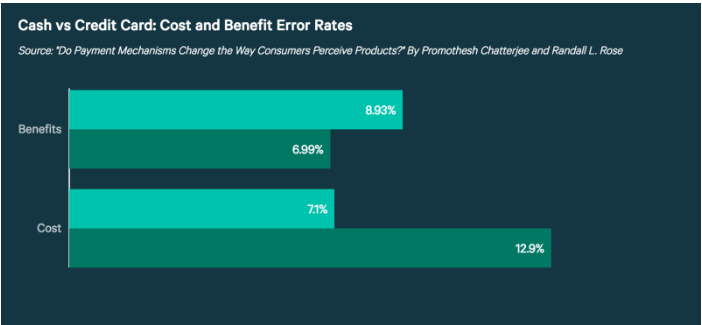

In [187]:
from IPython.display import Image
Image(r'C:\Users\Dad\Documents\Data Tales\Amex Hackathon\Pic1.png')


### *find some way to change the path of images. Also keep images in the folder always. 

### <font color='green'> People Are Using Credit Cards Now More Than Ever </font>

### *green doesn't seem great. Blue ? or Red as usual ?

With such an increase in credit card and remote transactions, it's important for consumers to be aware of
how their payment choice might affect their spending. This doesn't mean you shouldn't use a credit card. However,
it does mean consumers should make an effort to be especially cognizant of their choices when using a 
credit card or shopping online.

### <font color='green'> Problem Statement</font>

We will be estimating the pattern of credit cards being spent by the cardholders for the next 3 months
based on the age of the consumers, debit cards / credit cards spending rate,number of transactions being carried out by them, emi active for cardholders. 

### <font color='green'> Data Analysis</font>

In [1]:
# Importing required libraries
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import numpy as np
import warnings 
warnings.simplefilter(action='ignore', category = FutureWarning)
warnings.simplefilter(action='ignore', category = DeprecationWarning)
warnings.simplefilter(action='ignore', category = UserWarning)
import missingno as msno
from collections import Counter
import itertools

### <font color='green'> Load and explore dataset</font>

Let us explore the credit card spent dataset 

In [4]:
cc_spent_train = pd.read_csv(r'C:\Users\Prudhvi\repos\data tales\DT-Amex-hackathon\train.csv')

In [6]:
pd.set_option('display.max_columns',45)
cc_spent_train.head()

,id,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,investment_3,investment_4,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
0,23334,saving,M,63,305,7695.00,NaN,479.00,NaN,622.0,NaN,2.0,1.0,3.0,NaN,NaN,NaN,150000.0,NaN,NaN,NaN,NaN,NaN,118845.2,50000.0,NaN,51205.47,50259.0,3.0,1.0,50000.0,24740.22,114252.0,3.0,2.0,45000.0,20215.85,1279.37,7.0,3.0,470.0,NaN,0.00,435
1,20329,current,M,33,326,52702.00,988.72,29873.00,NaN,1087.0,2806.24,11.0,14.0,11.0,1.0,NaN,6.0,176000.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,NaN,4963.33,1921
2,17679,current,M,44,264,10800.49,3215.52,21659.64,1607.0,1168.0,355.00,6.0,9.0,6.0,3.0,2.0,14.0,65000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,NaN,0.00,1970
3,16428,saving,M,44,233,20936.00,NaN,2094.00,NaN,11778.5,NaN,9.0,6.0,6.0,NaN,NaN,NaN,600000.0,NaN,NaN,NaN,NaN,NaN,132442.0,NaN,NaN,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,NaN,1238.18,21579
4,18721,saving,F,35,324,1183.83,NaN,3656.29,NaN,945.0,NaN,2.0,7.0,9.0,NaN,NaN,NaN,100000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,NaN,0.00,1814


Let us look into the shape of data

In [22]:
cc_spent_train.shape

(32820, 44)

Now, we wil look into the Test data as well

In [23]:
cc_spent_test = pd.read_csv(r'C:\Users\Prudhvi\repos\data tales\DT-Amex-hackathon\test.csv')

In [24]:
cc_spent_test.shape

(14067, 43)

In [25]:
cc_spent = pd.concat([cc_spent_train, cc_spent_test])
cc_spent.head()

,account_type,age,card_lim,cc_cons,cc_cons_apr,cc_cons_jun,cc_cons_may,cc_count_apr,cc_count_jun,cc_count_may,credit_amount_apr,credit_amount_jun,credit_amount_may,credit_count_apr,credit_count_jun,credit_count_may,dc_cons_apr,dc_cons_jun,dc_cons_may,dc_count_apr,dc_count_jun,dc_count_may,debit_amount_apr,debit_amount_jun,debit_amount_may,debit_count_apr,debit_count_jun,debit_count_may,emi_active,gender,id,investment_1,investment_2,investment_3,investment_4,loan_enq,max_credit_amount_apr,max_credit_amount_jun,max_credit_amount_may,personal_loan_active,personal_loan_closed,region_code,vehicle_loan_active,vehicle_loan_closed
0,saving,63,150000.0,435.0,7695.00,622.0,479.00,2.0,3.0,1.0,50259.0,1279.37,114252.0,1.0,7.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,51205.47,20215.85,24740.22,3.0,3.0,2.0,0.00,M,23334,NaN,118845.2,50000.0,NaN,NaN,50000.0,470.0,45000.0,NaN,NaN,305,NaN,NaN
1,current,33,176000.0,1921.0,52702.00,1087.0,29873.00,11.0,11.0,14.0,169812.0,55390.00,174606.0,9.0,8.0,6.0,988.72,2806.24,NaN,1.0,6.0,NaN,159050.76,122037.66,103102.85,20.0,19.0,10.0,4963.33,M,20329,NaN,NaN,NaN,NaN,NaN,70000.0,27000.0,150000.0,NaN,1.0,326,NaN,NaN
2,current,44,65000.0,1970.0,10800.49,1168.0,21659.64,6.0,6.0,9.0,38942.0,29297.91,23051.0,4.0,6.0,2.0,3215.52,355.00,1607.0,3.0,14.0,2.0,51484.55,46827.00,15283.00,16.0,19.0,7.0,0.00,M,17679,NaN,NaN,NaN,NaN,NaN,11700.0,20800.0,13800.0,NaN,NaN,264,NaN,NaN
3,saving,44,600000.0,21579.0,20936.00,11778.5,2094.00,9.0,6.0,6.0,2294.0,7544.00,19529.0,1.0,3.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1981.07,5426.55,19361.24,2.0,1.0,1.0,1238.18,M,16428,NaN,132442.0,NaN,NaN,NaN,2000.0,5300.0,19300.0,NaN,NaN,233,NaN,NaN
4,saving,35,100000.0,1814.0,1183.83,945.0,3656.29,2.0,9.0,7.0,10271.0,53483.00,3194.0,1.0,4.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,6462.00,26178.05,7461.00,6.0,4.0,3.0,0.00,F,18721,NaN,NaN,NaN,NaN,NaN,10000.0,45000.0,3000.0,NaN,NaN,324,NaN,NaN


In [26]:
cc_spent.columns

Index(['account_type', 'age', 'card_lim', 'cc_cons', 'cc_cons_apr',
       'cc_cons_jun', 'cc_cons_may', 'cc_count_apr', 'cc_count_jun',
       'cc_count_may', 'credit_amount_apr', 'credit_amount_jun',
       'credit_amount_may', 'credit_count_apr', 'credit_count_jun',
       'credit_count_may', 'dc_cons_apr', 'dc_cons_jun', 'dc_cons_may',
       'dc_count_apr', 'dc_count_jun', 'dc_count_may', 'debit_amount_apr',
       'debit_amount_jun', 'debit_amount_may', 'debit_count_apr',
       'debit_count_jun', 'debit_count_may', 'emi_active', 'gender', 'id',
       'investment_1', 'investment_2', 'investment_3', 'investment_4',
       'loan_enq', 'max_credit_amount_apr', 'max_credit_amount_jun',
       'max_credit_amount_may', 'personal_loan_active', 'personal_loan_closed',
       'region_code', 'vehicle_loan_active', 'vehicle_loan_closed'],
      dtype='object')

#### <font color='green'> Understanding features </font>

- id : Unique ID for every Customer
- account_type : Account Type – current or saving
- gender : Gender of customer
- age : Age of customer
- region_code : Code assigned to region of residence (has order)
- cc_cons_apr : Credit card spend in April
- dc_cons_apr : Debit card spend in April
- cc_cons_may : Credit card spend in May
- dc_cons_may : Debit card spend in May
- cc_cons_jun : Credit card spend in June
- dc_cons_jun : Debit card spend in June
- cc_count_apr: Number of credit card transactions in April
- cc_count_may: Number of credit card transactions in May
- cc_count_jun: Number of credit card transactions in June
- dc_count_apr: Number of debit card transactions in April
- dc_count_may: Number of debit card transactions in May
- dc_count_jun: Number of debit card transactions in June
- card_lim    :Maximum Credit Card Limit allocated
- personal_loan_active : Active personal loan with other bank
- vehicle_loan_active  : Active Vehicle loan with other bank
- personal_loan_closed : Closed personal loan in last 12 months
- vehicle_loan_closed  : Closed vehicle loan in last 12 months
- investment_1 : DEMAT investment in june
    ( A Demat Account holds all the investments an individual makes in shares, govt. securities, exchange-
     traded funds, bonds and mututal funds in one place).
- investment_2 : fixed deposit investment in june
- investment_3 : Life Insurance investment in June
- investment_4 : General Insurance Investment in June
- debit_amount_apr : Total amount debited for April
- credit_amount_apr : Total amount credited for April
- debit_count_apr : Total number of times amount debited in april
- credit_count_apr : Total number of times amount credited in april
- max_credit_amount_apr : Maximum amount credited in April
- debit_amount_may : Total amount debited for May
- credit_amount_may : Total amount credited for May
- credit_count_may : Total number of times amount credited in May
- debit_count_may : Total number of times amount debited in May
- max_credit_amount_may : Maximum amount credited in May
- debit_amount_jun : Total amount debited for June
- credit_amount_jun : Total amount credited for June
- credit_count_jun : Total number of times amount credited in June
- debit_count_jun : Total number of times amount debited in June
- max_credit_amount_jun : Maximum amount credited in June
- loan_enq : Loan enquiry in last 3 months
- emi_active : Monthly EMI paid to other bank for active loans
- cc_cons : (Target) Average Credit Card Spend in next three months


Knowing the data types, memory size of the data through info() function

In [16]:
cc_spent.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 46887 entries, 0 to 14066
Data columns (total 44 columns):
account_type             46887 non-null object
age                      46887 non-null int64
card_lim                 46875 non-null float64
cc_cons                  32820 non-null float64
cc_cons_apr              46887 non-null float64
cc_cons_jun              46887 non-null float64
cc_cons_may              46887 non-null float64
cc_count_apr             43450 non-null float64
cc_count_jun             44663 non-null float64
cc_count_may             45192 non-null float64
credit_amount_apr        42120 non-null float64
credit_amount_jun        44681 non-null float64
credit_amount_may        41987 non-null float64
credit_count_apr         44341 non-null float64
credit_count_jun         44704 non-null float64
credit_count_may         43919 non-null float64
dc_cons_apr              19605 non-null float64
dc_cons_jun              16526 non-null float64
dc_cons_may              22173

There are 3 data types which are mainly used here i.e. float , int and object data type.

In [18]:
cc_spent.describe().T

,count,mean,std,min,25%,50%,75%,max
age,46887.0,35.945678,8.434601e+00,22.00,31.000,34.000,39.0000,2.240000e+02
card_lim,46875.0,121410.945749,1.229824e+05,0.00,45000.000,75000.000,145000.0000,1.350000e+06
cc_cons,32820.0,6824.631840,1.245914e+04,0.00,1285.000,3141.000,7349.2500,4.086300e+05
cc_cons_apr,46887.0,16589.430023,2.491871e+04,233.97,3690.000,8897.500,19920.9450,8.047126e+05
cc_cons_jun,46887.0,8944.150405,1.564884e+04,51.00,1626.305,4109.000,10012.5475,4.295224e+05
cc_cons_may,46887.0,14335.412564,2.323877e+04,103.00,2970.795,7337.000,16804.7850,1.117246e+06
cc_count_apr,43450.0,9.165386,1.018436e+01,1.00,3.000,7.000,12.0000,1.012000e+03
cc_count_jun,44663.0,12.324362,1.154924e+01,1.00,4.000,9.000,17.0000,6.530000e+02
cc_count_may,45192.0,9.549522,9.465068e+00,1.00,3.000,7.000,13.0000,6.010000e+02
credit_amount_apr,42120.0,74993.286848,1.658658e+05,24.00,25387.125,44033.000,79209.0550,1.310058e+07


From the describe() function, we get the interquantile range from 25% to 75% in which the data points lie the most. If there is any huge deviation among max values, there are high chances of outliers in it.
Also , if the count value is not same across all columns, the column has missing values present in it.

Also , the column "id" doesn't help us in analysis of data. Hence, we will drop the column.

### *id will be used as reference later. We need to hold it. It's unique point with whichw e connect to other databases

In [19]:
cc_spent = cc_spent.drop(["id"], axis=1)

In [20]:
cc_spent.head()

,account_type,age,card_lim,cc_cons,cc_cons_apr,cc_cons_jun,cc_cons_may,cc_count_apr,cc_count_jun,cc_count_may,credit_amount_apr,credit_amount_jun,credit_amount_may,credit_count_apr,credit_count_jun,credit_count_may,dc_cons_apr,dc_cons_jun,dc_cons_may,dc_count_apr,dc_count_jun,dc_count_may,debit_amount_apr,debit_amount_jun,debit_amount_may,debit_count_apr,debit_count_jun,debit_count_may,emi_active,gender,investment_1,investment_2,investment_3,investment_4,loan_enq,max_credit_amount_apr,max_credit_amount_jun,max_credit_amount_may,personal_loan_active,personal_loan_closed,region_code,vehicle_loan_active,vehicle_loan_closed
0,saving,63,150000.0,435.0,7695.00,622.0,479.00,2.0,3.0,1.0,50259.0,1279.37,114252.0,1.0,7.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,51205.47,20215.85,24740.22,3.0,3.0,2.0,0.00,M,NaN,118845.2,50000.0,NaN,NaN,50000.0,470.0,45000.0,NaN,NaN,305,NaN,NaN
1,current,33,176000.0,1921.0,52702.00,1087.0,29873.00,11.0,11.0,14.0,169812.0,55390.00,174606.0,9.0,8.0,6.0,988.72,2806.24,NaN,1.0,6.0,NaN,159050.76,122037.66,103102.85,20.0,19.0,10.0,4963.33,M,NaN,NaN,NaN,NaN,NaN,70000.0,27000.0,150000.0,NaN,1.0,326,NaN,NaN
2,current,44,65000.0,1970.0,10800.49,1168.0,21659.64,6.0,6.0,9.0,38942.0,29297.91,23051.0,4.0,6.0,2.0,3215.52,355.00,1607.0,3.0,14.0,2.0,51484.55,46827.00,15283.00,16.0,19.0,7.0,0.00,M,NaN,NaN,NaN,NaN,NaN,11700.0,20800.0,13800.0,NaN,NaN,264,NaN,NaN
3,saving,44,600000.0,21579.0,20936.00,11778.5,2094.00,9.0,6.0,6.0,2294.0,7544.00,19529.0,1.0,3.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1981.07,5426.55,19361.24,2.0,1.0,1.0,1238.18,M,NaN,132442.0,NaN,NaN,NaN,2000.0,5300.0,19300.0,NaN,NaN,233,NaN,NaN
4,saving,35,100000.0,1814.0,1183.83,945.0,3656.29,2.0,9.0,7.0,10271.0,53483.00,3194.0,1.0,4.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,6462.00,26178.05,7461.00,6.0,4.0,3.0,0.00,F,NaN,NaN,NaN,NaN,NaN,10000.0,45000.0,3000.0,NaN,NaN,324,NaN,NaN


Shape of "cc_spent" dataframe on dropping "id" column

### <font color='green'> Data Cleaning</font>

Evaluating the null values present in the dataframe

In [21]:
cc_spent.isnull().sum()

account_type                 0
age                          0
card_lim                    12
cc_cons                  14067
cc_cons_apr                  0
cc_cons_jun                  0
cc_cons_may                  0
cc_count_apr              3437
cc_count_jun              2224
cc_count_may              1695
credit_amount_apr         4767
credit_amount_jun         2206
credit_amount_may         4900
credit_count_apr          2546
credit_count_jun          2183
credit_count_may          2968
dc_cons_apr              27282
dc_cons_jun              30361
dc_cons_may              24714
dc_count_apr             27282
dc_count_jun             22049
dc_count_may             24714
debit_amount_apr          2737
debit_amount_jun          3140
debit_amount_may          3302
debit_count_apr           2546
debit_count_jun           2183
debit_count_may           2968
emi_active                   0
gender                       0
investment_1             44811
investment_2             43522
investme

<b><font color='green'> Visualization of Missing Numbers</font></b>

We will be visualizing the null values in missing numbers using "missingno".

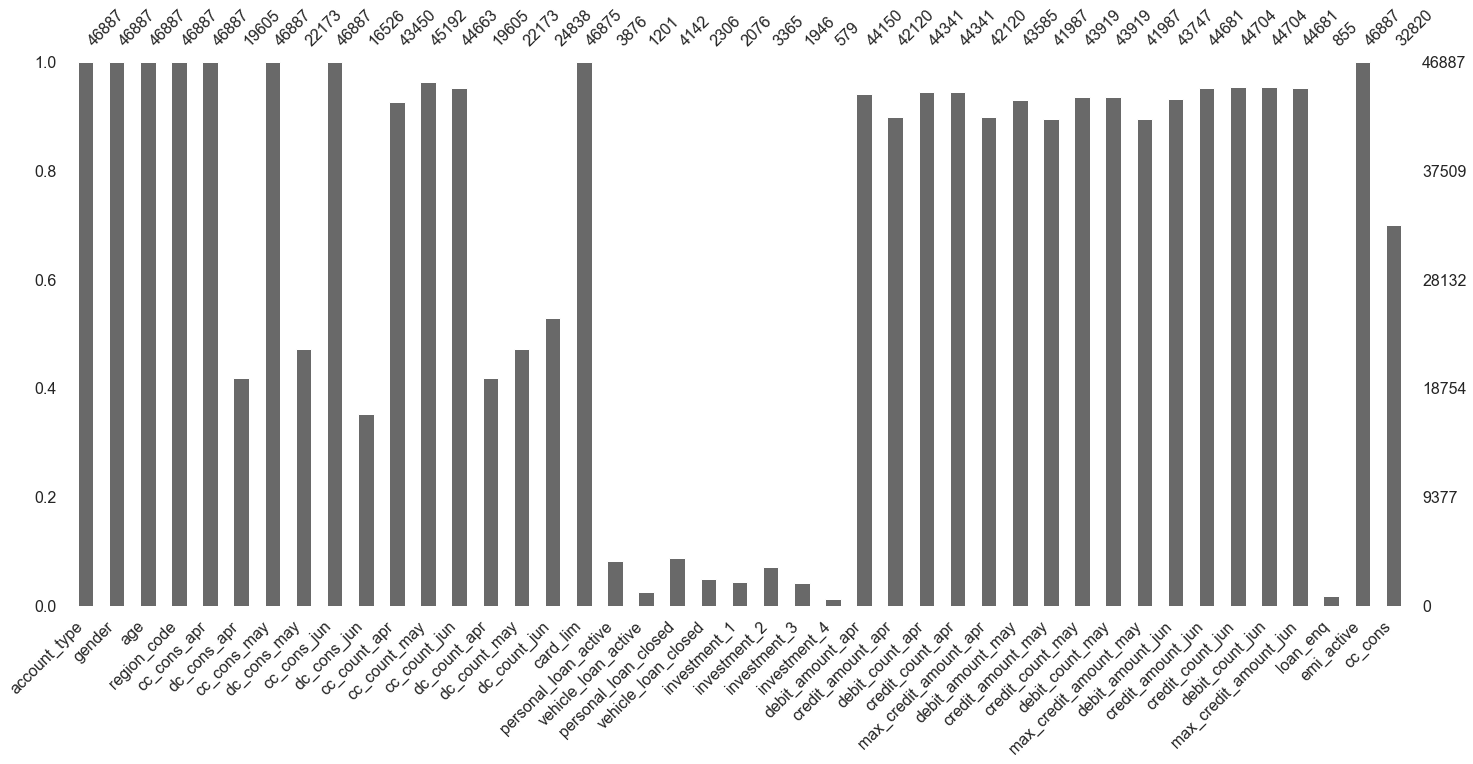

In [201]:
msno.bar(cc_spent)
plt.show()

Above graph symbolizes missing values in Debit_card spent / No of transactions / Amount spend in Debit and Credit card in the months of April, May and June. 
Credit Card limit has null values in it.The values for personal_loan and vehicle_loan with other banks are not captured properly so we need to either impute or delete the columns.
The features demat_investment, fixed deposits, life insurance and general insurance also contain
missing values in it. Lastly, loan enquiry status also possess null values.


Seeing so many missing values, looks like we need to emphasize more on the data cleaning stage.

On observation of the features, we see the debit and credit amount spent, no of times amount debited/credited,
no of transactions done are being listed for each month namely April, May and June seperately. So , we can club
together all the months by using the average method.

Finding Means, Standard deviation and variance of Credit / Debit Spent, No of credit / debit transactions
and Maximum credit card allocated

Let us check the feature importance of features having null values in them.The features possessing
null values and of less importance would be eliminated from the data. For finding out feature importance
we need a ML model such as Decision Tree, Random Forest for implementation of data. Here, we will be
using Decision Tree model to get the feature importances.

In [27]:
# Copying data 'cc_spent' to data 'credit_sp'

credit_sp = cc_spent
""" use deepcopy  """ 

# Splitting target from features while building model into X and Y variables where, X is features
# and Y is the Target
Y = credit_sp['cc_cons']
credit_sp = credit_sp.drop(['cc_cons'], axis=1)
X  = credit_sp

In [28]:
# Imputing null values in the features with the mean imputation for numerical features
X = X.fillna(X.mean())

# Imputing null values for categorical features with mode 
X['loan_enq'] = X.fillna(X.mode().iloc[0])

### why mean directly

Let us create dummy variables from the features

In [29]:
X = pd.get_dummies(X)
X.head()

,age,card_lim,cc_cons_apr,cc_cons_jun,cc_cons_may,cc_count_apr,cc_count_jun,cc_count_may,credit_amount_apr,credit_amount_jun,credit_amount_may,credit_count_apr,credit_count_jun,credit_count_may,dc_cons_apr,dc_cons_jun,dc_cons_may,dc_count_apr,dc_count_jun,dc_count_may,debit_amount_apr,debit_amount_jun,...,debit_count_jun,debit_count_may,emi_active,id,investment_1,investment_2,investment_3,investment_4,max_credit_amount_apr,max_credit_amount_jun,max_credit_amount_may,personal_loan_active,personal_loan_closed,region_code,vehicle_loan_active,vehicle_loan_closed,account_type_current,account_type_saving,gender_F,gender_M,loan_enq_current,loan_enq_saving
0,63,150000.0,7695.00,622.0,479.00,2.0,3.0,1.0,50259.0,1279.37,114252.0,1.0,7.0,3.0,5675.813594,4645.834573,5652.441187,5.263096,7.885941,6.270013,51205.47,20215.85,...,3.0,2.0,0.00,23334,978289.873958,118845.200000,50000.000000,4757.864336,50000.0,470.0,45000.0,1.0,1.0,305,1.0,1.0,0,1,0,1,0,1
1,33,176000.0,52702.00,1087.0,29873.00,11.0,11.0,14.0,169812.0,55390.00,174606.0,9.0,8.0,6.0,988.720000,2806.240000,5652.441187,1.000000,6.000000,6.270013,159050.76,122037.66,...,19.0,10.0,4963.33,20329,978289.873958,167886.083649,41331.507562,4757.864336,70000.0,27000.0,150000.0,1.0,1.0,326,1.0,1.0,1,0,0,1,1,0
2,44,65000.0,10800.49,1168.0,21659.64,6.0,6.0,9.0,38942.0,29297.91,23051.0,4.0,6.0,2.0,3215.520000,355.000000,1607.000000,3.000000,14.000000,2.000000,51484.55,46827.00,...,19.0,7.0,0.00,17679,978289.873958,167886.083649,41331.507562,4757.864336,11700.0,20800.0,13800.0,1.0,1.0,264,1.0,1.0,1,0,0,1,1,0
3,44,600000.0,20936.00,11778.5,2094.00,9.0,6.0,6.0,2294.0,7544.00,19529.0,1.0,3.0,1.0,5675.813594,4645.834573,5652.441187,5.263096,7.885941,6.270013,1981.07,5426.55,...,1.0,1.0,1238.18,16428,978289.873958,132442.000000,41331.507562,4757.864336,2000.0,5300.0,19300.0,1.0,1.0,233,1.0,1.0,0,1,0,1,0,1
4,35,100000.0,1183.83,945.0,3656.29,2.0,9.0,7.0,10271.0,53483.00,3194.0,1.0,4.0,2.0,5675.813594,4645.834573,5652.441187,5.263096,7.885941,6.270013,6462.00,26178.05,...,4.0,3.0,0.00,18721,978289.873958,167886.083649,41331.507562,4757.864336,10000.0,45000.0,3000.0,1.0,1.0,324,1.0,1.0,0,1,1,0,0,1


Recipe to check for variable importance

In [30]:
from sklearn.tree import DecisionTreeClassifier
from yellowbrick.features import FeatureImportances

clf = DecisionTreeClassifier()
viz = FeatureImportances(clf)
viz.fit(X[:5000],Y[:5000])
viz.poof()


ModuleNotFoundError: No module named 'yellowbrick'

Columns which have missing values in them , which can be imputed by checking the value_counts.

In [206]:
imp_cols = ['loan_enq','personal_loan_active','vehicle_loan_active','personal_loan_closed','vehicle_loan_closed']

In [207]:
cols = {}
for col in cc_spent[imp_cols]:
    cols[col] = cc_spent[col].value_counts().to_dict()

In [208]:
keys = [c for c in imp_cols]
for key in keys:
    print(f"{key}:{cols[key]}\n")

loan_enq:{'Y': 855}

personal_loan_active:{1.0: 3876}

vehicle_loan_active:{1.0: 1201}

personal_loan_closed:{1.0: 4142}

vehicle_loan_closed:{1.0: 2306}



From the above observation, we see that only values of one type are depicted. Hence, we need to impute values which are missing here.

In [209]:
cc_spent['loan_enq'].fillna("N",inplace=True)
cc_spent['personal_loan_active'].fillna(0.0, inplace=True)
cc_spent['vehicle_loan_active'].fillna(0.0, inplace=True)
cc_spent['personal_loan_closed'].fillna(0.0, inplace=True)
cc_spent['vehicle_loan_closed'].fillna(0.0, inplace=True)

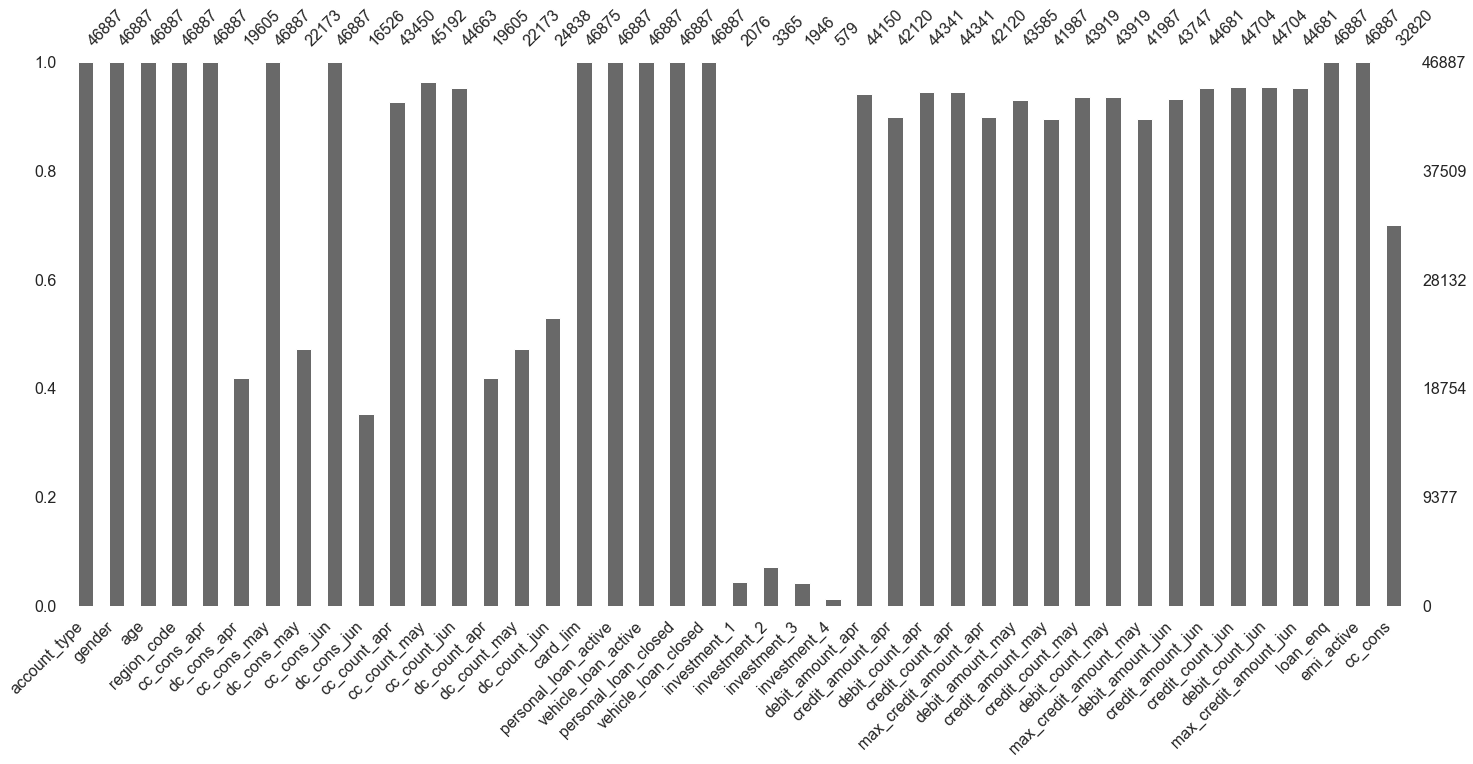

In [210]:
msno.bar(cc_spent)
plt.show()

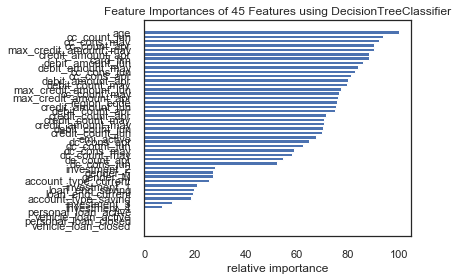

In [211]:
from sklearn.tree import DecisionTreeClassifier
from yellowbrick.features import FeatureImportances

clf = DecisionTreeClassifier()
viz = FeatureImportances(clf)
viz.fit(X[:5000],Y[:5000])
viz.poof()




### fig size adjust such that I can read Y lables

On imputation , we see the same graph of feature_importance.

From the above observation, we see that features 'vehicle_loan_closed','personal_loan_closed','vehicle_loan_active' , 'personal_loan_active','investment_4' and 'investment_3' are less important. On the other hand, we won't be getting more information from loan_enquiry even after deleting it. It is better to drop this feature as well. At this stage, we also observe that columns 'investment_1','investment2' are have missing values in them. They seem to be important features. Hence, we need to retain them.

In [212]:
cc_spent= cc_spent.drop(['investment_4','investment_3'], axis=1)

### More EDA is needed. I want to know which section of people investment is given 

Let us see the null values still remaining in the dataframe 

In [213]:
cc_spent.isnull().sum()

account_type                 0
gender                       0
age                          0
region_code                  0
cc_cons_apr                  0
dc_cons_apr              27282
cc_cons_may                  0
dc_cons_may              24714
cc_cons_jun                  0
dc_cons_jun              30361
cc_count_apr              3437
cc_count_may              1695
cc_count_jun              2224
dc_count_apr             27282
dc_count_may             24714
dc_count_jun             22049
card_lim                    12
personal_loan_active         0
vehicle_loan_active          0
personal_loan_closed         0
vehicle_loan_closed          0
investment_1             44811
investment_2             43522
debit_amount_apr          2737
credit_amount_apr         4767
debit_count_apr           2546
credit_count_apr          2546
max_credit_amount_apr     4767
debit_amount_may          3302
credit_amount_may         4900
credit_count_may          2968
debit_count_may           2968
max_cred

We can make use of imputation methods instead of data-dropping methods.The simplest imputation method is replacing missing values with "mean" or "median" values of the dataset , or some summary statistic. This has advantage of being simple approach, as it creates uniform bias across all columns in data. But, in case of missing values that are not strictly random , especially in the presence of great inequality in the number of missing values for the different variables , the mean substitution method may lead to inconsistent bias. Further, this doesn't add any new information and only increases sample size and leads to underestimate of errors. Hence, mean subsitution in case of missing values not random is generally not accepted.

##### <font color='green'> Imputing missing values using Linear Regression technique</font>

We will be imputing missing values to feature "card_lim" using the regression imputation technique.
In this technique, using the correlation matrix we will be figuring out the features which are highly
correlated to the missing variable. Thereby, consider the correlated features as 'X'(inputs) and 'Y'(target)
as the missing variable 'card_lim' while building the model. Once, the model is built the predicted values a
are for the missing variable and later assign it to the original dataframe.

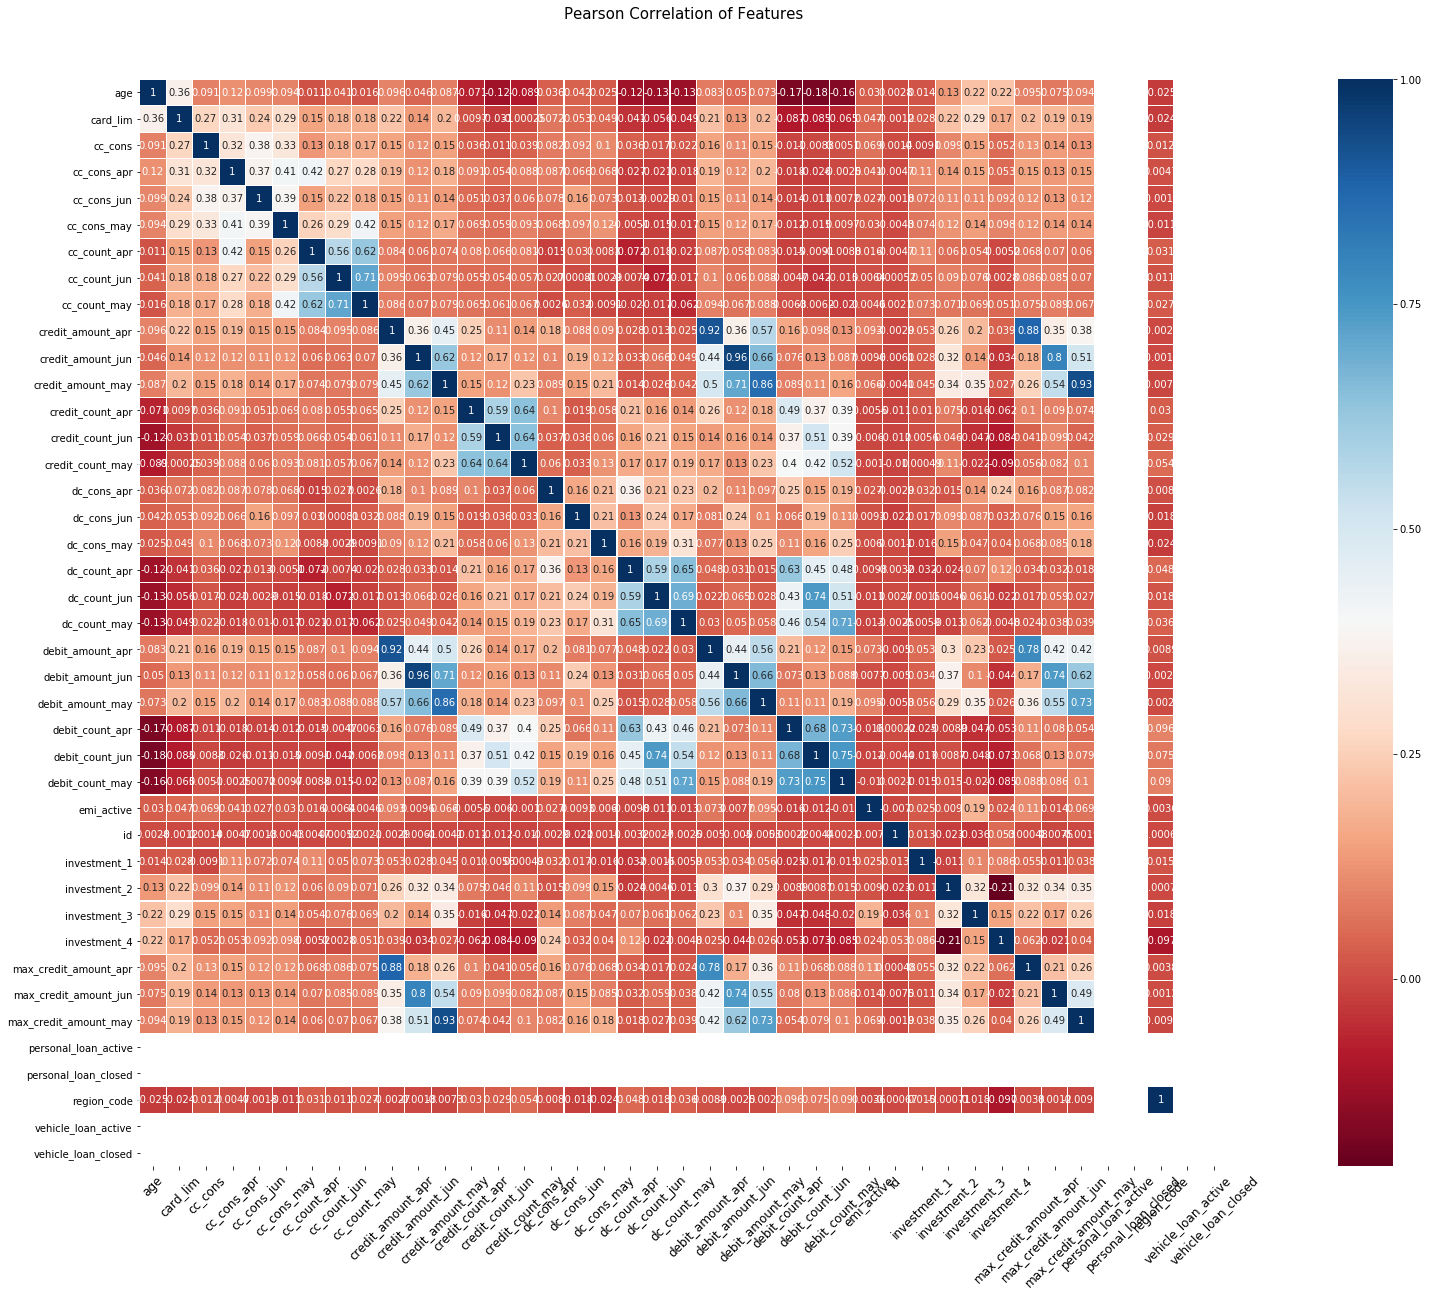

In [31]:
# Finding the correlation matrix
colormap = plt.cm.RdBu
plt.figure(figsize=(40,20))
plt.title('Pearson Correlation of Features',y=1.05, size=15)
sns.heatmap(cc_spent.corr(), linewidths=0.1, vmax=1.0,
            square=True, cmap=colormap, linecolor='white',
           annot=True)
plt.xticks(rotation=45,fontsize=12)
plt.show()

We figured that for column "card_lim" the features"age" and "cc_cons_apr", "cc_cons_may"
and "cc_cons_jun","cc_cons" are correlated. Hence, these variables
will be considered while model imputation and the target variable is "card_lim".

In [215]:
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
data_cl = cc_spent[['age','cc_cons_apr','cc_cons_may','cc_cons_jun','card_lim']]


# Splitting the dataset that contains missing values and no-missing values into train and test respectively
x_cl_train = data_cl[data_cl['card_lim'].notnull()].drop(columns='card_lim')
y_cl_train = data_cl[data_cl['card_lim'].notnull()]['card_lim']
x_cl_test = data_cl[data_cl['card_lim'].isnull()].drop(columns='card_lim')
y_cl_test = data_cl[data_cl['card_lim'].isnull()]['card_lim']

# Train the ml algo
linreg.fit(x_cl_train[:32820], y_cl_train[:32820])

# Predict the missing values in the attribute of the test data
predicted_cl = linreg.predict(x_cl_test)

# Let us obtain the complete dataset by combining it with the target variable
cc_spent.card_lim[cc_spent.card_lim.isnull()] = predicted_cl
cc_spent.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 46887 entries, 0 to 14066
Data columns (total 41 columns):
account_type             46887 non-null object
gender                   46887 non-null object
age                      46887 non-null int64
region_code              46887 non-null int64
cc_cons_apr              46887 non-null float64
dc_cons_apr              19605 non-null float64
cc_cons_may              46887 non-null float64
dc_cons_may              22173 non-null float64
cc_cons_jun              46887 non-null float64
dc_cons_jun              16526 non-null float64
cc_count_apr             43450 non-null float64
cc_count_may             45192 non-null float64
cc_count_jun             44663 non-null float64
dc_count_apr             19605 non-null float64
dc_count_may             22173 non-null float64
dc_count_jun             24838 non-null float64
card_lim                 46887 non-null float64
personal_loan_active     46887 non-null float64
vehicle_loan_active      46887 no

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy


We now see that the null values for column 'card_lim' is imputed.

We see that inorder to impute missing values in other variables, we need to see check coefficiency
of it and the features should have non-null values in them which is a bit complicated for rest features
through regression imputation. Hence, we will be using KNN imputation technique.

#### <font color='green'> Usage of KNN imputation technique inorder to impute missing values</font>

Extracting the null valued features into a seperate dataframe "cc_null_values"

In [216]:
null_cols = cc_spent.columns[cc_spent.isnull().any()]

In [217]:
# Since, null values in column "cc_cons" belong to test data. Hence, will be dropping the column
null_cols = null_cols.drop('cc_cons')

In [218]:
null_cols

Index(['dc_cons_apr', 'dc_cons_may', 'dc_cons_jun', 'cc_count_apr',
       'cc_count_may', 'cc_count_jun', 'dc_count_apr', 'dc_count_may',
       'dc_count_jun', 'investment_1', 'investment_2', 'debit_amount_apr',
       'credit_amount_apr', 'debit_count_apr', 'credit_count_apr',
       'max_credit_amount_apr', 'debit_amount_may', 'credit_amount_may',
       'credit_count_may', 'debit_count_may', 'max_credit_amount_may',
       'debit_amount_jun', 'credit_amount_jun', 'credit_count_jun',
       'debit_count_jun', 'max_credit_amount_jun'],
      dtype='object')

In [219]:
# Placing the null columns in another dataframe "null_data"
null_data = pd.DataFrame(cc_spent[null_cols])

In [220]:
null_data.head()

,dc_cons_apr,dc_cons_may,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun
0,NaN,NaN,NaN,2.0,1.0,3.0,NaN,NaN,NaN,NaN,118845.2,51205.47,50259.0,3.0,1.0,50000.0,24740.22,114252.0,3.0,2.0,45000.0,20215.85,1279.37,7.0,3.0,470.0
1,988.72,NaN,2806.24,11.0,14.0,11.0,1.0,NaN,6.0,NaN,NaN,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0
2,3215.52,1607.0,355.00,6.0,9.0,6.0,3.0,2.0,14.0,NaN,NaN,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0
3,NaN,NaN,NaN,9.0,6.0,6.0,NaN,NaN,NaN,NaN,132442.0,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0
4,NaN,NaN,NaN,2.0,7.0,9.0,NaN,NaN,NaN,NaN,NaN,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0


In [221]:
from fancyimpute import KNN
# fancyimpute removes column names, storing columns in the form of a list for train and test
cols = list(null_data)

Splitting dataframe into 3 dataframes based on indexes, since it is causing a memory issue

In [222]:
# Use 5 nearest rows which have a feature to fill in each row's  missing features
cc_train_1 = pd.DataFrame(KNN(k=5).fit_transform(null_data[1:15001]))
cc_train_1.columns = cols

Imputing row 1/15000 with 4 missing, elapsed time: 105.949
Imputing row 101/15000 with 2 missing, elapsed time: 106.057
Imputing row 201/15000 with 8 missing, elapsed time: 106.141
Imputing row 301/15000 with 8 missing, elapsed time: 106.229
Imputing row 401/15000 with 2 missing, elapsed time: 106.313
Imputing row 501/15000 with 8 missing, elapsed time: 106.405
Imputing row 601/15000 with 9 missing, elapsed time: 106.501
Imputing row 701/15000 with 2 missing, elapsed time: 106.585
Imputing row 801/15000 with 7 missing, elapsed time: 106.669
Imputing row 901/15000 with 8 missing, elapsed time: 106.753
Imputing row 1001/15000 with 10 missing, elapsed time: 106.853
Imputing row 1101/15000 with 4 missing, elapsed time: 106.965
Imputing row 1201/15000 with 8 missing, elapsed time: 107.049
Imputing row 1301/15000 with 8 missing, elapsed time: 107.141
Imputing row 1401/15000 with 7 missing, elapsed time: 107.221
Imputing row 1501/15000 with 14 missing, elapsed time: 107.317
Imputing row 1601/

Imputing row 13201/15000 with 7 missing, elapsed time: 117.695
Imputing row 13301/15000 with 8 missing, elapsed time: 117.815
Imputing row 13401/15000 with 6 missing, elapsed time: 117.911
Imputing row 13501/15000 with 2 missing, elapsed time: 117.987
Imputing row 13601/15000 with 5 missing, elapsed time: 118.071
Imputing row 13701/15000 with 8 missing, elapsed time: 118.151
Imputing row 13801/15000 with 8 missing, elapsed time: 118.239
Imputing row 13901/15000 with 14 missing, elapsed time: 118.319
Imputing row 14001/15000 with 10 missing, elapsed time: 118.403
Imputing row 14101/15000 with 7 missing, elapsed time: 118.503
Imputing row 14201/15000 with 5 missing, elapsed time: 118.595
Imputing row 14301/15000 with 6 missing, elapsed time: 118.679
Imputing row 14401/15000 with 8 missing, elapsed time: 118.759
Imputing row 14501/15000 with 13 missing, elapsed time: 118.855
Imputing row 14601/15000 with 6 missing, elapsed time: 118.935
Imputing row 14701/15000 with 7 missing, elapsed tim

In [223]:
cc_train_2 = pd.DataFrame(KNN(k=5).fit_transform(null_data[15000:32821]))
cc_train_2.columns = cols

Imputing row 1/17821 with 3 missing, elapsed time: 153.611
Imputing row 101/17821 with 2 missing, elapsed time: 162.051
Imputing row 201/17821 with 7 missing, elapsed time: 162.159
Imputing row 301/17821 with 2 missing, elapsed time: 162.271
Imputing row 401/17821 with 6 missing, elapsed time: 162.359
Imputing row 501/17821 with 24 missing, elapsed time: 162.463
Imputing row 601/17821 with 3 missing, elapsed time: 162.563
Imputing row 701/17821 with 3 missing, elapsed time: 162.675
Imputing row 801/17821 with 23 missing, elapsed time: 162.783
Imputing row 901/17821 with 5 missing, elapsed time: 162.891
Imputing row 1001/17821 with 2 missing, elapsed time: 163.355
Imputing row 1101/17821 with 23 missing, elapsed time: 163.455
Imputing row 1201/17821 with 8 missing, elapsed time: 163.579
Imputing row 1301/17821 with 2 missing, elapsed time: 163.675
Imputing row 1401/17821 with 5 missing, elapsed time: 163.779
Imputing row 1501/17821 with 7 missing, elapsed time: 163.895
Imputing row 1601

Imputing row 13201/17821 with 11 missing, elapsed time: 176.794
Imputing row 13301/17821 with 2 missing, elapsed time: 176.910
Imputing row 13401/17821 with 2 missing, elapsed time: 177.022
Imputing row 13501/17821 with 3 missing, elapsed time: 177.234
Imputing row 13601/17821 with 5 missing, elapsed time: 177.330
Imputing row 13701/17821 with 2 missing, elapsed time: 177.422
Imputing row 13801/17821 with 9 missing, elapsed time: 177.526
Imputing row 13901/17821 with 8 missing, elapsed time: 177.618
Imputing row 14001/17821 with 3 missing, elapsed time: 177.738
Imputing row 14101/17821 with 2 missing, elapsed time: 177.834
Imputing row 14201/17821 with 10 missing, elapsed time: 177.942
Imputing row 14301/17821 with 6 missing, elapsed time: 178.034
Imputing row 14401/17821 with 3 missing, elapsed time: 178.138
Imputing row 14501/17821 with 8 missing, elapsed time: 178.226
Imputing row 14601/17821 with 2 missing, elapsed time: 178.326
Imputing row 14701/17821 with 8 missing, elapsed time

In [224]:
cc_train_3 = pd.DataFrame(KNN(k=5).fit_transform(null_data[32820:46888]))
cc_train_3.columns = cols

Imputing row 1/14067 with 6 missing, elapsed time: 91.355
Imputing row 101/14067 with 2 missing, elapsed time: 91.447
Imputing row 201/14067 with 2 missing, elapsed time: 91.539
Imputing row 301/14067 with 9 missing, elapsed time: 91.651
Imputing row 401/14067 with 2 missing, elapsed time: 91.751
Imputing row 501/14067 with 8 missing, elapsed time: 91.847
Imputing row 601/14067 with 10 missing, elapsed time: 91.951
Imputing row 701/14067 with 3 missing, elapsed time: 92.063
Imputing row 801/14067 with 3 missing, elapsed time: 92.179
Imputing row 901/14067 with 3 missing, elapsed time: 92.287
Imputing row 1001/14067 with 4 missing, elapsed time: 92.371
Imputing row 1101/14067 with 23 missing, elapsed time: 92.455
Imputing row 1201/14067 with 3 missing, elapsed time: 92.563
Imputing row 1301/14067 with 8 missing, elapsed time: 92.639
Imputing row 1401/14067 with 5 missing, elapsed time: 92.723
Imputing row 1501/14067 with 8 missing, elapsed time: 92.819
Imputing row 1601/14067 with 4 mis

Imputing row 13501/14067 with 9 missing, elapsed time: 103.602
Imputing row 13601/14067 with 19 missing, elapsed time: 103.694
Imputing row 13701/14067 with 8 missing, elapsed time: 103.778
Imputing row 13801/14067 with 9 missing, elapsed time: 103.870
Imputing row 13901/14067 with 3 missing, elapsed time: 103.946
Imputing row 14001/14067 with 4 missing, elapsed time: 104.026


In [225]:
# Combining dataframes "cc_train_1" and "cc_train_2" into a single dataframe "cc_num_data" after
# imputation
cc_num_data = pd.concat([cc_train_1, cc_train_2, cc_train_3], ignore_index=True)

In [226]:
cc_num_data.shape

(46888, 26)

In [227]:
cc_num_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46888 entries, 0 to 46887
Data columns (total 26 columns):
dc_cons_apr              46888 non-null float64
dc_cons_may              46888 non-null float64
dc_cons_jun              46888 non-null float64
cc_count_apr             46888 non-null float64
cc_count_may             46888 non-null float64
cc_count_jun             46888 non-null float64
dc_count_apr             46888 non-null float64
dc_count_may             46888 non-null float64
dc_count_jun             46888 non-null float64
investment_1             46888 non-null float64
investment_2             46888 non-null float64
debit_amount_apr         46888 non-null float64
credit_amount_apr        46888 non-null float64
debit_count_apr          46888 non-null float64
credit_count_apr         46888 non-null float64
max_credit_amount_apr    46888 non-null float64
debit_amount_may         46888 non-null float64
credit_amount_may        46888 non-null float64
credit_count_may         46

For the test dataset, the indices are not quite large. Hence, we won't be slicing it.

Adding the values of imputed columns back to the original dataframe "cc_spent"

In [228]:
cc_spent[null_cols] = cc_num_data

Let's check the information of dataframe

In [229]:
cc_spent.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 46887 entries, 0 to 14066
Data columns (total 41 columns):
account_type             46887 non-null object
gender                   46887 non-null object
age                      46887 non-null int64
region_code              46887 non-null int64
cc_cons_apr              46887 non-null float64
dc_cons_apr              46887 non-null float64
cc_cons_may              46887 non-null float64
dc_cons_may              46887 non-null float64
cc_cons_jun              46887 non-null float64
dc_cons_jun              46887 non-null float64
cc_count_apr             46887 non-null float64
cc_count_may             46887 non-null float64
cc_count_jun             46887 non-null float64
dc_count_apr             46887 non-null float64
dc_count_may             46887 non-null float64
dc_count_jun             46887 non-null float64
card_lim                 46887 non-null float64
personal_loan_active     46887 non-null float64
vehicle_loan_active      46887 no

In [230]:
'''Converting the features "personal_loan_active","vehicle_loan_active","personal_loan_closed" and 
"vehicle_loan_closed" to "object" type.'''

features = ['personal_loan_active','vehicle_loan_active','personal_loan_closed','vehicle_loan_closed']

for cols in cc_spent[features]:
    cc_spent[cols] = cc_spent[cols].astype("object")

#### <font color='green'> Detecting and Removing Outliers</font>

In [231]:
num_cols = []
for column in cc_spent.select_dtypes(["int64","float64"]):
    num_cols.append(column)

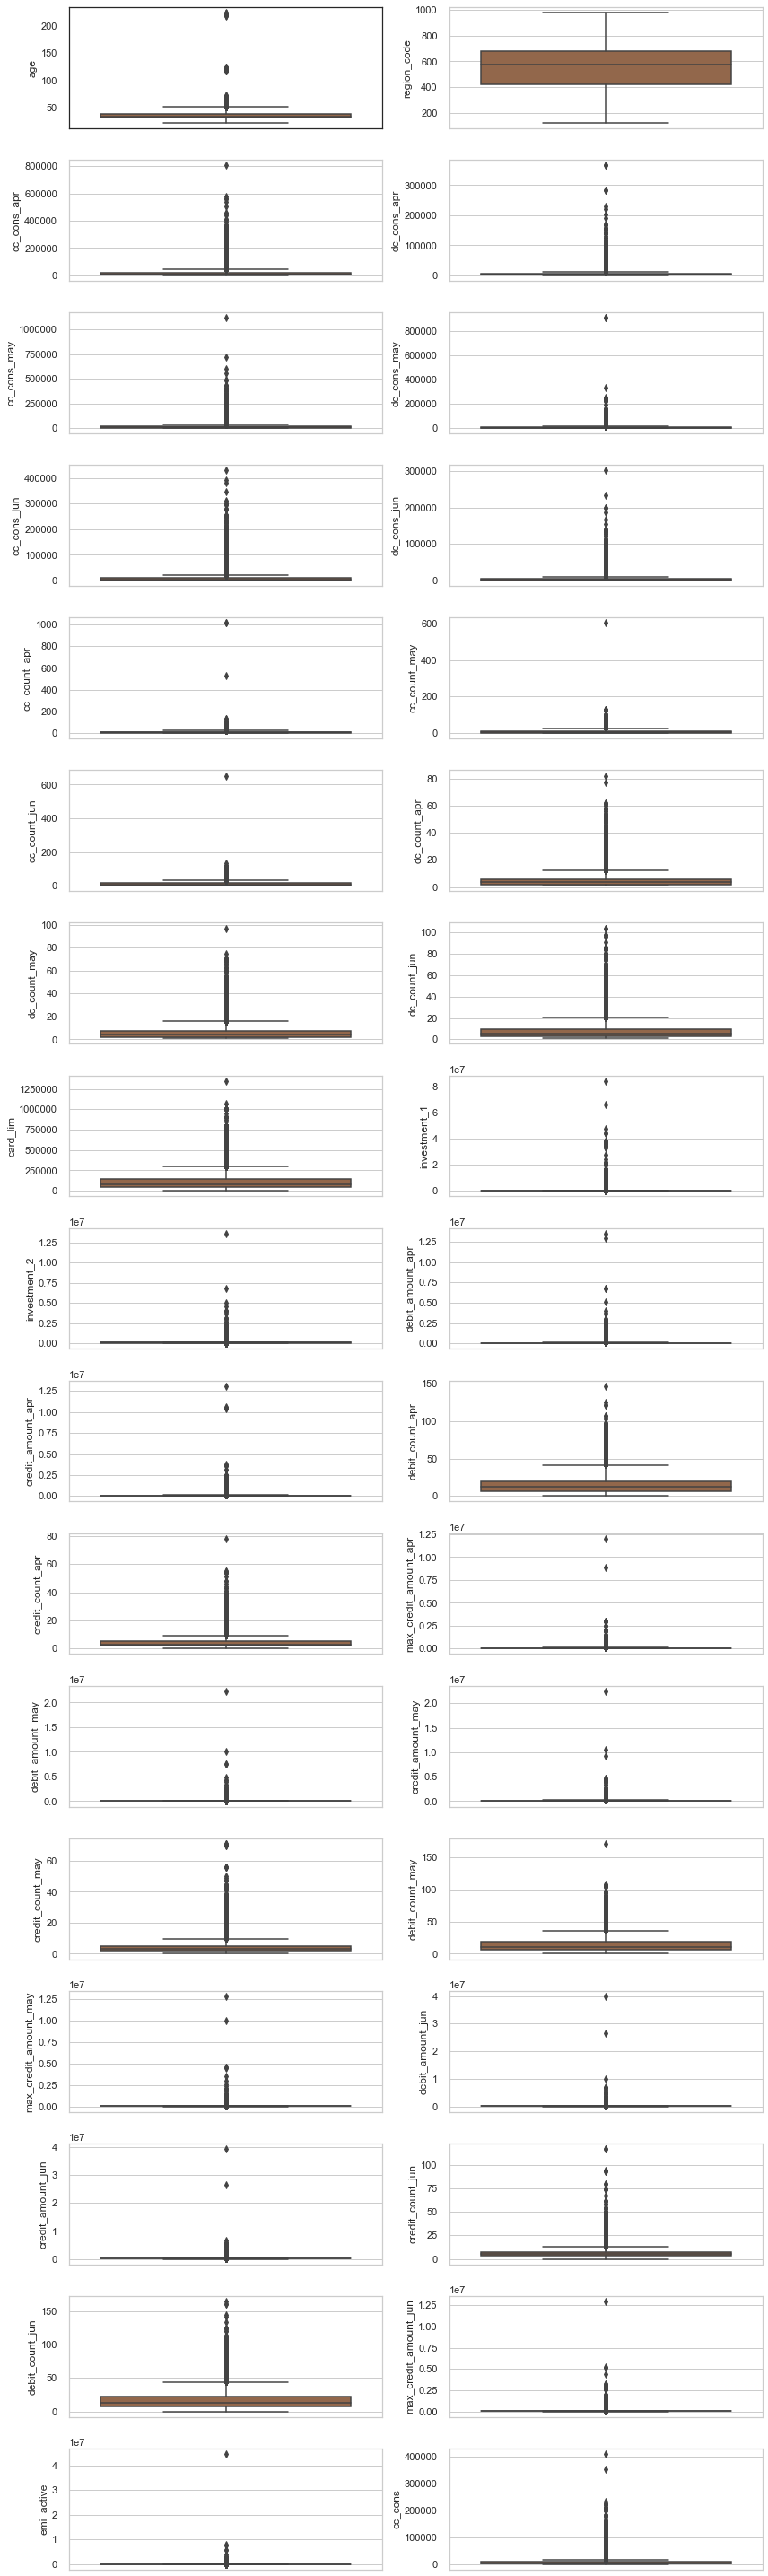

In [232]:
fig = plt.figure(figsize=(12,40))
i=1
for column in cc_spent.select_dtypes(["int64","float64"]):
    plt.subplot(17,2,i)
    sns.set_style("whitegrid")
    ax = sns.boxplot(cc_spent[column], palette="copper", orient='v')
    i = i + 1
    
plt.tight_layout()
plt.show()

    

The above graph shows the Oultier Analysis of various continuous variables, we see most of the data points
lying above the inter-quartile range. However, they cannot be termed as outliers. In this scenario, we will be gathering data points
which don't follow in the normal pattern and consider a pattern among them , detect and remove outliers.

We see few consumers spending credit amount above 800000 in month of April. Hence, finding people ranging above 800000.

In [233]:
cc_spent[cc_spent['cc_cons_apr'] >= 800000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
23080,saving,M,39,523,804712.58,15288.634731,384099.42,17823.99,99433.22,2868.83,60.0,52.0,58.0,8.568769,11.0,13.0,280000.0,0,0,0,0,62457.015284,108670.006909,537009.0,500015.0,9.0,1.0,500000.0,491283.61,500039.0,1.0,21.0,500000.0,589069.84,502173.0,3.0,15.0,500000.0,N,0.0,198197.0


Few consumers are spending debits above 250000. Hence, finding spending amount > 250000.

In [234]:
cc_spent[cc_spent['dc_cons_apr'] >= 250000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
526,current,M,28,534,3262.145,283697.75,5063.29,103663.9,239.000,2419.300869,1.0,8.0,8.0,7.0,2.0,5.0,35000.0,0,1,0,0,1385.163994,274695.982435,578617.65,462080.65,24.0,12.0,217917.86,80729.97,148195.00,10.0,7.0,60025.0,174704.04,130232.90,12.0,15.0,60025.0,N,2223.10,1199.0
1673,saving,F,44,523,2445.660,366223.16,2027.24,10940.0,2645.950,2976.331743,17.0,16.0,4.0,30.0,5.0,3.0,126000.0,0,0,0,0,6425.330278,119964.513184,545955.65,588490.61,80.0,7.0,200000.00,80552.72,60681.96,6.0,17.0,20000.0,14414.00,1022.75,5.0,5.0,515.0,N,45325.74,200.0
526,current,M,30,324,3200.900,283697.75,8340.13,103663.9,6039.015,2419.300869,1.0,8.0,8.0,7.0,2.0,5.0,45000.0,0,0,0,0,1385.163994,274695.982435,578617.65,462080.65,24.0,12.0,217917.86,80729.97,148195.00,10.0,7.0,60025.0,174704.04,130232.90,12.0,15.0,60025.0,N,4062.39,NaN
1673,current,F,33,324,4965.390,366223.16,3519.42,10940.0,4461.905,2976.331743,17.0,16.0,4.0,30.0,5.0,3.0,32000.0,0,0,0,0,6425.330278,119964.513184,545955.65,588490.61,80.0,7.0,200000.00,80552.72,60681.96,6.0,17.0,20000.0,14414.00,1022.75,5.0,5.0,515.0,N,2918.20,NaN


Credit spend by consumers are ranging above 1000000. Hence, getting the exact count.

In [235]:
cc_spent[cc_spent['cc_cons_may'] >= 1000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
17530,current,F,44,523,122265.9,774.0,1117246.31,33923.504497,128140.57,2704.88,33.0,39.0,54.0,1.0,3.088505,5.0,800000.0,0,0,0,0,57473.198191,108670.279794,448415.95,382613.0,21.0,3.0,337428.0,844686.5,842702.0,5.0,26.0,500000.0,976208.64,1021136.45,6.0,31.0,500000.0,N,11185.96,65782.0


Debit amount being spent by customers in May month is also ranging above 800000.

In [236]:
cc_spent[cc_spent['dc_cons_may'] >= 800000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
7813,saving,M,38,891,22543.56,11555.0,15759.96,911223.49,3216.000,15985.54103,42.0,17.0,21.0,1.0,11.0,1.0,46000.0,0,0,1,0,56077.122398,371443.828812,162185.62,458631.62,16.0,10.0,141500.0,1685070.26,387285.26,18.0,22.0,112450.0,306276.0,309233.0,12.0,8.0,112450.0,N,0.00,1527.0
7813,current,M,31,723,12370.50,11555.0,7851.41,911223.49,10132.455,15985.54103,42.0,17.0,21.0,1.0,11.0,1.0,41000.0,1,0,0,0,56077.122398,371443.828812,162185.62,458631.62,16.0,10.0,141500.0,1685070.26,387285.26,18.0,22.0,112450.0,306276.0,309233.0,12.0,8.0,112450.0,N,1346.49,NaN


Credit amount in June month is being spent above 350000 by few users. Let us have a look of it. 

In [237]:
cc_spent[cc_spent['cc_cons_jun'] >= 350000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
6337,current,M,39,263,335251.49,2474.962554,402086.00,14871.480000,382914.10,12592.000000,9.0,4.0,3.6,6.3635,10.000000,5.000000,243000.0,0,0,0,0,54667.92434,39457.572024,64441.57,50495.00,17.0,4.0,40000.0,46680.32,78536.84,4.0,18.0,40000.0,60786.800000,40256.0,2.0,16.0,40000.0,N,4014.99,408630.0
13079,current,M,36,683,58729.49,3387.500000,426569.30,1318.000000,429522.43,4354.492224,19.0,10.0,16.0,1.0000,3.000000,6.068011,800000.0,0,0,0,0,5613.94979,93476.298519,65183.43,61316.02,14.0,5.0,36600.0,18741.59,38922.74,3.0,12.0,36600.0,51803.980000,36783.0,2.0,8.0,36600.0,N,5305.34,NaN
13806,current,M,53,233,213048.03,3803.000000,31822.46,2370.187212,392680.60,2095.279136,17.0,23.0,19.0,5.0000,7.564278,5.769872,500000.0,0,0,0,1,4703.98439,106850.249297,20377.40,21262.00,11.0,2.0,15000.0,32019.76,16179.00,1.0,2.0,16000.0,11.715988,125712.0,4.0,0.0,100000.0,N,13295.43,NaN


Debit amount spent in June month is also above 300000 by consumers. Let's see how many of them belong to
this category.

In [238]:
cc_spent[cc_spent['dc_cons_jun'] >= 300000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
26857,current,F,27,683,10123.5,1204.32331,33783.5,2488.252939,889.0,301991.94,5.0,14.0,7.0,1.931124,3.858226,17.0,155000.0,0,0,0,0,7998.808668,108670.036943,43131.26,26040.0,17.0,4.0,20000.0,44256.0,300195.0,2.0,10.0,280000.0,324231.44,185175.76,5.0,19.0,155000.0,N,0.0,2582.0


Credit transactions carried out in April, May and June are 400 and 600. Let us find the pattern of users
performing such huge transactions.

In [239]:
cc_spent[cc_spent['cc_count_apr'] >= 400]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
3412,current,M,32,523,3031.00,6563.782524,1254.00,20.000000,3502.00,7376.916683,1012.0,17.0,28.0,5.387539,1.000000,10.660372,101000.0,1,0,1,0,225067.871613,198463.393895,603266.230000,876516.300000,23.000000,16.0,330000.000000,641816.640000,402243.160000,17.000000,13.000000,242209.3000,184154.21,141537.0,19.0,19.0,20000.0,N,6292.51,40720.0
22323,current,M,34,245,18208.18,1002.487643,37353.05,7257.154246,57170.00,1483.566802,531.0,601.0,653.0,1.767611,3.511149,8.381056,225000.0,1,0,1,1,73952.091016,80874.351579,128.598083,756.120891,1.396968,0.0,593.548516,975.624647,7679.641688,0.396045,1.615259,6529.8061,28154.00,51684.0,4.0,3.0,30000.0,N,31642.29,52951.0
3412,current,M,28,764,16556.50,6563.782524,1148.00,20.000000,9302.75,7376.916683,1012.0,17.0,28.0,5.387539,1.000000,10.660372,25000.0,0,0,0,0,225067.871613,198463.393895,603266.230000,876516.300000,23.000000,16.0,330000.000000,641816.640000,402243.160000,17.000000,13.000000,242209.3000,184154.21,141537.0,19.0,19.0,20000.0,N,2678.97,NaN


In [240]:
cc_spent[cc_spent['cc_count_may'] >= 600]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
22323,current,M,34,245,18208.18,1002.487643,37353.05,7257.154246,57170.0,1483.566802,531.0,601.0,653.0,1.767611,3.511149,8.381056,225000.0,1,0,1,1,73952.091016,80874.351579,128.598083,756.120891,1.396968,0.0,593.548516,975.624647,7679.641688,0.396045,1.615259,6529.8061,28154.0,51684.0,4.0,3.0,30000.0,N,31642.29,52951.0


In [241]:
cc_spent[cc_spent['cc_count_jun'] >= 600]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
22323,current,M,34,245,18208.18,1002.487643,37353.05,7257.154246,57170.0,1483.566802,531.0,601.0,653.0,1.767611,3.511149,8.381056,225000.0,1,0,1,1,73952.091016,80874.351579,128.598083,756.120891,1.396968,0.0,593.548516,975.624647,7679.641688,0.396045,1.615259,6529.8061,28154.0,51684.0,4.0,3.0,30000.0,N,31642.29,52951.0


Debit transactions carried out by users in months of April, May and June are also 70-90.

In [242]:
cc_spent[cc_spent['dc_count_apr'] >= 70]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
16361,current,M,29,946,13845.90,26503.30,9618.510,14799.97,6729.00,3766.00,12.0,18.0,39.0,82.0,75.0,57.0,25000.0,0,0,0,0,13198.318749,108669.125820,42086.05,31250.75,95.0,7.0,22668.0,53238.25,57283.00,5.0,84.0,29000.0,29606.33,33128.00,5.0,70.0,25906.0,N,0.00,6539.0
24411,saving,M,33,344,3123.49,15731.91,18261.215,22363.47,32728.94,12115.42,3.0,2.6,5.0,77.0,65.0,91.0,75000.0,0,0,0,0,7443.498193,108669.942754,87292.41,80317.00,103.0,7.0,42250.0,79953.97,90349.25,8.0,84.0,42250.0,132594.54,127078.43,15.0,106.0,40750.0,N,2789.26,9354.0


In [243]:
cc_spent[cc_spent['dc_count_may'] >= 80]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
26668,current,M,27,683,1272.25,32621.65,325.5,28727.38,580.0,21125.68,4.6,1.0,4.0,52.0,97.0,96.0,75000.0,0,0,0,0,3990.177161,108671.796645,106114.5,127752.97,76.0,11.0,80292.0,84794.17,74465.5,7.0,108.0,63545.0,97444.86,80360.0,5.0,112.0,63545.0,N,0.0,2.0


In [244]:
cc_spent[cc_spent['dc_count_jun'] >= 90]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
4334,current,F,32,764,9264.00,11952.830000,843.000,13732.06,10984.00,7584.02,2.0,9.0,15.0,62.000000,53.0,98.0,78000.0,0,0,0,0,1349.127942,68331.002937,37427.860000,39401.75,81.0,7.0,27654.0,32052.16,27972.00,3.0,61.0,27654.0,29437.44,31190.85,6.0,107.0,27653.0,N,215.22,26954.0
12715,saving,F,34,513,7651.81,213.032751,1915.450,11067.09,869.00,8849.34,9.0,17.0,6.0,1.000048,38.0,104.0,100000.0,0,0,0,0,3945.406633,27334.988674,117.971571,35103.00,0.0,1.0,35007.0,35094.59,54235.50,5.0,53.0,35007.0,57250.16,47676.01,20.0,109.0,34995.0,N,0.00,5820.0
24411,saving,M,33,344,3123.49,15731.910000,18261.215,22363.47,32728.94,12115.42,3.0,2.6,5.0,77.000000,65.0,91.0,75000.0,0,0,0,0,7443.498193,108669.942754,87292.410000,80317.00,103.0,7.0,42250.0,79953.97,90349.25,8.0,84.0,42250.0,132594.54,127078.43,15.0,106.0,40750.0,N,2789.26,9354.0
26668,current,M,27,683,1272.25,32621.650000,325.500,28727.38,580.00,21125.68,4.6,1.0,4.0,52.000000,97.0,96.0,75000.0,0,0,0,0,3990.177161,108671.796645,106114.500000,127752.97,76.0,11.0,80292.0,84794.17,74465.50,7.0,108.0,63545.0,97444.86,80360.00,5.0,112.0,63545.0,N,0.00,2.0
4334,saving,M,33,465,979.66,11952.830000,1112.330,13732.06,811.00,7584.02,2.0,9.0,15.0,62.000000,53.0,98.0,50000.0,0,0,0,0,1349.127942,68331.002937,37427.860000,39401.75,81.0,7.0,27654.0,32052.16,27972.00,3.0,61.0,27654.0,29437.44,31190.85,6.0,107.0,27653.0,N,116.12,NaN
12715,current,M,28,683,8447.00,213.032751,4540.000,11067.09,3298.00,8849.34,9.0,17.0,6.0,1.000048,38.0,104.0,40000.0,0,0,0,0,3945.406633,27334.988674,117.971571,35103.00,0.0,1.0,35007.0,35094.59,54235.50,5.0,53.0,35007.0,57250.16,47676.01,20.0,109.0,34995.0,N,0.00,NaN


Credit card limit above 1000000 for few.

In [245]:
cc_spent[cc_spent['card_lim'] >= 1000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
5104,current,M,45,683,8323.52,1227.000000,600699.73,1421.000000,52601.04,874.051222,6.250008,4.0,16.0,3.000000,3.000000,2.586094,1000000.0,0,0,0,0,807.997827,71307.208280,1.389188e+05,6.827100e+04,25.000000,2.000000,3.411700e+04,1.414475e+04,5.247000e+03,1.000000,8.000000,5.000000e+03,4.094342e+04,4.053100e+04,3.0,7.0,35502.00,N,0.00,13261.0
5489,saving,M,45,723,124366.50,215.592607,96689.70,1986.663956,1160.00,3682.129541,11.333328,7.0,7.0,1.000000,3.835167,2.588296,1000000.0,0,0,0,0,7633.762883,425091.550034,2.469095e+03,6.608103e+03,1.466667,0.533333,5.126598e+03,1.150380e+05,2.152760e+05,5.000000,2.000000,1.000000e+05,1.398685e+05,4.217470e+05,5.0,20.0,400000.00,N,172301.14,25330.0
8564,current,M,46,233,101160.74,1619.000000,77473.78,5870.000000,121728.99,2632.000000,2.000000,5.0,3.6,3.000000,7.000000,13.000000,1000000.0,0,0,0,0,20683.317334,36743.085969,4.514601e+04,4.534101e+04,15.000000,4.000000,2.396201e+04,6.149394e+04,6.224756e+04,6.000000,19.000000,2.500000e+04,4.751176e+04,4.889278e+04,12.0,24.0,18897.78,N,1140462.95,68600.0
9154,current,F,43,683,4079.32,8905.355752,7642.64,3261.819205,475.00,1298.135088,2.000000,2.0,10.0,1.838247,1.344149,1.407980,1000000.0,0,0,0,0,1395.103049,76484.374877,1.489184e+04,2.569800e+04,4.000000,2.000000,2.356000e+04,1.672407e+04,2.496900e+04,2.000000,1.000000,2.356000e+04,1.680430e+03,1.986000e+03,2.0,1.0,1205.00,N,0.00,1349.0
14185,saving,M,44,823,267407.02,2122.000000,1077.00,7860.000000,109773.22,3722.000000,4.000000,4.0,4.2,1.000000,13.000000,14.000000,1000000.0,0,0,0,0,29728.747855,314480.739114,4.221470e+03,2.777770e+03,7.000000,2.000000,2.500000e+03,1.166200e+04,1.670436e+04,3.000000,18.000000,1.450000e+04,9.169290e+03,7.333760e+03,4.0,25.0,7000.00,N,0.00,32163.0
14241,saving,M,33,806,262979.34,3065.571325,53041.67,1150.647420,68414.25,643.260220,15.000000,24.0,23.0,1.051581,1.915173,3.507311,1000000.0,0,0,0,0,4324.634442,179165.713840,3.716250e+03,4.218000e+03,2.000000,1.000000,4.000000e+03,4.566500e+03,5.180000e+03,1.000000,2.000000,5.000000e+03,7.680000e+03,3.031200e+04,2.0,3.0,30000.00,Y,27448.91,91029.0
15120,current,M,59,245,126943.95,48138.000000,329842.58,27949.454107,85181.66,19940.977160,36.000000,56.0,29.0,4.000000,10.945496,21.503938,1000000.0,0,0,0,1,26250.947875,153570.160000,1.563448e+06,1.929494e+06,39.000000,9.000000,9.195920e+05,1.009562e+06,9.713800e+05,3.000000,27.000000,9.195930e+05,3.422567e+06,4.228019e+06,6.0,31.0,3000000.00,N,200858.63,38217.0
17928,current,M,40,683,59287.65,25577.090000,24849.90,50661.050000,5046.50,11702.400000,16.000000,13.0,20.0,12.000000,25.000000,30.000000,1000000.0,0,0,0,0,2.130000,137510.680454,2.335624e+05,2.218770e+05,34.000000,3.000000,1.843910e+05,2.845315e+05,1.895633e+05,3.000000,47.000000,1.843930e+05,3.273895e+05,1.957892e+05,4.0,52.0,184392.00,N,36204.77,19940.0
19442,saving,M,60,523,72686.75,264.270629,59859.88,9234.177019,197694.38,3524.050644,20.000000,18.0,24.0,1.461824,1.211810,1.601934,1000000.0,1,0,0,1,308591.000000,45995.553198,1.350000e+02,3.390141e+02,1.000000,0.000000,1.489588e+02,4.189135e+03,1.022943e+04,0.380232,1.079351,5.908791e+03,2.507139e+03,4.800000e+02,1.0,0.0,384.00,N,319598.66,104722.0
26323,saving,M,58,245,139159.42,3208.994399,179209.30,1557.028577,164816.65,19658.821011,18.000000,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,0,0,0,0,8822.253779,108670.000004,1.353571e+07,1.043463e+07,19.000000,24.00000

Some have invested huge in fixed deposits

In [246]:
cc_spent[cc_spent['investment_2'] >= 6000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
14315,current,M,54,519,1665.00,4083.213919,2879.00,67085.0,2881.0,1314.088232,3.0,6.0,3.0,1.348071,1.0,1.924362,43000.0,0,0,0,0,1653.182154,13602841.60,7168.5,328.0,1.0,2.0,33.0,69939.52,706338.0,2.0,2.0,704520.0,11180.52,4085.0,2.0,1.0,3858.0,N,0.00,10000.0
17432,saving,M,41,683,51561.65,12354.811242,105402.18,2193.0,28457.0,4049.237918,42.0,43.0,73.0,7.534297,2.0,1.000000,200000.0,0,0,0,0,19843.190604,6803111.71,3954222.0,3819581.0,12.0,9.0,2500000.0,234543.50,261789.0,12.0,12.0,98592.0,152301.87,70229.0,4.0,15.0,40000.0,N,2988.67,27048.0


Total debit amount spent in April is exceeding 12000000.

In [247]:
cc_spent[cc_spent['debit_amount_apr'] >= 12000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
26323,saving,M,58,245,139159.42,3208.994399,179209.3,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,0,0,0,0,8822.253779,108670.000004,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0
30409,current,M,62,523,20912.00,4836.573237,10058.0,2286.450000,99037.00,17682.112813,2.0,2.0,10.0,6.597474,1.000000,6.000000,300000.0,0,0,0,0,4935.944142,108670.000956,12897875.00,13100583.00,11.0,5.0,12029154.0,115095.20,1054267.00,3.0,12.0,910559.00,71359.11,1173923.66,9.0,18.0,964372.00,N,87567.67,73281.0


Total credit amount spent in April is also exceeding 10000000

In [248]:
cc_spent[cc_spent['credit_amount_apr'] >= 10000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
373,current,M,27,503,3574.00,4363.997768,2415.9,9831.241554,3256.45,11065.539211,5.0,10.0,12.0,1.411516,3.976272,9.549494,50000.0,0,0,0,0,3550.070752,1.400000e+06,6751644.75,10546937.00,10.0,13.0,2000000.0,7537522.00,3934262.00,15.0,27.0,1000000.00,553496.67,151662.00,4.0,12.0,80546.00,N,0.00,2012.0
22926,current,M,48,683,176584.68,1836.811347,128717.0,5794.510366,78539.06,4412.662812,14.0,32.0,50.0,1.389724,3.403047,4.942296,800000.0,0,0,0,1,52796.879804,1.086700e+05,5156863.79,10592125.00,23.0,7.0,8900000.0,10027004.73,4333895.16,7.0,19.0,3480000.00,1756749.09,1768645.21,10.0,27.0,510000.00,N,2320919.01,68379.0
26323,saving,M,58,245,139159.42,3208.994399,179209.3,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,0,0,0,0,8822.253779,1.086700e+05,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0
30409,current,M,62,523,20912.00,4836.573237,10058.0,2286.450000,99037.00,17682.112813,2.0,2.0,10.0,6.597474,1.000000,6.000000,300000.0,0,0,0,0,4935.944142,1.086700e+05,12897875.00,13100583.00,11.0,5.0,12029154.0,115095.20,1054267.00,3.0,12.0,910559.00,71359.11,1173923.66,9.0,18.0,964372.00,N,87567.67,73281.0
373,saving,F,35,723,62630.00,4363.997768,34868.5,9831.241554,4525.00,11065.539211,5.0,10.0,12.0,1.411516,3.976272,9.549494,75000.0,0,0,0,0,3550.070752,1.400000e+06,6751644.75,10546937.00,10.0,13.0,2000000.0,7537522.00,3934262.00,15.0,27.0,1000000.00,553496.67,151662.00,4.0,12.0,80546.00,N,0.00,NaN


Credit transactions carried out are not in the normal range. They are more than 70.

In [249]:
cc_spent[cc_spent['credit_count_apr'] >= 70]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
20377,current,M,35,723,5862.0,62721.0,24231.5,59735.78,42303.0,33525.02,7.0,2.333333,27.0,42.0,45.0,35.0,65000.0,1,0,1,0,13105.767073,108670.010427,1661981.79,1555366.0,147.0,78.0,213400.0,1543930.75,1664724.12,71.0,171.0,290000.0,1165291.3,1010548.5,74.0,141.0,219389.0,N,32889.01,12251.0


Maximum credit amount available for few consumers is above 8000000

In [250]:
cc_spent[cc_spent['max_credit_amount_apr'] >= 8000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
22926,current,M,48,683,176584.68,1836.811347,128717.0,5794.510366,78539.06,4412.662812,14.0,32.0,50.0,1.389724,3.403047,4.942296,800000.0,0,0,0,1,52796.879804,108670.000077,5156863.79,10592125.0,23.0,7.0,8900000.0,10027004.73,4333895.16,7.0,19.0,3480000.0,1756749.09,1768645.21,10.0,27.0,510000.0,N,2320919.01,68379.0
30409,current,M,62,523,20912.00,4836.573237,10058.0,2286.450000,99037.00,17682.112813,2.0,2.0,10.0,6.597474,1.000000,6.000000,300000.0,0,0,0,0,4935.944142,108670.000956,12897875.00,13100583.0,11.0,5.0,12029154.0,115095.20,1054267.00,3.0,12.0,910559.0,71359.11,1173923.66,9.0,18.0,964372.0,N,87567.67,73281.0


Total debit amount in May month is above 6000000

In [251]:
cc_spent[cc_spent['debit_amount_may'] >= 6000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
373,current,M,27,503,3574.00,4363.997768,2415.9,9831.241554,3256.45,11065.539211,5.0,10.0,12.0,1.411516,3.976272,9.549494,50000.0,0,0,0,0,3550.070752,1.400000e+06,6751644.75,10546937.00,10.0,13.0,2000000.0,7537522.00,3934262.00,15.0,27.0,1000000.00,553496.67,151662.00,4.0,12.0,80546.00,N,0.00,2012.0
22926,current,M,48,683,176584.68,1836.811347,128717.0,5794.510366,78539.06,4412.662812,14.0,32.0,50.0,1.389724,3.403047,4.942296,800000.0,0,0,0,1,52796.879804,1.086700e+05,5156863.79,10592125.00,23.0,7.0,8900000.0,10027004.73,4333895.16,7.0,19.0,3480000.00,1756749.09,1768645.21,10.0,27.0,510000.00,N,2320919.01,68379.0
26323,saving,M,58,245,139159.42,3208.994399,179209.3,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,0,0,0,0,8822.253779,1.086700e+05,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0
373,saving,F,35,723,62630.00,4363.997768,34868.5,9831.241554,4525.00,11065.539211,5.0,10.0,12.0,1.411516,3.976272,9.549494,75000.0,0,0,0,0,3550.070752,1.400000e+06,6751644.75,10546937.00,10.0,13.0,2000000.0,7537522.00,3934262.00,15.0,27.0,1000000.00,553496.67,151662.00,4.0,12.0,80546.00,N,0.00,NaN


Credit amount being spent in May month is above 6000000

In [252]:
cc_spent[cc_spent['credit_amount_may'] >= 6000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
15471,current,M,37,523,7152.80,3404.442012,79792.5,570.143498,1863.00,15095.969520,5.0,12.0,10.0,1.507133,1.970731,6.123279,600000.0,1,0,1,1,10373.308822,4.550727e+06,886216.00,859688.00,21.0,14.0,350000.0,4859467.01,9315328.35,19.0,21.0,4500000.00,9845732.12,5469660.10,20.0,27.0,4400000.00,N,622.26,5469.0
26323,saving,M,58,245,139159.42,3208.994399,179209.3,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,0,0,0,0,8822.253779,1.086700e+05,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0
27116,saving,M,66,233,61944.72,6250.777912,8332.4,637.267383,35898.56,5642.048936,3.0,2.0,2.0,2.121918,1.847854,10.482568,200000.0,0,0,0,1,1885.162959,1.086700e+05,402792.75,198745.00,6.0,3.0,101640.0,64779.72,10601749.00,3.0,2.0,10000000.00,5009763.78,138130.00,2.0,2.0,101640.00,N,0.00,15249.0


Credit and Debit transactions are exceeding greater than 50 and 100

In [253]:
cc_spent[cc_spent['credit_count_may'] > 50 ]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
3356,current,F,26,883,2869.000,388.000000,3345.00,281.000000,3462.500,12542.904107,3.0,8.000000,5.6,1.000000,1.000000,1.000000,59000.0,0,0,0,0,947.917819,81754.785113,26634.63,24551.5,20.0,22.0,18430.0,25185.25,32070.00,70.0,22.0,18403.0,81839.24,74728.00,117.0,31.0,22000.0,N,0.00,775.0
6625,current,M,28,245,9200.000,6552.366243,18871.00,1187.000000,1215.000,4291.100000,25.0,12.000000,12.0,4.193261,6.000000,37.000000,52000.0,0,0,1,0,5852.284547,174993.734993,243332.31,241057.0,48.0,38.0,42581.0,596082.20,596225.00,71.0,104.0,200000.0,638214.42,638761.00,80.0,160.0,165000.0,N,85.23,1285.0
10048,saving,M,44,563,4612.190,8041.742518,8660.78,5174.070125,3416.000,13519.366264,2.0,1.000000,16.0,2.471530,3.991337,4.020829,20000.0,0,0,1,0,318640.580000,120000.000000,1192528.58,1199924.3,66.0,48.0,225000.0,473222.50,496219.40,56.0,90.0,111955.0,470594.57,430159.08,44.0,85.0,135000.0,N,26674.22,2040.0
12991,current,M,35,523,10653.880,4324.051514,8650.90,4152.081265,4916.420,4217.967522,43.0,32.000000,6.0,1.331324,3.928037,10.840362,390000.0,1,0,0,0,4719.992373,677899.719638,509936.84,492935.0,35.0,54.0,70000.0,841768.14,909892.50,56.0,54.0,160000.0,750534.92,803204.47,50.0,33.0,160000.0,N,6781.09,16466.0
20377,current,M,35,723,5862.000,62721.000000,24231.50,59735.780000,42303.000,33525.020000,7.0,2.333333,27.0,42.000000,45.000000,35.000000,65000.0,1,0,1,0,13105.767073,108670.010427,1661981.79,1555366.0,147.0,78.0,213400.0,1543930.75,1664724.12,71.0,171.0,290000.0,1165291.30,1010548.50,74.0,141.0,219389.0,N,32889.01,12251.0
22464,current,M,35,233,112278.840,4626.183714,157410.25,6064.284637,134847.545,14386.096610,24.0,31.000000,18.0,2.171603,6.487349,12.304743,213000.0,0,0,0,0,93830.162276,108670.052163,276200.65,262395.0,27.0,51.0,49000.0,317194.90,337091.00,56.0,23.0,46500.0,307939.02,287921.00,48.0,19.0,57500.0,N,692.29,1137.0
3356,current,F,33,723,4292.000,388.000000,7315.50,281.000000,5892.750,12542.904107,3.0,8.000000,5.6,1.000000,1.000000,1.000000,378000.0,0,0,0,0,947.917819,81754.785113,26634.63,24551.5,20.0,22.0,18430.0,25185.25,32070.00,70.0,22.0,18403.0,81839.24,74728.00,117.0,31.0,22000.0,N,2772.28,NaN
6625,saving,M,33,656,39206.980,6552.366243,7269.39,1187.000000,7268.000,4291.100000,25.0,12.000000,12.0,4.193261,6.000000,37.000000,120000.0,0,0,0,0,5852.284547,174993.734993,243332.31,241057.0,48.0,38.0,42581.0,596082.20,596225.00,71.0,104.0,200000.0,638214.42,638761.00,80.0,160.0,165000.0,N,0.00,NaN
10048,current,M,27,523,1553.655,8041.742518,1291.31,5174.070125,718.000,13519.366264,2.0,1.000000,16.0,2.471530,3.991337,4.020829,25000.0,0,0,0,0,318640.580000,120000.000000,1192528.58,1199924.3,66.0,48.0,225000.0,473222.50,496219.40,56.0,90.0,111955.0,470594.57,430159.08,44.0,85.0,135000.0,N,0.00,NaN
12991,current,M,33,264,44202.460,4324.051514,5348.58,4152.081265,1193.000,4217.967522,43.0,32.000000,6.0,1.331324,3.928037,10.840362,150000.0,0,0,0,0,4719.992373,677899.719638,509936.84,492935.0,35.0,54.0,70000.0,841768.14,909892.50,56.0,54.0,160000.0,750534.92,803204.47,50.0,33.0,160000.0,N,0.00,NaN


In [254]:
cc_spent[cc_spent['debit_count_may'] > 100]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
6625,current,M,28,245,9200.00,6552.366243,18871.00,1187.00,1215.0,4291.10,25.0,12.000000,12.0,4.193261,6.0,37.0,52000.0,0,0,1,0,5852.284547,174993.734993,243332.31,241057.00,48.0,38.0,42581.0,596082.20,596225.00,71.0,104.0,200000.0,638214.42,638761.00,80.0,160.0,165000.0,N,85.23,1285.0
15764,current,M,30,683,7548.86,5550.250000,4846.73,42548.38,714.6,30053.59,6.0,4.000000,4.0,14.000000,46.0,41.0,30000.0,0,0,0,0,37018.952828,108669.950523,72333.29,79862.00,41.0,5.0,43000.0,72505.05,95479.15,19.0,107.0,53508.0,106404.48,97221.05,29.0,113.0,54979.0,N,0.00,11438.0
20377,current,M,35,723,5862.00,62721.000000,24231.50,59735.78,42303.0,33525.02,7.0,2.333333,27.0,42.000000,45.0,35.0,65000.0,1,0,1,0,13105.767073,108670.010427,1661981.79,1555366.00,147.0,78.0,213400.0,1543930.75,1664724.12,71.0,171.0,290000.0,1165291.30,1010548.50,74.0,141.0,219389.0,N,32889.01,12251.0
26668,current,M,27,683,1272.25,32621.650000,325.50,28727.38,580.0,21125.68,4.6,1.000000,4.0,52.000000,97.0,96.0,75000.0,0,0,0,0,3990.177161,108671.796645,106114.50,127752.97,76.0,11.0,80292.0,84794.17,74465.50,7.0,108.0,63545.0,97444.86,80360.00,5.0,112.0,63545.0,N,0.00,2.0
30203,current,M,33,723,35968.00,29255.000000,22071.50,18044.50,6827.0,6719.85,8.0,2.666678,14.0,9.000000,22.0,19.0,45000.0,0,0,0,0,5519.772450,108670.008544,241992.49,255282.74,97.0,24.0,52000.0,176167.00,204153.50,33.0,105.0,35000.0,211302.25,176180.00,24.0,124.0,25000.0,N,4122.65,6695.0
6625,saving,M,33,656,39206.98,6552.366243,7269.39,1187.00,7268.0,4291.10,25.0,12.000000,12.0,4.193261,6.0,37.0,120000.0,0,0,0,0,5852.284547,174993.734993,243332.31,241057.00,48.0,38.0,42581.0,596082.20,596225.00,71.0,104.0,200000.0,638214.42,638761.00,80.0,160.0,165000.0,N,0.00,NaN


Maximum credit amount in May month is above 4000000

In [255]:
cc_spent[cc_spent['max_credit_amount_may'] > 4000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
9937,current,M,35,523,2118.00,2436.379144,9741.23,2781.990446,1564.00,3692.575124,2.6,1.0,7.0,1.403976,1.774956,1.000000,25000.0,0,0,0,0,1627.499583,4.896980e+05,70375.90,90534.36,18.0,5.0,68985.0,81411.80,4683929.00,7.0,18.0,4600000.00,4660986.00,90185.00,6.0,21.0,53982.00,N,3931.29,2032.0
15471,current,M,37,523,7152.80,3404.442012,79792.50,570.143498,1863.00,15095.969520,5.0,12.0,10.0,1.507133,1.970731,6.123279,600000.0,1,0,1,1,10373.308822,4.550727e+06,886216.00,859688.00,21.0,14.0,350000.0,4859467.01,9315328.35,19.0,21.0,4500000.00,9845732.12,5469660.10,20.0,27.0,4400000.00,N,622.26,5469.0
26323,saving,M,58,245,139159.42,3208.994399,179209.30,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,0,0,0,0,8822.253779,1.086700e+05,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0
27116,saving,M,66,233,61944.72,6250.777912,8332.40,637.267383,35898.56,5642.048936,3.0,2.0,2.0,2.121918,1.847854,10.482568,200000.0,0,0,0,1,1885.162959,1.086700e+05,402792.75,198745.00,6.0,3.0,101640.0,64779.72,10601749.00,3.0,2.0,10000000.00,5009763.78,138130.00,2.0,2.0,101640.00,N,0.00,15249.0
9937,saving,M,43,823,32914.52,2436.379144,40285.25,2781.990446,30738.00,3692.575124,2.6,1.0,7.0,1.403976,1.774956,1.000000,218000.0,0,0,1,1,1627.499583,4.896980e+05,70375.90,90534.36,18.0,5.0,68985.0,81411.80,4683929.00,7.0,18.0,4600000.00,4660986.00,90185.00,6.0,21.0,53982.00,N,10367.28,NaN


Total credit and debit amount spent in June is above 250000000

In [256]:
cc_spent[cc_spent['credit_amount_jun'] > 25000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
16828,saving,M,27,623,126573.95,1109.832293,57698.44,4411.316057,3916.00,17373.548099,40.0,32.0,25.0,1.986811,1.837524,14.076490,75000.0,1,0,0,0,66364.017098,108670.000041,92530.10,91098.78,10.0,8.0,50000.0,4290602.79,4305198.57,15.0,23.0,1051650.00,26429152.75,26467729.93,55.0,67.0,999280.00,N,60480.59,600.0
26323,saving,M,58,245,139159.42,3208.994399,179209.30,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,0,0,0,0,8822.253779,108670.000004,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0


In [257]:
cc_spent[cc_spent['debit_amount_jun'] > 25000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
16828,saving,M,27,623,126573.95,1109.832293,57698.44,4411.316057,3916.00,17373.548099,40.0,32.0,25.0,1.986811,1.837524,14.076490,75000.0,1,0,0,0,66364.017098,108670.000041,92530.10,91098.78,10.0,8.0,50000.0,4290602.79,4305198.57,15.0,23.0,1051650.00,26429152.75,26467729.93,55.0,67.0,999280.00,N,60480.59,600.0
26323,saving,M,58,245,139159.42,3208.994399,179209.30,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,0,0,0,0,8822.253779,108670.000004,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0


Credit and Debit transactions carried out in June month are above 60 to 120.

In [258]:
cc_spent[cc_spent['credit_count_jun'] > 60]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
3356,current,F,26,883,2869.00,388.000000,3345.00,281.000000,3462.50,12542.904107,3.0,8.000000,5.6,1.000000,1.000000,1.0,59000.0,0,0,0,0,947.917819,81754.785113,26634.63,24551.50,20.0,22.0,18430.0,25185.25,32070.00,70.0,22.0,18403.0,81839.24,74728.00,117.0,31.0,22000.0,N,0.00,775.0
3795,current,M,28,752,2264.25,1962.600000,3531.31,38143.180000,1586.40,14392.000000,3.0,3.000000,1.0,2.000000,34.000000,9.0,28000.0,0,0,0,0,1695.937110,171277.127088,219549.00,141564.00,39.0,7.0,73601.0,369870.68,451098.00,38.0,79.0,62112.0,629194.65,570100.59,93.0,84.0,59228.0,N,0.00,1444.0
4663,current,M,31,523,12349.11,21989.821559,17758.00,1293.420000,2439.00,4413.018509,13.0,15.000000,36.0,10.789568,1.000000,2.0,27000.0,0,0,0,0,58025.084720,54000.000000,116805.54,115006.00,9.0,14.0,25000.0,110626.42,149578.00,13.0,11.0,45000.0,197362.43,193838.06,62.0,21.0,20000.0,N,3859.15,1308.0
6625,current,M,28,245,9200.00,6552.366243,18871.00,1187.000000,1215.00,4291.100000,25.0,12.000000,12.0,4.193261,6.000000,37.0,52000.0,0,0,1,0,5852.284547,174993.734993,243332.31,241057.00,48.0,38.0,42581.0,596082.20,596225.00,71.0,104.0,200000.0,638214.42,638761.00,80.0,160.0,165000.0,N,85.23,1285.0
10097,current,M,34,233,19421.88,884.625122,6720.84,9343.271007,15619.00,591.520000,5.0,5.000000,4.0,1.716864,4.196658,11.0,89000.0,0,0,0,0,31202.471431,62006.000000,280904.59,277901.85,16.0,15.0,65000.0,176629.00,212995.82,25.0,11.0,50000.0,421733.17,483296.06,74.0,22.0,60000.0,N,786.55,2833.0
16869,current,M,26,534,13570.00,7451.000000,13204.52,12354.100000,12581.23,1288.000000,3.0,5.000000,5.0,6.000000,47.000000,40.0,38000.0,0,0,0,0,8715.042322,108670.075094,47485.98,48291.00,19.0,16.0,15285.0,166641.35,165968.00,50.0,88.0,98339.0,63159.75,63553.00,67.0,78.0,16834.0,N,1183.87,6449.0
20377,current,M,35,723,5862.00,62721.000000,24231.50,59735.780000,42303.00,33525.020000,7.0,2.333333,27.0,42.000000,45.000000,35.0,65000.0,1,0,1,0,13105.767073,108670.010427,1661981.79,1555366.00,147.0,78.0,213400.0,1543930.75,1664724.12,71.0,171.0,290000.0,1165291.30,1010548.50,74.0,141.0,219389.0,N,32889.01,12251.0
28893,saving,M,29,623,1078.51,1055.281853,14685.50,2244.679442,7016.28,1984.340401,1.0,8.000000,25.0,2.555191,4.074121,1.0,17000.0,0,0,0,0,9056.267446,108665.271726,10020.89,13624.50,11.0,3.0,13597.0,8489.88,15835.82,4.0,7.0,14917.0,40490.38,39990.50,94.0,8.0,12000.0,N,0.00,1645.0
31578,current,M,32,623,22543.42,3349.000000,29011.00,1905.450000,2246.50,405.000000,7.0,6.000000,15.0,1.000000,4.000000,5.0,295000.0,1,0,0,0,7484.448388,108670.028795,324408.97,334230.90,33.0,15.0,99900.0,242125.00,295010.00,37.0,35.0,50000.0,675803.75,620365.50,62.0,80.0,41239.0,N,25967.47,7438.0
3356,current,F,33,723,4292.00,388.000000,7315.50,281.000000,5892.75,12542.904107,3.0,8.000000,5.6,1.000000,1.000000,1.0,378000.0,0,0,0,0,947.917819,81754.785113,26634.63,24551.50,20.0,22.0,18430.0,25185.25,32070.00,70.0,22.0,18403.0,81839.24,74728.00,117.0,31.0,22000.0,N,2772.28,NaN


In [259]:
cc_spent[cc_spent['debit_count_jun'] > 120]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
6625,current,M,28,245,9200.00,6552.366243,18871.00,1187.000000,1215.000,4291.100000,25.000000,12.000000,12.0,4.193261,6.000000,37.0,52000.0,0,0,1,0,5852.284547,174993.734993,243332.31,241057.00,48.0,38.0,42581.0,596082.20,596225.00,71.0,104.0,200000.0,638214.42,638761.00,80.0,160.0,165000.0,N,85.23,1285.0
7274,current,M,36,534,6693.50,969.000000,9064.23,1576.000000,8303.365,1637.000000,1.600000,2.000000,3.0,1.000000,2.000000,5.0,56000.0,0,0,0,0,871.500000,137556.345324,59638.13,61733.75,23.0,6.0,27555.0,57407.38,54707.00,10.0,31.0,27555.0,148183.49,176397.08,21.0,124.0,93750.0,N,4495.91,580.0
14637,current,M,31,523,19905.30,969.000000,812.00,2259.000000,899.000,60068.000000,2.000003,8.000000,9.0,1.000000,4.000000,61.0,30000.0,0,0,0,0,2702.673304,218306.826394,37329.40,61815.00,29.0,6.0,23020.0,26108.44,2034.00,1.0,22.0,2000.0,319386.53,322671.75,21.0,164.0,200000.0,N,4353.33,1350.0
18524,current,M,34,623,24055.42,1595.783682,1283.92,5163.040603,10801.000,5468.112786,19.000000,3.000000,11.0,1.642932,6.247857,1.0,37000.0,0,0,0,0,1051.700180,108669.606217,35863.62,35383.00,11.0,5.0,13400.0,50191.13,76937.00,7.0,66.0,46000.0,55835.50,29714.25,12.0,144.0,18580.0,N,3172.39,6576.0
20377,current,M,35,723,5862.00,62721.000000,24231.50,59735.780000,42303.000,33525.020000,7.000000,2.333333,27.0,42.000000,45.000000,35.0,65000.0,1,0,1,0,13105.767073,108670.010427,1661981.79,1555366.00,147.0,78.0,213400.0,1543930.75,1664724.12,71.0,171.0,290000.0,1165291.30,1010548.50,74.0,141.0,219389.0,N,32889.01,12251.0
25805,current,M,24,653,14572.77,2353.000000,1645.50,3949.990000,5960.680,5888.380000,20.000000,10.000000,46.0,7.000000,19.000000,43.0,40000.0,0,0,0,0,13380.803615,108669.419258,44860.34,35615.50,51.0,11.0,18263.0,32692.33,39009.00,14.0,60.0,18263.0,231599.64,234474.30,34.0,133.0,153545.0,N,0.00,1564.0
30203,current,M,33,723,35968.00,29255.000000,22071.50,18044.500000,6827.000,6719.850000,8.000000,2.666678,14.0,9.000000,22.000000,19.0,45000.0,0,0,0,0,5519.772450,108670.008544,241992.49,255282.74,97.0,24.0,52000.0,176167.00,204153.50,33.0,105.0,35000.0,211302.25,176180.00,24.0,124.0,25000.0,N,4122.65,6695.0
6625,saving,M,33,656,39206.98,6552.366243,7269.39,1187.000000,7268.000,4291.100000,25.000000,12.000000,12.0,4.193261,6.000000,37.0,120000.0,0,0,0,0,5852.284547,174993.734993,243332.31,241057.00,48.0,38.0,42581.0,596082.20,596225.00,71.0,104.0,200000.0,638214.42,638761.00,80.0,160.0,165000.0,N,0.00,NaN
7274,current,M,39,534,5082.61,969.000000,3887.04,1576.000000,3457.000,1637.000000,1.600000,2.000000,3.0,1.000000,2.000000,5.0,141000.0,0,0,0,0,871.500000,137556.345324,59638.13,61733.75,23.0,6.0,27555.0,57407.38,54707.00,10.0,31.0,27555.0,148183.49,176397.08,21.0,124.0,93750.0,N,0.00,NaN


Maximum credit amount available for consumers is June is 4000000

In [260]:
cc_spent[cc_spent['max_credit_amount_jun'] > 4000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
15471,current,M,37,523,7152.80,3404.442012,79792.50,570.143498,1863.00,15095.969520,5.0,12.0,10.0,1.507133,1.970731,6.123279,600000.0,1,0,1,1,10373.308822,4.550727e+06,886216.00,859688.00,21.0,14.0,350000.0,4859467.01,9315328.35,19.0,21.0,4500000.00,9845732.12,5469660.10,20.0,27.0,4400000.00,N,622.26,5469.0
16520,current,F,39,523,3849.00,1087.748391,3215.00,3327.467666,4750.00,21266.611100,6.0,6.0,8.0,1.567043,1.132492,15.308676,292000.0,0,0,0,0,10073.756043,1.086700e+05,181762.74,182811.00,19.0,3.0,131842.0,151077.56,192447.00,7.0,27.0,131843.00,5205393.78,5354974.00,8.0,24.0,5100000.00,N,0.00,6785.0
26323,saving,M,58,245,139159.42,3208.994399,179209.30,1557.028577,164816.65,19658.821011,18.0,15.0,21.0,2.438580,1.865055,10.413862,1000000.0,0,0,0,0,8822.253779,1.086700e+05,13535711.75,10434625.89,19.0,24.0,2000000.0,22301215.19,22463497.92,22.0,20.0,12851029.85,39868810.00,39339313.35,19.0,26.0,12932377.08,N,1127.37,135614.0
30106,current,F,35,728,74149.85,1353.216840,41049.87,1202.000000,23080.42,23002.586182,27.0,25.0,29.0,1.552219,1.000000,18.339171,600000.0,0,0,0,0,48290.432112,5.000000e+06,92247.00,173828.00,6.0,4.0,95000.0,596721.43,574419.00,8.0,13.0,300000.00,5104711.00,5251420.00,5.0,7.0,5200000.00,N,5583.64,21880.0


EMI active for some are above 40000000

In [261]:
cc_spent[cc_spent['emi_active'] > 40000000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
32299,saving,M,55,683,51111.815,547.882023,83952.63,4001.040011,17425.0,942.873264,4.4,1.0,2.0,1.184267,1.005634,3.653757,500000.0,0,0,0,0,138.353858,108727.849081,597.714,2798.995902,1.2,0.2,2499.991385,2657.24,2826.334444,1.0,1.2,2087.003333,744.0,22434.5,3.0,2.0,21500.0,N,44687220.7,131736.0


Credit card to be spent for next 3 months is above 350000

In [262]:
cc_spent[cc_spent['cc_cons'] > 350000]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
690,current,M,43,683,283406.61,992.000000,146831.88,3061.00,7819.0,468.0,5.0,2.0,6.0,1.0000,10.0,2.0,595000.0,0,1,1,0,742.491871,51309.015345,35627.21,33287.0,10.0,3.0,20974.0,101018.75,100861.50,10.0,19.0,30000.0,52558.5,53187.0,6.0,11.0,21032.0,N,9741.39,352580.0
6337,current,M,39,263,335251.49,2474.962554,402086.00,14871.48,382914.1,12592.0,9.0,4.0,3.6,6.3635,10.0,5.0,243000.0,0,0,0,0,54667.924340,39457.572024,64441.57,50495.0,17.0,4.0,40000.0,46680.32,78536.84,4.0,18.0,40000.0,60786.8,40256.0,2.0,16.0,40000.0,N,4014.99,408630.0


Some of the ages are above 100. Which shouldn't be the case in real scenario, the data might be entered wrongly . It is advisable to drop such rows.

In [263]:
cc_spent[cc_spent['age'] > 100]

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons
1121,saving,M,119,123,12862.350,4145.629017,892.01,817.000000,6950.680,910.618563,12.0,17.0,21.0,5.986164,1.000000,1.000000,280000.0,1,0,0,0,4268.447787,110576.361564,190787.820000,196532.000000,34.000000,14.000000,44350.000000,225599.180000,221219.570000,15.000000,29.000000,60000.000000,121365.650000,120660.500000,15.000000,29.000000,43650.000000,N,579.95,3392.0
2496,current,M,221,723,3801.500,1469.102752,5440.00,3333.000000,652.000,2976.443750,10.0,7.0,16.0,4.173708,2.000000,11.369970,130000.0,0,0,1,0,4116.328885,14251.051284,28614.880000,45168.000000,10.000000,3.000000,20000.000000,35926.360000,25253.000000,1.000000,6.000000,25000.000000,41975.940000,38403.000000,4.000000,7.000000,20000.000000,N,0.00,3971.0
2914,current,M,119,683,31769.000,244.070644,19290.50,343.855113,6098.000,411.948314,4.0,8.0,16.0,1.008707,2.029296,5.799069,46000.0,0,0,0,0,1215.828181,105211.785003,58.250000,746.940334,1.000000,0.000000,543.641203,4893.865693,3314.348849,1.345186,1.850753,3076.112854,512.769618,359.000000,1.000000,0.000000,80.000000,N,0.00,5192.0
3205,current,M,222,526,30425.880,4093.801088,321.00,2512.780704,10991.000,2999.013500,2.0,7.0,6.0,3.883865,3.254061,2.000000,75000.0,0,0,0,0,1385.821048,24127.084020,51359.310000,63129.000000,13.000000,2.000000,40000.000000,30624.500000,23160.000000,1.000000,7.000000,23111.000000,25834.240000,43815.000000,4.000000,17.000000,23111.000000,N,0.00,4430.0
7071,saving,F,223,523,21008.440,8815.962157,9910.25,1210.000000,9559.000,5810.446178,13.0,7.0,19.0,4.532967,1.000000,5.676864,300000.0,0,0,0,0,4112.680912,71687.968784,42728.000000,90358.000000,10.000000,5.000000,45542.000000,47099.000000,255516.000000,2.000000,10.000000,250000.000000,26508.930000,51462.000000,4.000000,4.000000,35972.000000,N,0.00,6059.0
7823,current,M,223,723,2975.000,5016.669034,555.00,170.000000,2920.000,1332.841370,13.0,12.0,17.0,2.991813,1.000000,3.634906,78000.0,0,0,0,0,5137.889004,150262.000000,69034.200000,76582.000000,13.000000,5.000000,30000.000000,70462.390000,65678.500000,4.000000,12.000000,35500.000000,191686.370000,216003.000000,7.000000,16.000000,100000.000000,N,0.00,250.0
9541,current,M,123,723,4738.000,18682.950000,28221.00,1075.920000,1116.000,10558.885392,4.0,10.0,23.0,6.000000,6.000000,16.000000,50000.0,0,0,0,0,2614.405007,53124.835559,36559.200000,36207.000000,10.000000,11.000000,13500.000000,99514.720000,99401.000000,5.000000,14.000000,49000.000000,152917.870000,180863.250000,23.000000,24.000000,48500.000000,N,1168.83,26936.0
11455,saving,M,118,513,220507.810,25511.000000,19692.50,16367.560000,12559.000,17916.390000,4.0,6.0,5.0,15.000000,23.000000,39.000000,200000.0,0,0,0,1,1611.973483,25525.288057,55925.250000,57552.000000,26.000000,4.000000,20383.000000,22909.310000,21982.000000,3.000000,29.000000,20000.000000,45808.270000,47741.000000,10.000000,47.000000,25000.000000,N,0.00,1434.0
13862,saving,M,219,623,40445.715,3897.796988,3726.00,3979.968797,74896.430,8885.859184,24.0,11.0,20.0,9.233479,13.095053,18.259114,250000.0,0,0,1,1,5050.202885,100907.175163,23759.840000,23653.000000,16.000000,2.000000,18606.000000,41214.960000,56896.000000,5.000000,6.000000,19683.000000,45805.810000,99984.000000,6.000000,15.000000,40000.000000,Y,156.64,18241.0
14967,current,M,121,248,42635.240,2220.974548,3647.00,1990.656691,2957.000,1085.785946,12.0,10.0,16.0,3.244051,5.163849,7.904392,390000.0,0,0,0,0,5104.488323,131361.328415,38289.000

In [264]:
cc_spent = cc_spent.drop(cc_spent[cc_spent['age'] > 100].index)

In [265]:
cc_spent.shape

(46839, 41)

#### <font color='green'> Patterns which fall under Outlier Range </font>

1. For index 22323, we see that the person is having highest credit card transactions in April, May and June.
Hence, this pattern is an outlier.
2. Also, person belonging to index 26668 has highest no of debit transactions in the month of May, June and the total number of times amount debited is also more. So, the person spends smaller amounts in large transactions. That is the spending pattern of the person from rest others.
3. Index 24411, has max debit card transactions in the month of April(>70) and June(>90), so conclude that the person is spending less amount with more transactions in it.
4. At index 26323, where the person is having a credit limit greater than 1000000, the amount being credited/debited for the respective months of April, May and June is the maximum. So, it is obivous that the person would have the maximum credit amount for the 3 months.This person doesn't follow the pattern of normal credit/debit cardholders. Hence, he can create noise in the further analysis. So, it is advisable to remove him.
5. From Index 30409, we see that the person is aged 62, and the amount being credited/ debited to him in the amount of April is huge (~100000000). It might the retirement amount he must have
received or he must have spent amount for any health related issues. Since, the card_limit is also around 300000.                                                                                                 
6. From Index 22926, we can see the debit/credit amount(>100000000) is being spent by the person in the month of April and credit amount for May. Hence, the max credit amount is execeeding than the normal range in April, but the max credit amount has reduced in May, which means the amount must have been spent in May . Hence, the max credit amount didn't exceed here.
7. Index 15471, has large debit/credit amount  upto 60000000 in it's account in the month of May.So, maximum credit amount is also large.
But, the thought the debit and credit amount for June is not so high the maximum amount being credited in June month is very high.
8. Index 27116, contains an elderly person aged 66, having huge amount credited to his account. Since, he isn't spending the amount lavishly so he is the maximum credit amount for the may amount is large.
9. Index 16828, has amount credited to account > 25000000 and debited also the same amount. Such data points can create huge noise in model. It is better we remove such points.
10. Index 6625, have high rate of credit/debit transactions being carried out, with limited amount. 

After recognising the unusual patterns which don't fall under normal category of data points. It is advisable we remove them. Hence, we will be dropping such data points using the index numbers mentioned above.

In [266]:
idx_lst = [22323,26668,24411,26323,30409,22926,15471,27116,16828,6625]

In [267]:
cc_spent = cc_spent.drop(cc_spent.index[[idx_lst]])

In [268]:
cc_spent.shape

(46828, 41)

On dropping the above mentioned indexes the count of data points has reduced by 10.

### <font color='green'> Exploratory Data Analysis(EDA) </font>

<b><font color='green'>Distribution of categorical features</font></b>

In [269]:
cat_cols = []
for col in cc_spent.select_dtypes("object"):
    cat_cols.append(col)
    

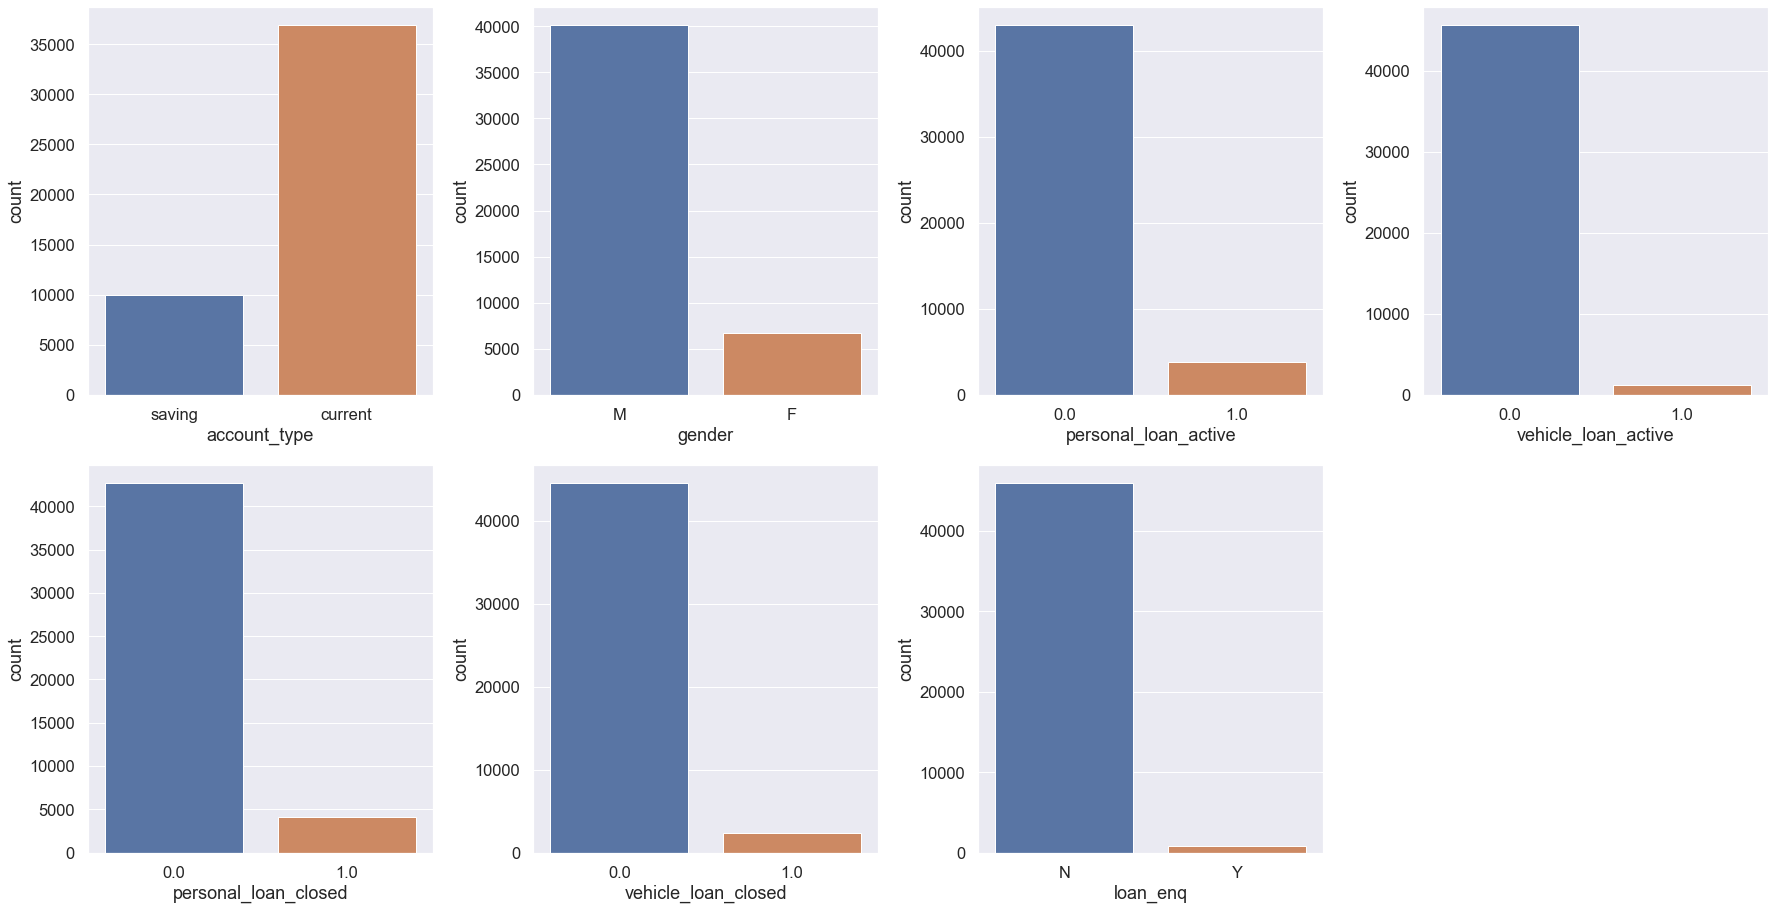

In [270]:
sns.set(font_scale=1.5)
fig = plt.figure(figsize=(25,25))
n = 1
for col in cc_spent[cat_cols]:
    plt.subplot(4,4,n)
    sns.countplot(cc_spent[col])
    n += 1
plt.tight_layout()
plt.show()
    

<b><font color='green'>Inferences from categorical features</font></b>
* Account type is of 'savings' and 'current'. 'current' account is mostly held by customers than savings account.

* Males are mostly spending credit/debit cards then Females.

* Personal_loans are either active or closed by 0.08% of customers

* Vechile_loans are also either active or closed (0.02-0.04)% of customers

* Loan_enquiry is carried out by 0.01% customers

<b><font color='green'> Distribution of continuous features</font></b>

In [271]:
cont_cols = []
for col in cc_spent.select_dtypes(["int64","float64"]):
    cont_cols.append(col)

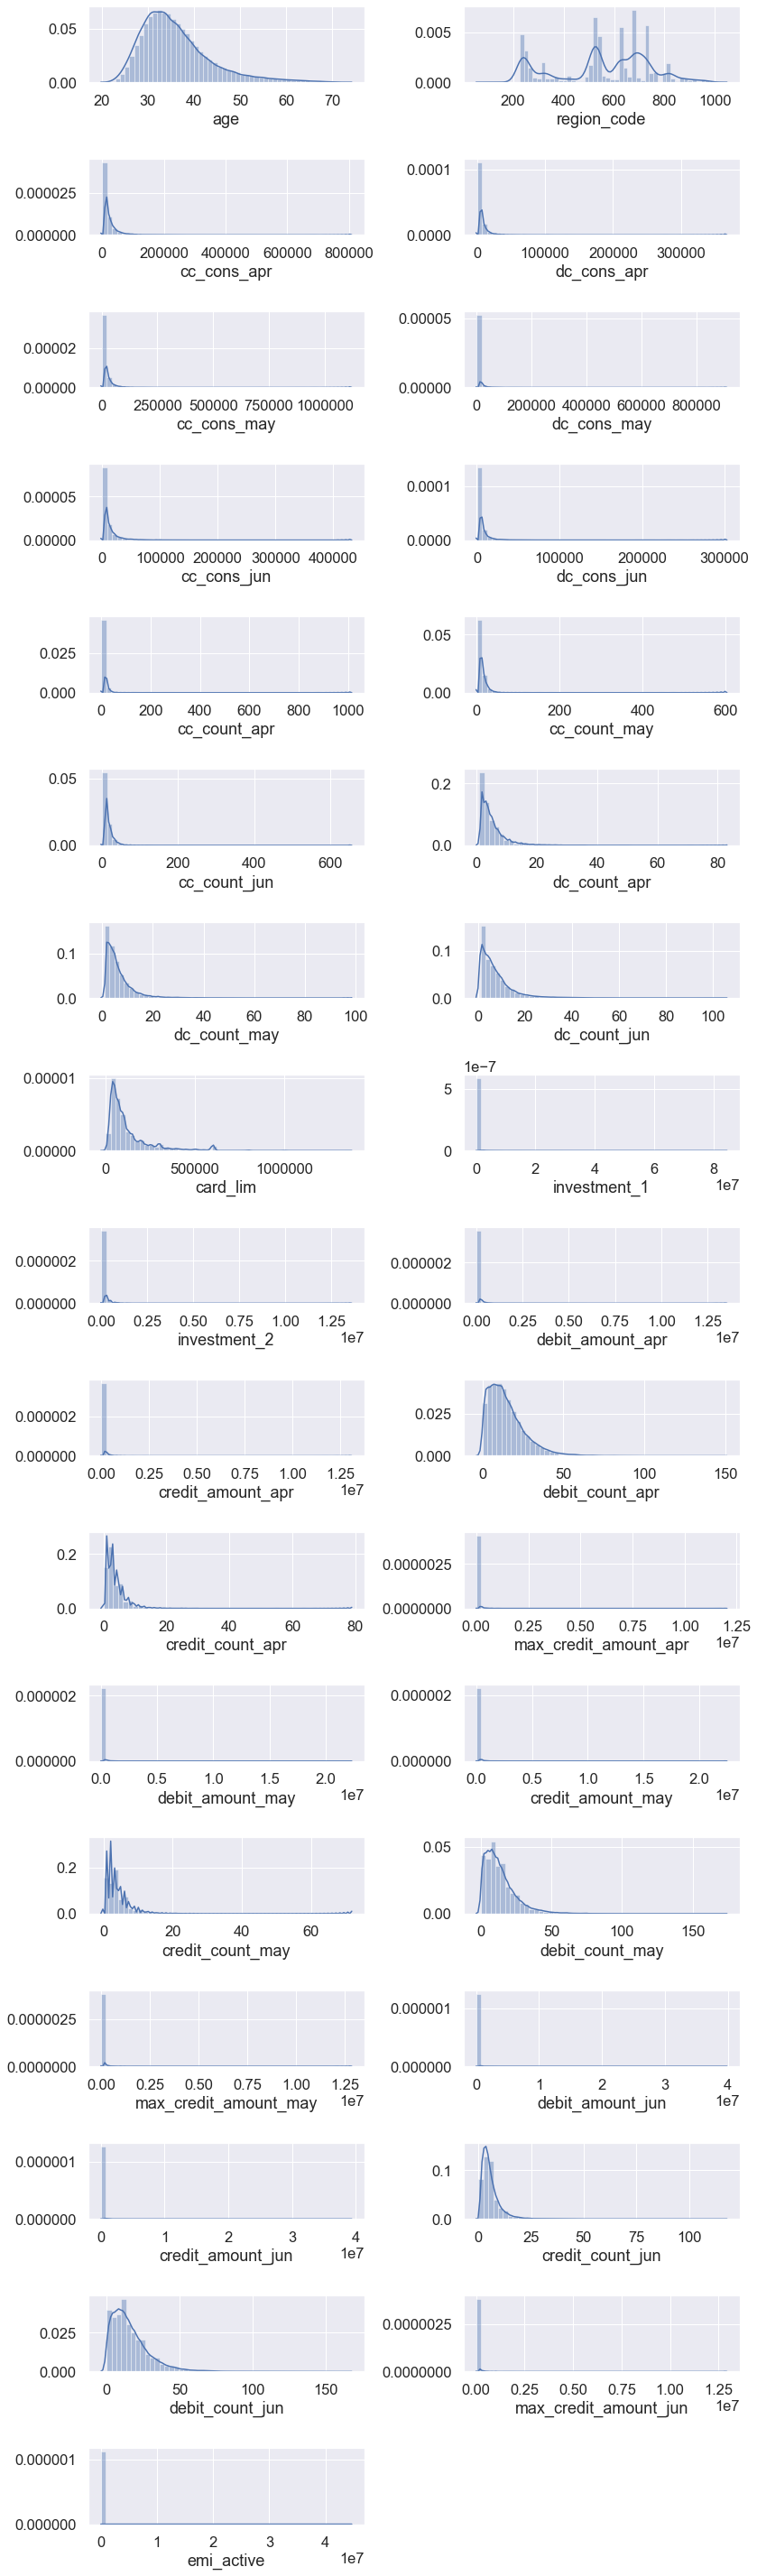

In [272]:
n=1
fig=plt.figure(figsize=(12,40))
for col in cc_spent_train[cont_cols]:
    if col !='cc_cons':
        plt.subplot(17,2,n)
        sns.distplot(cc_spent[col])
        n += 1

plt.tight_layout()
plt.show()

<b><font color='green'> Knowing the Skewness and Kurtosis of features</font></b>

<b><font color='green'> Skewness</font></b> : Skewness is a measure of the symmetry in a distribution.  A symmetrical dataset will have a skewness equal to 0.  So, a normal distribution will have a skewness of 0.   Skewness essentially measures the relative size of the two tails. 
    
<b><font color='green'> Kurtosis</font></b> : Kurtosis is a measure of the combined sizes of the two tails.
It measures the amount of probability in the tails. The value is often compared to the kurtosis
of the normal distribution , which is equal to 3. If the kurtosis is greater than 3, then the dataset
has heavier tails than a normal distribution.

Let us plot the skewed value and kurtosis value associated with each feature and get the inferences.

In [273]:
skew_dict = {}
kurtosis_dict = {}
for cols in cc_spent[cont_cols]:
    skew_dict[cols] = cc_spent[cols].skew()
    kurtosis_dict[cols] = cc_spent[cols].kurt()

In [274]:
skew_dict

{'age': 1.225560648348415,
 'region_code': -0.34628055293752047,
 'cc_cons_apr': 6.310478789580739,
 'dc_cons_apr': 10.855135024725246,
 'cc_cons_may': 8.51010496620857,
 'dc_cons_may': 29.38093633094697,
 'cc_cons_jun': 6.887952357972317,
 'dc_cons_jun': 9.446246293063933,
 'cc_count_apr': 36.626981931509974,
 'cc_count_may': 7.5802396984563964,
 'cc_count_jun': 5.800982538276105,
 'dc_count_apr': 3.52593290227643,
 'dc_count_may': 3.212584464726045,
 'dc_count_jun': 3.0480534189962465,
 'card_lim': 2.4453738236561584,
 'investment_1': 38.0705574161605,
 'investment_2': 20.75742786236415,
 'debit_amount_apr': 37.580905281333216,
 'credit_amount_apr': 37.05398582028272,
 'debit_count_apr': 1.6201207648547653,
 'credit_count_apr': 3.288824484906419,
 'max_credit_amount_apr': 50.71544582194808,
 'debit_amount_may': 65.879896071498,
 'credit_amount_may': 57.308793271569215,
 'credit_count_may': 3.4610221095465046,
 'debit_count_may': 1.8259533398476706,
 'max_credit_amount_may': 55.198148

In [275]:
skew_df = pd.DataFrame([skew_dict])
skew_trans_df = skew_df.T

In [276]:
skew_trans_df.columns = ['skewed_value']

In [277]:
skew_trans_df = skew_trans_df.sort_values(ascending=False,by=['skewed_value'])

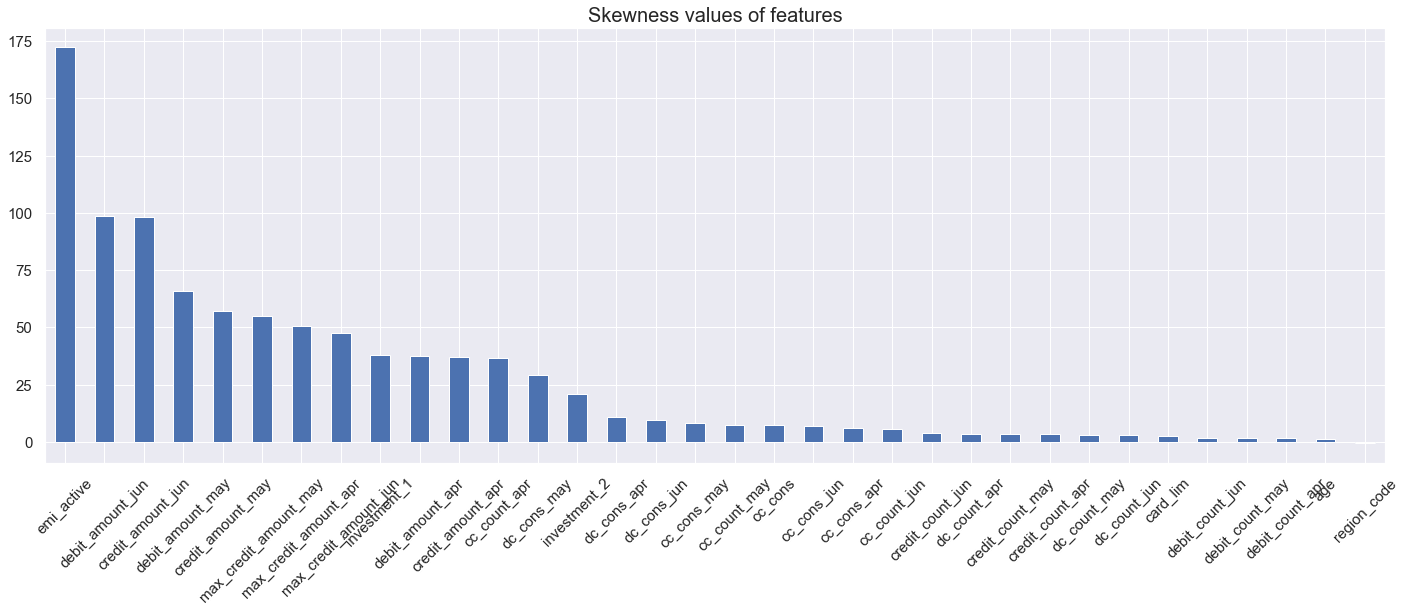

In [278]:
skew_trans_df.plot(kind='bar',figsize=(24,8),fontsize=15)
plt.legend("")
plt.xticks(rotation=45)
plt.title("Skewness values of features",fontsize=20)
plt.show()

<b><font color='green'> Inferences from above Skewness Plot</font></b>

* If skew value for features is < 0.5 it means it is symmetric. The above distplot also
depicts the columns 'age' and 'region_code' being symmetric. 
* While the other features have high skewness in them , column "emi_active" and "debit_amount_jun" are having highest skewness among them .If skew value > 1 , then feature is highly skewed towards right.
* Basic way to calculate skewness mathematically, is to use variance formula but the power needs to be changed to 3 from 2.

In [279]:
# Converting Kurtosis_dict to Kurtosis dataframe
kurtosis_df = pd.DataFrame([kurtosis_dict])
kurtosis_trans_df = kurtosis_df.T


In [280]:
kurtosis_trans_df.columns = ['kurtosis_value']

In [281]:
# Sorting values in descending order
kurtosis_trans_df = kurtosis_trans_df.sort_values(ascending=False, by=['kurtosis_value'])

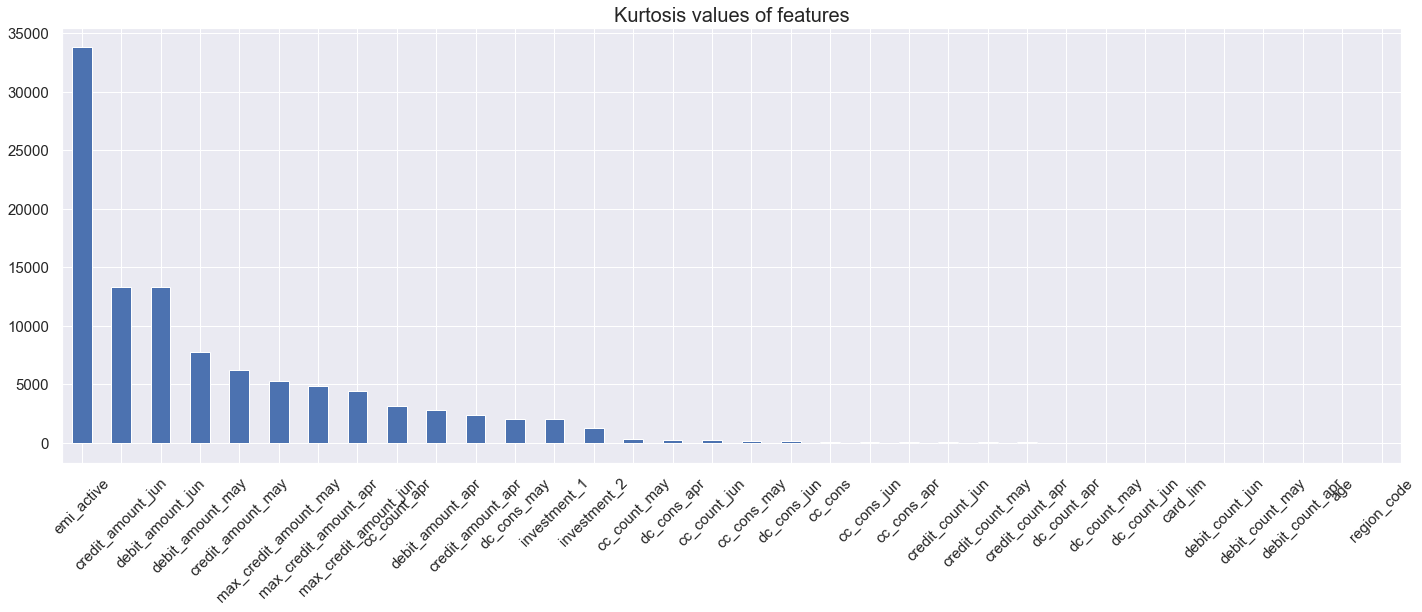

In [282]:
kurtosis_trans_df.plot(kind='bar',figsize=(24,8), fontsize=15)
plt.legend("")
plt.xticks(rotation=45)
plt.title("Kurtosis values of features",fontsize=20)
plt.show()

<b><font color='green'> Inferences from Kurtosis plot</font></b>

* The one which is having sharp peak has high kurtosis. One such feature is "emi_active".
* We cannot see any perfect normal distributions from graphs except age. Hence, the kurtosis values for those 
will be 0.
* The curve gets flattened for some features, they follow negative kurtosis. Features "region_code" and "age"
have negative kurtosis value.
* Basic way to calculate kurtosis mathematically, is to use variance formula but the power needs to be changed to 4 from 2.


<b><font color='green'> Inferences from continuous features</font></b>

These are mostly right-skewed and some have high kurtosis among them only exception to this feature "region_code",
which has negative skewness that means it follows symmetry and it is having flatter curve, as the kurtosis value says it.

<b><font color='green'>Analysis on the categorical features with the target (cc_cons) </font></b>

##### <font color='green'>Relationship between the account types and the credit card spent for next 3 months</font>

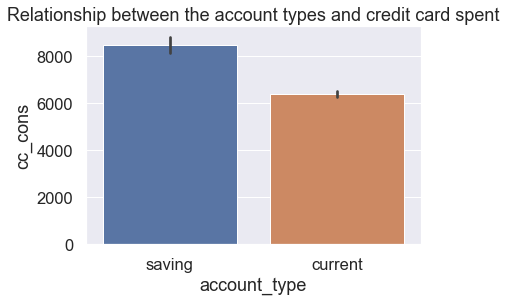

In [283]:
sns.barplot('account_type','cc_cons',data=cc_spent[:32820])
plt.title("Relationship between the account types and credit card spent")
plt.show()

Cardholders are mainly using savings account type for spending credit card for next 3 months.

Feature "Gender" would not help us in predicting the spending pattern of credit card. Hence, we won't be
analysis it.

##### <font color='green'> How age is a factor in knowning the credit card spend pattern??</font>

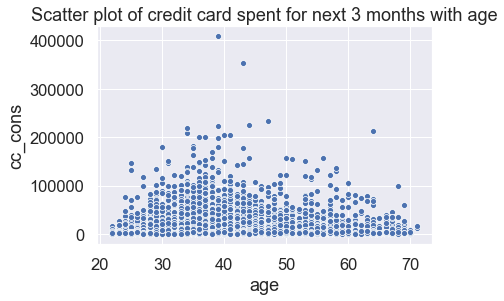

In [284]:
ax = sns.scatterplot(x='age',y='cc_cons', data=cc_spent[:32820])
plt.title("Scatter plot of credit card spent for next 3 months with age")
plt.show()

As we can see from the figure, the plot is pretty messy with a clear distinction for the age groups 20-45 indicating a person in this range has more possibility for credit card spendings. However, the most common spend range is up to 100000. 

Let's bin the age column for easy understanding and visualization.

In [285]:
print("Min Age of consumers' :",min(cc_spent['age']))
print("Max Age of consumers' :",max(cc_spent['age']))

Min Age of consumers' : 22
Max Age of consumers' : 72


<b> Age bins</b>

In [286]:
cc_spent['age_bins'] = pd.cut(cc_spent.age,bins=[21,31,41,51,61,72],labels=['Adult','Middle-Aged-I','Middle-Aged-II','Middle-Aged-III','Old Aged'])

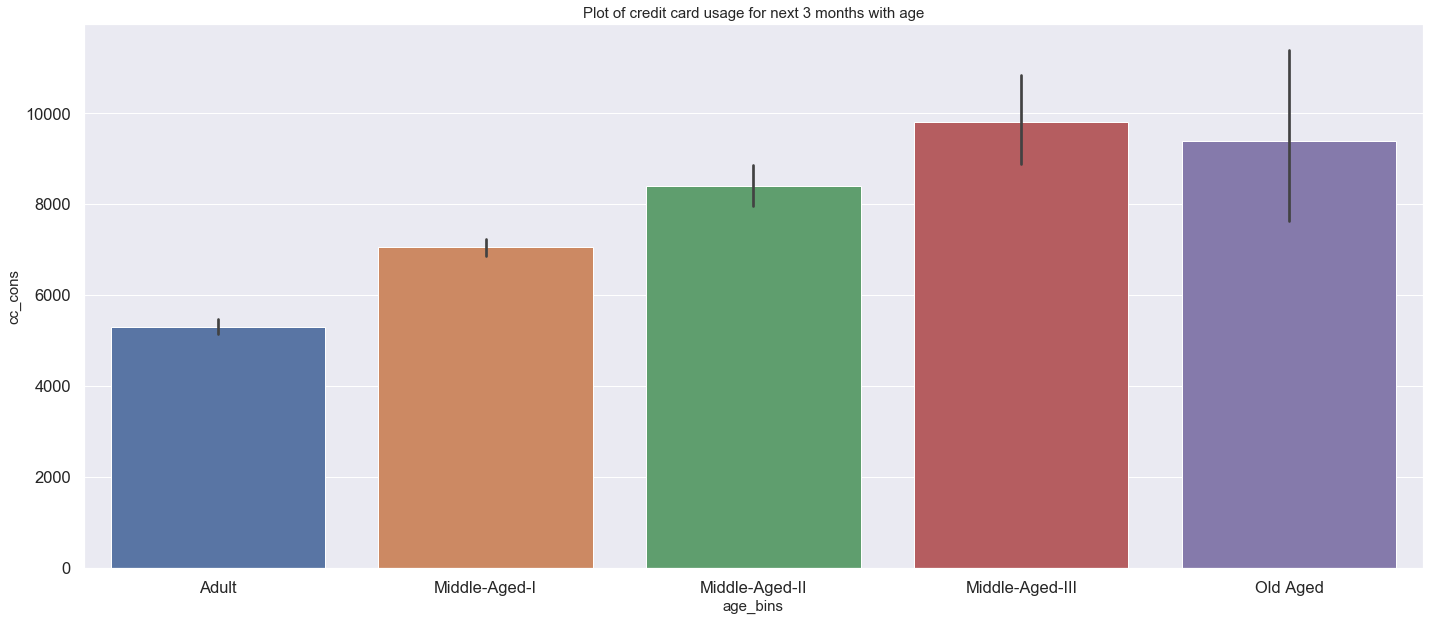

In [287]:
fig, ax = plt.subplots(figsize=(24,10))
sns.barplot('age_bins','cc_cons',data=cc_spent[:32820], ax=ax)
ax.set_xlabel('age_bins',fontsize=15)
ax.set_ylabel('cc_cons',fontsize=15)
plt.title("Plot of credit card usage for next 3 months with age",fontsize=15)
plt.show()

We observe that consumers who belong to Middle-Aged-III group comprising of ages 51-61 are the ones who will be spending a lot of credit amount in next few months. This could make sense because people in this age group are more likely to retire and they have necessity for extra money/credit. However, this might also be one of the riskiest groups to give credit since they might not have a stable income source following retirement.

##### <font color='green'> How maximum credit limit allocated is categorised for different age groups?</font>

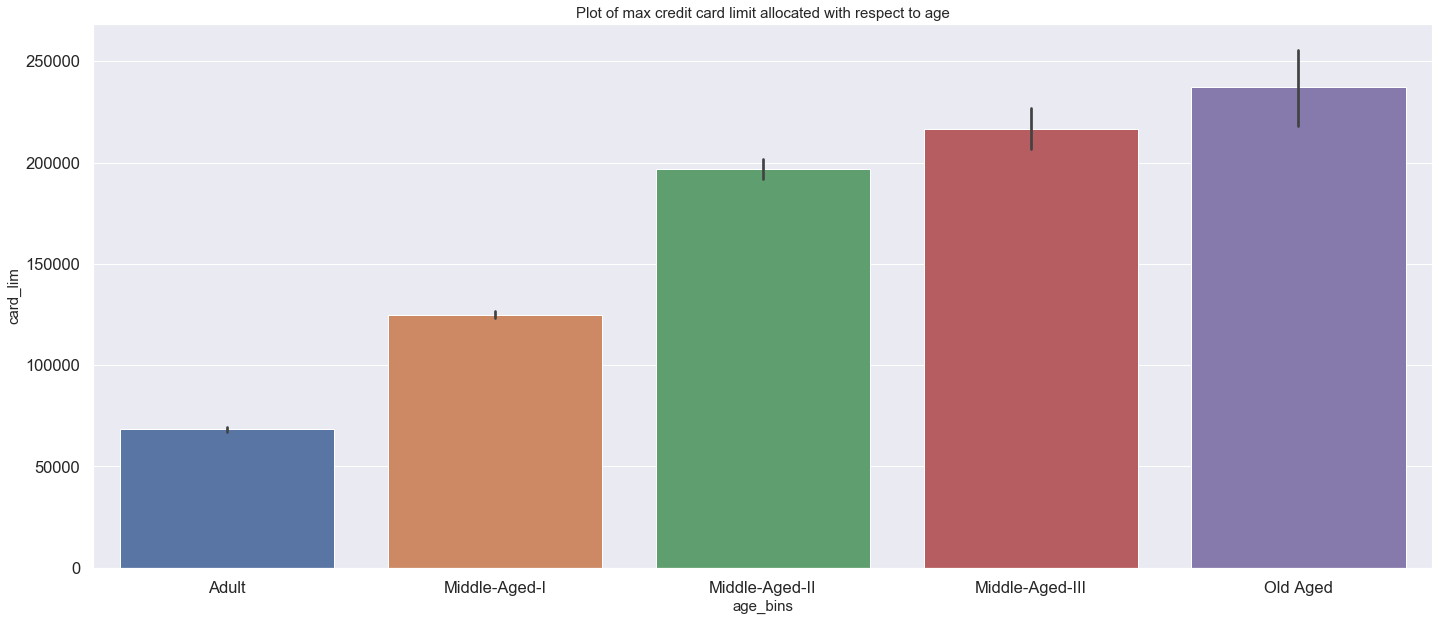

In [288]:
fig, ax = plt.subplots(figsize=(24,10))
sns.barplot('age_bins','card_lim',data=cc_spent[:32820], ax=ax)
ax.set_xlabel('age_bins',fontsize=15)
ax.set_ylabel('card_lim', fontsize=15)
plt.title("Plot of max credit card limit allocated with respect to age",fontsize=15)
plt.show()

We see that as the age increases the credit limit for consumers is also increasing. Also, it can be
that the older people are maintaining good track record of holding credit cards. But, chances are older people will not spend as much as the younger counter-parts so allocating higher credit limit is only going to keep the amount locked which otherwise can be distributed for other loyal younger customers.

##### <font color='green'> Analysing the debt increase with age</font>

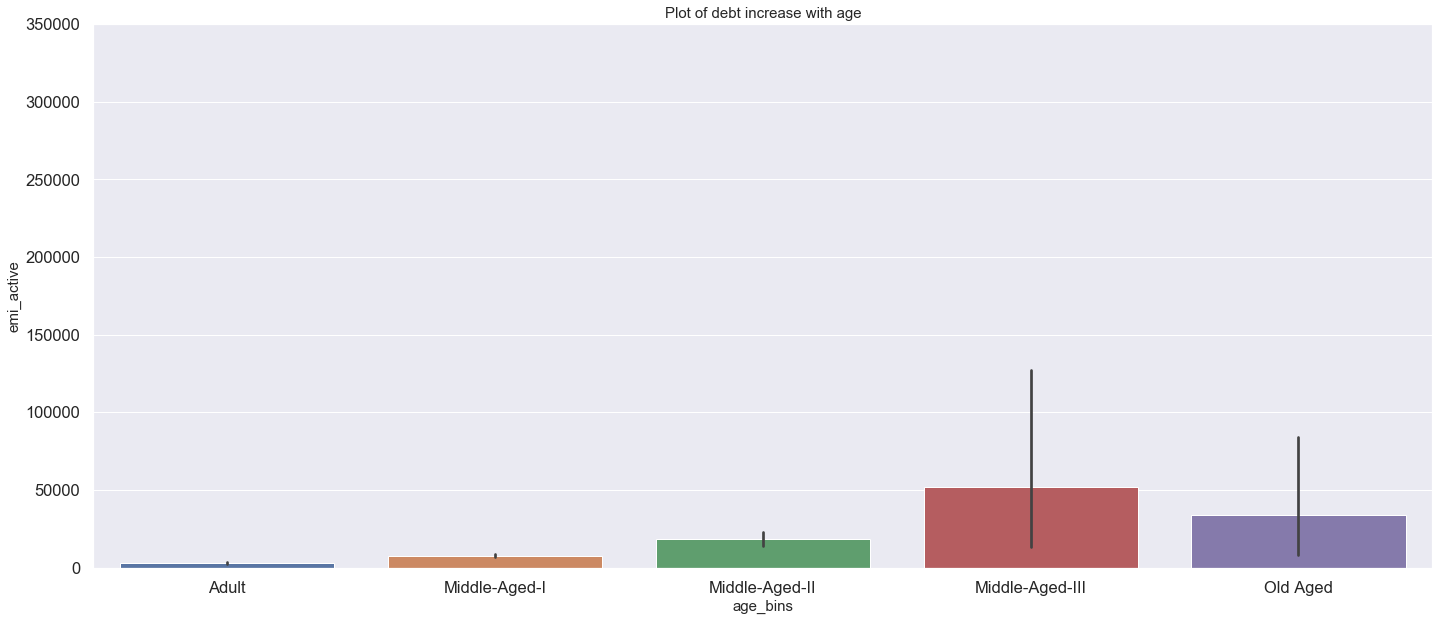

In [289]:
fig, ax = plt.subplots(figsize=(24,10))
sns.barplot('age_bins','emi_active',data=cc_spent[:32820], ax=ax)
ax.set_ylim(0,350000)
ax.set_xlabel('age_bins',fontsize=15)
ax.set_ylabel('emi_active', fontsize=15)
plt.title("Plot of debt increase with age",fontsize=15)
plt.show()

In this scenario, the debts are nothing but the emi's which the consumers owe to other banks. The debt's 
increase over age and is following a left-skewed distribution, where it reaches at peak for the Middle-Aged-III age group
and declines for the Old Aged.

##### <font color='green'> Why are such changes of credit card usage and debts occuring drastically??</font>

1. Credit cards help users to smooth over shocks.
2. By revolving debt over short and long terms, credit cards are a way of allocating life-cycle
consumption.
3. As a means of payment, spending on credit cards forms part of consumer expenditures.

##### <font color='green'> Which regions contribute most to spending of credit cards?</font>

Glimpse of the "region_code" column

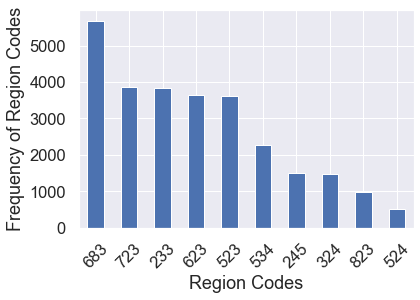

In [290]:
cc_spent['region_code'].value_counts()[:10].plot.bar()
plt.xticks(rotation=45)
plt.xlabel('Region Codes')
plt.ylabel('Frequency of Region Codes')
plt.show()

We see that cardholders/consumers are mostly from 683 region code followed by 723,233,623 and 523.

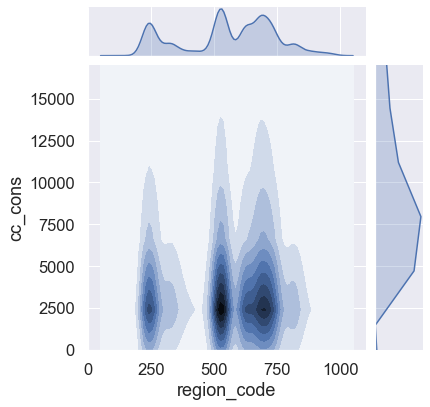

In [291]:
sns.jointplot(x="region_code", y="cc_cons", data=cc_spent, n_levels=10, kind="kde");
plt.ylim(0,17000)
plt.show()

From above figure, we can infer that for region_code between 500-600, the spaces between lines are quite dense which 
means many cardholders belong to these region who spend the most. While for regions between 600-800,
the lines are apart when less carholders spend in this region. Also, near 150-200 you again see some
dense region where the usage of credit cards is more.

#### <font color='green'> Understanding the pattern of credit card spent across April, May and June </font>

In [292]:
def cc_dc_pattern(df,col1,col2,col3,col4,col5,col6,low_xl,high_xl):
    sns.set()
    fig, (ax1,ax2) = plt.subplots(2, 1, sharex=True,figsize=(12,8))
    ax1 = plt.subplot(2, 1, 1)
    ax1 = sns.distplot(df[col1], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label=col1)
    ax1= sns.distplot(df[col2],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col2)
    ax1= sns.distplot(df[col3],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col3)
    ax1.set_xlabel("")
    ax1.set_title("Credit Cards/Amount in April, May and June months")
    plt.xlim(low_xl, high_xl)
    
    print("")
    
    ax2 = plt.subplot(2, 1, 2)
    ax2 = sns.distplot(df[col4], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label=col4)
    ax2= sns.distplot(df[col5],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col5)
    ax2= sns.distplot(df[col6],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label=col6)
    ax2.set_xlabel("")
    ax2.set_title("Debit Cards/Amount in April, May and June months")
    plt.xlim(low_xl, high_xl)
    
    plt.tight_layout()
    plt.show()
    
    
    
    

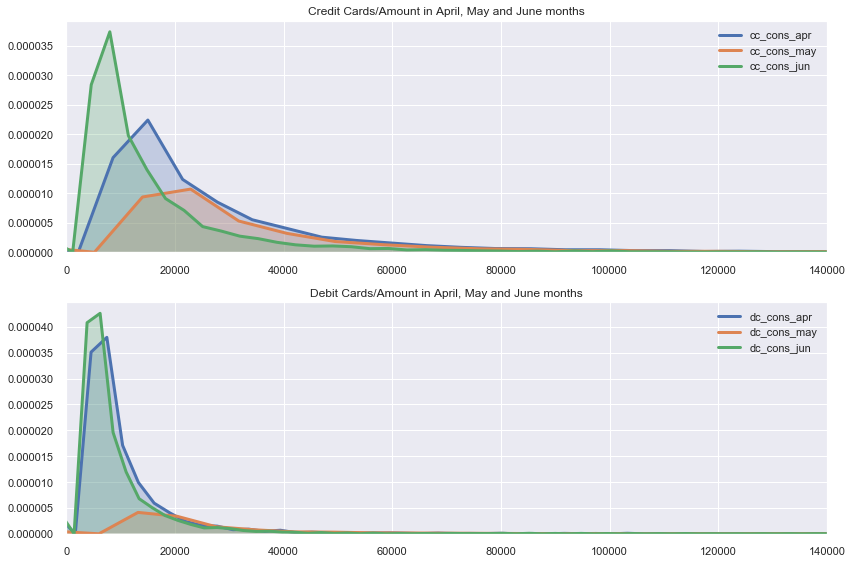

In [293]:
cc_dc_pattern(cc_spent,'cc_cons_apr','cc_cons_may','cc_cons_jun','dc_cons_apr','dc_cons_may',
              'dc_cons_jun',0,140000)

In [294]:
cc_cons_lst = ['cc_cons_apr','cc_cons_may','cc_cons_jun']
dc_cons_lst = ['dc_cons_apr','dc_cons_may','dc_cons_jun']

In [295]:
cc_spent[cc_cons_lst].describe()


,cc_cons_apr,cc_cons_may,cc_cons_jun
count,46828.000000,4.682800e+04,46828.000000
mean,16582.654632,1.433700e+04,8939.360578
std,24907.564428,2.324723e+04,15619.012047
min,233.970000,1.030000e+02,51.000000
25%,3689.952500,2.970467e+03,1625.915000
50%,8893.640000,7.338210e+03,4107.500000
75%,19894.335000,1.679651e+04,10010.030000
max,804712.580000,1.117246e+06,429522.430000


<b><font color='darkpink'>Credit Cards spending pattern(April, May and June)</font></b>
1. We see that deviation for month of June is around 15000+ compared to May and April months which have deviations of 25000+.
2. So, we see a narrow curve in June in comparison to May and April months.
3. Also, IQR values for June Month is about 8000+ and for May and April it's about 13000+ and 16000+ respectively.


In [296]:
cc_spent[dc_cons_lst].describe()

,dc_cons_apr,dc_cons_may,dc_cons_jun
count,46828.000000,46828.000000,46828.000000
mean,5114.357183,5222.923964,4372.687838
std,8590.970404,10973.195692,7169.398369
min,10.010000,20.000000,23.000000
25%,1278.000000,1242.736905,1218.619500
50%,2895.420000,2794.754663,2434.978324
75%,5881.958854,5660.252500,4815.894414
max,366223.160000,911223.490000,301991.940000


<b><font color='darkpink'>Debit Cards spending pattern(April, May and June)</font></b>

1. The deviation for April and June month is about 8000+ and 7000+ , as compared to April and May, which shows people have spent very less debit cards
compared to April and May.
2. Also, we observe that the curves are right-skewed as the mean are greater than median.
3. IQR is about 3000+ and 4500+ for June , April and May months respectively, which means the debit spent in these 3 months lie in this ranges.

<b><font color='green'>Debit/Credit card usage pattern individually for 3 months through mean and std</font></b>

In [297]:
# Credit cards spent(mean and std)
cc_spent['cc_spent_monthly_average'] =(cc_spent['cc_cons_apr'] + cc_spent['cc_cons_may'] + cc_spent['cc_cons_jun']) / 3
cc_spent['cc_spent_monthly_deviation'] = cc_spent[cc_cons_lst].std(axis=1)

In [298]:
# Finding the correlation matrix w.r.t target 'cc_cons'
cc_cons_corr_lst= ['cc_spent_monthly_average', 'cc_spent_monthly_deviation','cc_cons']
cc_spent[cc_cons_corr_lst].corr()

,cc_spent_monthly_average,cc_spent_monthly_deviation,cc_cons
cc_spent_monthly_average,1.000000,0.826096,0.432701
cc_spent_monthly_deviation,0.826096,1.000000,0.288819
cc_cons,0.432701,0.288819,1.000000


We see that 43% of consumers are likely to spend in the same way for next 3 months . However, 28% of consumers
are a bit inconsistent in their spending pattern for avg of next 3 months.

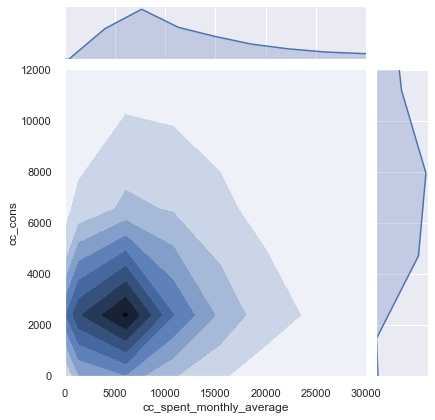

In [299]:
plot = sns.jointplot(x='cc_spent_monthly_average',y='cc_cons',data=cc_spent, kind='kde')
plot.ax_marg_x.set_xlim(0,30000)
plot.ax_marg_y.set_ylim(0,12000)
plt.show()

The above graph shows a darker region around 0-10000, which is nothing but the credit amount being
spent on an average basis. However, the credit amount spent for next 3 months is around 1500-3000 range.
This indicates many consumers are spending credit card in this region. As the shape of the figure expands,
it becomes lighter and lighter which means there are few consumers spending credit amount in this region. 

##### <font color='green'> Credit card spending ratio by checking the card limit</font>

The credit card spending ratio is calculated by dividing the average amount spent on credit card to the credit card limit allocated .

In [300]:
cc_spent['cc_spent_ratio'] = cc_spent['cc_spent_monthly_average'] / cc_spent['card_lim']

In [301]:
# Retaining the decimal places to only 4 and taking a percentage among 100.
cc_spent['cc_spent_ratio'] = cc_spent['cc_spent_ratio'].round(4) * 100

In [302]:
cc_spent['cc_spent_ratio'].head()

0     1.95
1    15.85
2    17.25
3     1.93
4     1.93
Name: cc_spent_ratio, dtype: float64

Let us now find out the relationship of the spent ratio with the credit card spent in next 3 months.

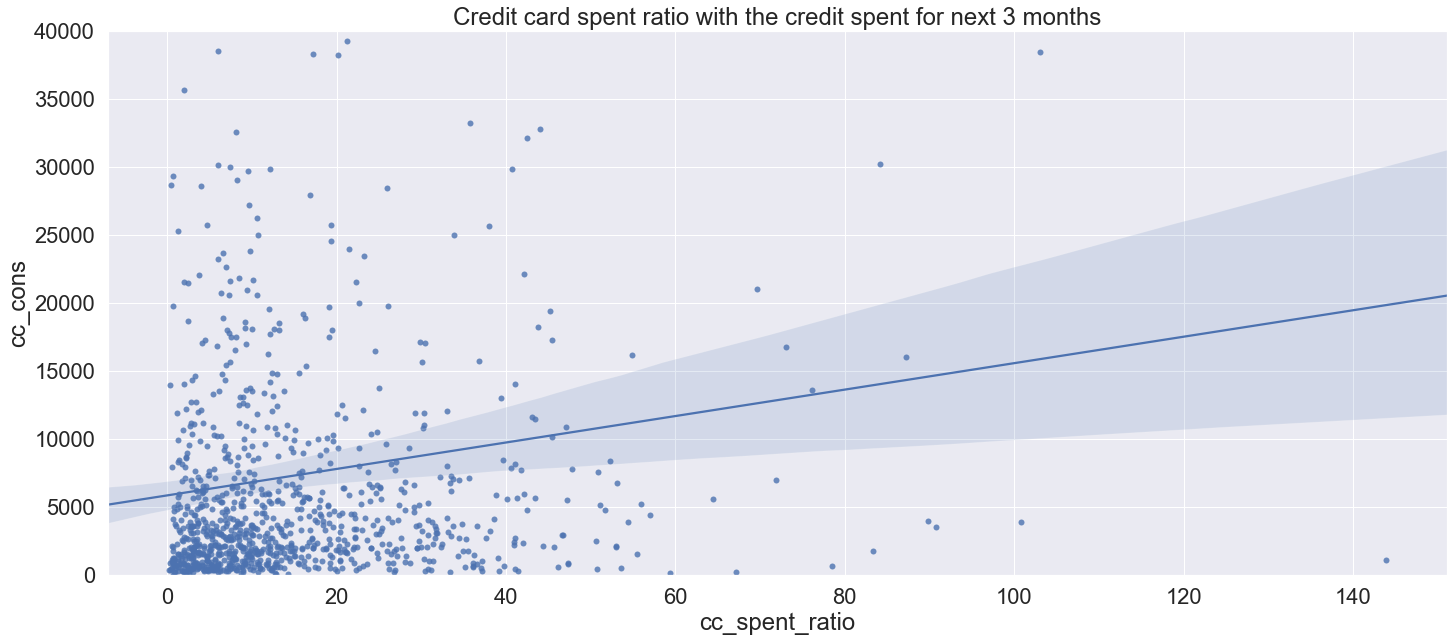

In [303]:
sns.set(rc={'figure.figsize':(24,10)}, font_scale=2)
ax = sns.regplot(x='cc_spent_ratio', y='cc_cons', data=cc_spent[:1000])
ax.set(ylim=(0,40000))
plt.title("Credit card spent ratio with the credit spent for next 3 months")
plt.show()

We see that there is more concentration in spent_ratio region i.e 0-20. We also observe that there is a direct
correlation of spent ratio with the credit amount being spent for next 3 months.

##### <font color='green'> How increase in credit spent causes increase in debt ?</font>

We often foresight that if the credit amount being spent increases, there might be chances that the
debt also increases. Let us understand this better through a graph.

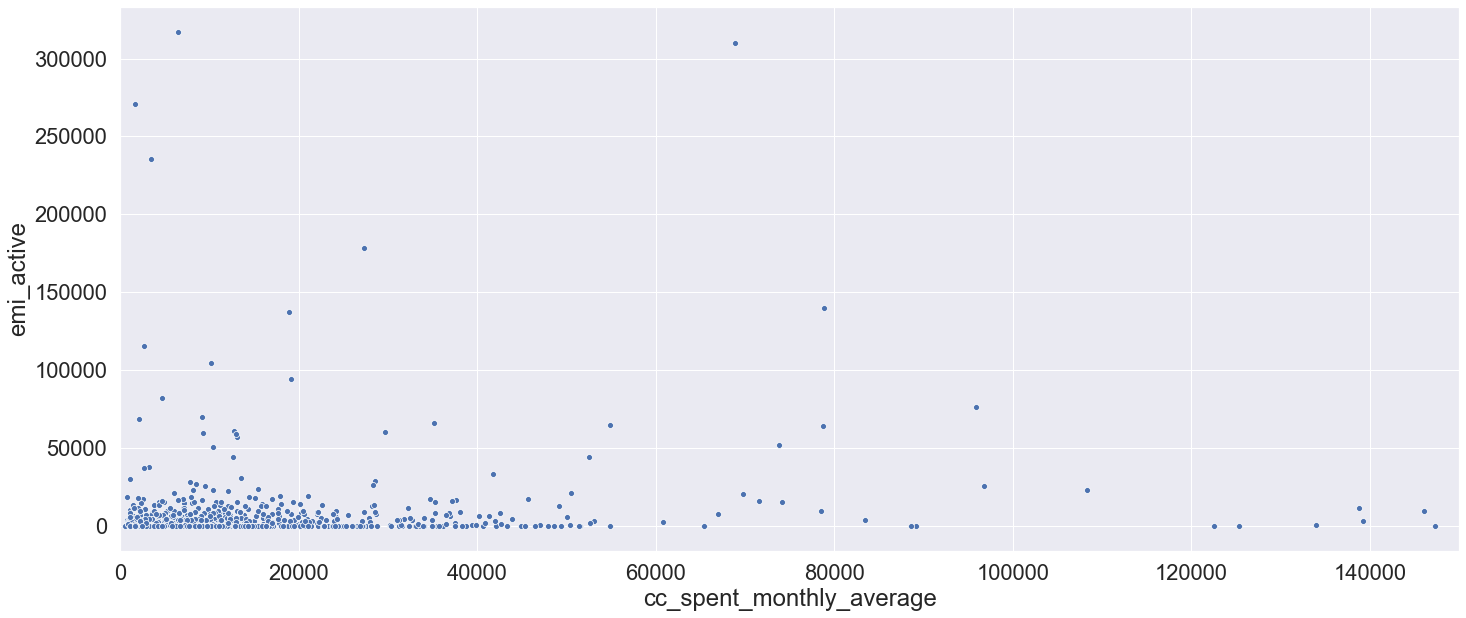

In [304]:
ax = sns.scatterplot(x='cc_spent_monthly_average',y='emi_active',data=cc_spent[:1000])
ax.set_xlim(0,150000)
plt.show()

Above graph says , even  though the rate of spending credit card is increasing across the scale
the active loans/debts being paid is not enormous , except few cases that may lead to bankruptcy.

##### <font color='green'> Debit card spending pattern by consumers</font>

In [305]:
## Debit Cards
cc_spent['dc_spent_monthly_average'] =(cc_spent['dc_cons_apr'] + cc_spent['dc_cons_may'] + cc_spent['dc_cons_jun']) / 3
cc_spent['dc_spent_monthly_deviation'] = cc_spent[dc_cons_lst].std(axis=1)

In [306]:
# Finding the correlation matrix w.r.t target 'cc_cons'
dc_cons_corr_lst= ['dc_spent_monthly_average','dc_spent_monthly_deviation','cc_cons']
cc_spent[dc_cons_corr_lst].corr()

,dc_spent_monthly_average,dc_spent_monthly_deviation,cc_cons
dc_spent_monthly_average,1.000000,0.894249,0.050005
dc_spent_monthly_deviation,0.894249,1.000000,0.029923
cc_cons,0.050005,0.029923,1.000000


We hardly see any correlation of debit cards with the spending pattern of credit card for the next 3 months.

Let us see the correlation between monthly average of credit card spent and debit card spent.

In [307]:
cc_dc_cons = ['cc_spent_monthly_average','dc_spent_monthly_average','cc_spent_monthly_deviation',
              'dc_spent_monthly_deviation']
cc_spent[cc_dc_cons].corr()


,cc_spent_monthly_average,dc_spent_monthly_average,cc_spent_monthly_deviation,dc_spent_monthly_deviation
cc_spent_monthly_average,1.000000,0.058176,0.826096,0.043583
dc_spent_monthly_average,0.058176,1.000000,0.052956,0.894249
cc_spent_monthly_deviation,0.826096,0.052956,1.000000,0.043477
dc_spent_monthly_deviation,0.043583,0.894249,0.043477,1.000000


We aren't finding any correlation between credit card spent on an average month and debit card spent on an average monthly basis.

#### <font color='green'>Understanding the number of credit card transactions for the month of April, May and June </font>

In [ ]:
cc_dc_pattern(cc_spent,'cc_count_apr','cc_count_may','cc_count_jun','dc_count_apr',
             'dc_count_may','dc_count_jun',0,160)


In [309]:
cc_count_lst = ['cc_count_apr','cc_count_may','cc_count_jun']
dc_count_lst = ['dc_count_apr','dc_count_may','dc_count_jun']

In [310]:
cc_spent[cc_count_lst].describe()

,cc_count_apr,cc_count_may,cc_count_jun
count,46828.000000,46828.000000,46828.000000
mean,8.900534,9.310090,11.987296
std,10.915212,9.311745,11.299198
min,1.000000,1.000000,1.000000
25%,3.000000,3.000000,4.000000
50%,6.000000,7.000000,9.000000
75%,12.000000,12.608964,16.000000
max,1012.000000,601.000000,653.000000


<b><font color='darkpink'>Number of Credit card transactions in April, May and June</font></b>

The transactions for May month is quite sharp , as there are less deviation in the pattern. That means most people are
doing transactions in the same range. For June month , also it follows the same pattern.When you see the April Month, the max value is quite large. So, it means there are
high transactions in this month.

In [311]:
cc_spent[dc_count_lst].describe()

,dc_count_apr,dc_count_may,dc_count_jun
count,46828.000000,46828.000000,46828.000000
mean,4.694322,5.877343,7.426692
std,4.574215,5.683014,7.432590
min,1.000000,1.000000,1.000000
25%,1.983971,2.042200,2.655868
50%,3.421598,4.237080,5.393221
75%,6.000000,7.472168,9.682250
max,82.000000,97.000000,104.000000


<b><font color='darkpink'>Number of Debit card transactions in April, May and June</font></b>


June month has little variation compared to the rest two. Hence, it has maximum debit card transactions
done.

<b><font color='dark pink'>Comparison of Debit/Credit Transactions for April, May and June months</font>

1. Credit transactions are carried out more than the debit transactions.
2. Credit transaction for April are carried out in the range of 9 with a maximum transaction reaching
upto 1000+. While the debit transactions done by people is around 7 with the max one reaching 104 
in the June month.
3. The curves in Debit transactions all overlap each other and are right skewed.

<b><font color='dark pink'> Debit/Card Transactions carried out on an individual level</font></b>

In [312]:
# Credit Transactions
cc_spent['cc_trans_monthly_avg'] =(cc_spent['cc_count_apr'] + cc_spent['cc_count_may'] + cc_spent['cc_count_jun']) / 3
cc_spent['cc_trans_monthly_deviation'] = cc_spent[cc_count_lst].std(axis=1)

In [313]:
# Finding the correlation matrix w.r.t target 'cc_cons'
cc_count_corr_lst = ['cc_trans_monthly_avg','cc_trans_monthly_deviation','cc_cons']
cc_spent[cc_count_corr_lst].corr()

,cc_trans_monthly_avg,cc_trans_monthly_deviation,cc_cons
cc_trans_monthly_avg,1.000000,0.607863,0.097377
cc_trans_monthly_deviation,0.607863,1.000000,0.058261
cc_cons,0.097377,0.058261,1.000000


We don't observe any relation with credit card transactions helping us predict the credit card spent for next 3 months.

On knowing the credit card transactions, let us calculate the weighted average of credit card amount
being spent , considering the transactions as the weights and get the insights.

In [314]:
# Let us get the weighted average of amount spent by considering weights of transactions
cc_spent['weighted_avg_cc_cons'] = ((cc_spent['cc_cons_apr'] * cc_spent['cc_count_apr'])
                                  + (cc_spent['cc_cons_may'] * cc_spent['cc_count_may'])
                                  + (cc_spent['cc_cons_jun'] * cc_spent['cc_count_jun'])) / (cc_spent['cc_count_apr'] + cc_spent['cc_count_may'] + cc_spent['cc_count_jun'])

In [315]:
weigh_avg_cc_lst = ['weighted_avg_cc_cons','cc_cons']
cc_spent[weigh_avg_cc_lst].corr()

,weighted_avg_cc_cons,cc_cons
weighted_avg_cc_cons,1.000000,0.420897
cc_cons,0.420897,1.000000


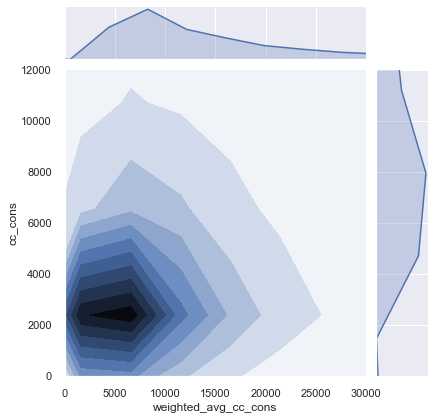

In [316]:
plot = sns.jointplot(x='weighted_avg_cc_cons',y='cc_cons',data=cc_spent, kind='kde')
plot.ax_marg_x.set_xlim(0,30000)
plot.ax_marg_y.set_ylim(0,12000)
plt.show()

However, we are observing the same kind of graph through the weighted average as well.

#### <font color='green'> How debit transactions would be helpful in knowing the credit card spending pattern??</font>

In [317]:
# Debit Transactions
cc_spent['dc_trans_monthly_avg']=  (cc_spent['dc_count_apr'] + cc_spent['dc_count_may'] + cc_spent['dc_count_jun']) / 3
cc_spent['dc_trans_monthly_deviation'] = cc_spent[dc_count_lst].std(axis=1)

In [318]:
# Finding the correlation matrix w.r.t target 'cc_cons'
dc_count_corr_lst = ['dc_trans_monthly_avg','dc_trans_monthly_deviation','cc_cons']
cc_spent[dc_count_corr_lst].corr()

,dc_trans_monthly_avg,dc_trans_monthly_deviation,cc_cons
dc_trans_monthly_avg,1.000000,0.709309,0.010717
dc_trans_monthly_deviation,0.709309,1.000000,0.004069
cc_cons,0.010717,0.004069,1.000000


As with the credit card transactions, we see the same scenario with the debit card as well , no correlation with
the spending pattern . Also, we aren't getting much insights through debit which would help us in 
predicting the credit card amount being spent.

<b><font color='dark pink'> Total amount credited/debited for the months of April, May and June</font></b>


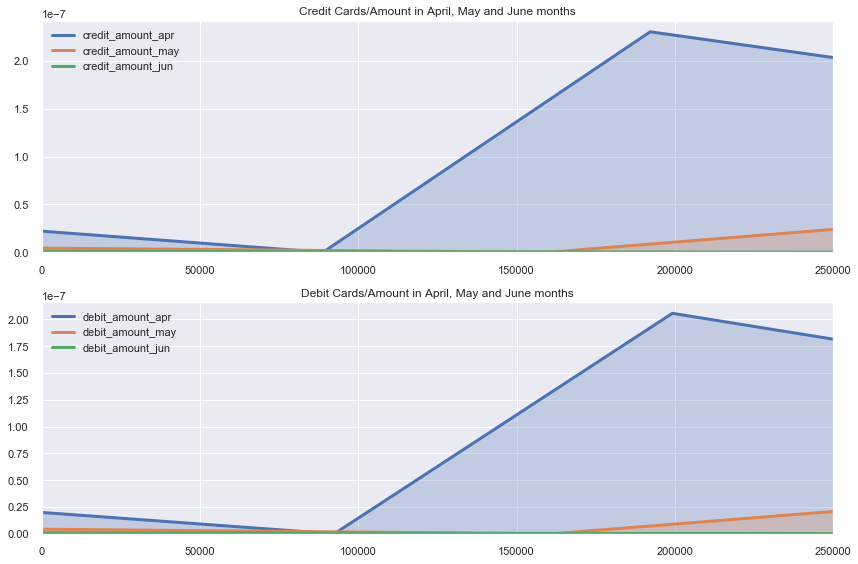

In [319]:
cc_dc_pattern(cc_spent,'credit_amount_apr','credit_amount_may','credit_amount_jun',
             'debit_amount_apr','debit_amount_may','debit_amount_jun',0,250000)



In [320]:
credit_amt_lst = ['credit_amount_apr','credit_amount_may','credit_amount_jun']
cc_spent[credit_amt_lst].describe()

,credit_amount_apr,credit_amount_may,credit_amount_jun
count,4.682800e+04,4.682800e+04,4.682800e+04
mean,7.053248e+04,7.484739e+04,7.443937e+04
std,1.631341e+05,1.750375e+05,2.603919e+05
min,3.432000e+01,1.061000e+01,1.188000e+01
25%,2.274738e+04,2.253025e+04,2.346175e+04
50%,4.161100e+04,4.340575e+04,4.349113e+04
75%,7.595900e+04,8.511600e+04,8.044825e+04
max,1.310058e+07,2.246350e+07,3.933931e+07


<b><font color='dark pink'> Observations from graph on Total number of credit amount in months of April, May and June</font></b>

1. June month is having wide fluctuation from the months of May and April .
2. When we look at the IQR's for June, May and April respectively we achieve about 56000+, 62000+ and
53000+ credit amounts respectively. But when it comes to the maximum value of credit amount it is upto 1000000+ for April month respectively
which is such a huge gap from 53000+ to 10000000+. Hence, you can see a wider curve for April.

In [321]:
debit_amount_lst = ['debit_amount_apr','debit_amount_may','debit_amount_jun']
cc_spent[debit_amount_lst].describe()

,debit_amount_apr,debit_amount_may,debit_amount_jun
count,4.682800e+04,4.682800e+04,4.682800e+04
mean,6.822262e+04,6.478576e+04,7.470313e+04
std,1.503305e+05,1.638669e+05,2.636445e+05
min,4.010000e+00,1.500000e-01,5.230000e+00
25%,2.188393e+04,1.924063e+04,2.444255e+04
50%,4.082497e+04,3.759313e+04,4.564901e+04
75%,7.439500e+04,7.213519e+04,8.270280e+04
max,1.353571e+07,2.230122e+07,3.986881e+07


<b><font color='dark pink'>Observations on Total Debit Amount for months of (Apr,May and June)</font></b>

1. There is an interesting observation in this graph which we haven't come across from the previous
graphs. We see that the minimum debit amount for may is around -0.15 which means people have execessively spent
from their debit accounts, and there is no debit balance left. To make the balances to  positive, 
some amount needs to be credited to their respective accounts, till it reaches some debit amount limits, based
on the type of account they hold "current" or "savings".

2. Some deviation in pattern is in observed for June month.

3. April and May months graph almost overlap each other.

<font color='dark pink'><b>Knowing the Credit/Debit Amount spent individually for 3 months</b></font>

In [322]:
# Credit Card
# Monthly Avg
cc_spent['cc_amount_monthly_avg'] = (cc_spent['credit_amount_apr'] + cc_spent['credit_amount_may'] +
                                               cc_spent['credit_amount_jun']) / 3
# Std Deviation

cc_spent['cc_amount_monthly_std'] = cc_spent[credit_amt_lst].std(axis=1)

In [323]:
cc_amt_corr_lst = ['cc_amount_monthly_avg','cc_amount_monthly_std','cc_cons']
cc_spent[cc_amt_corr_lst].corr()

,cc_amount_monthly_avg,cc_amount_monthly_std,cc_cons
cc_amount_monthly_avg,1.000000,0.893329,0.101489
cc_amount_monthly_std,0.893329,1.000000,0.078332
cc_cons,0.101489,0.078332,1.000000


Here, too the correlation between monthly avg . credit amount and std. deviation is ~9.5% and ~6.5%
respectively, which is very low. That means the total credit amount doesn't help us in determining the spending pattern.

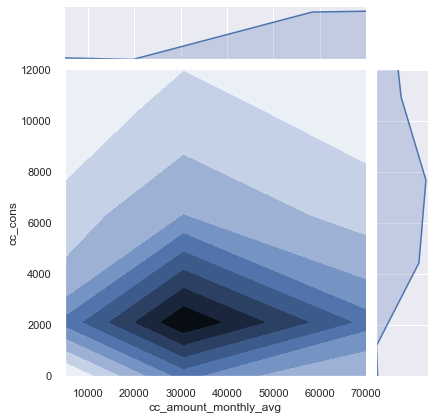

In [324]:
plot = sns.jointplot(x='cc_amount_monthly_avg',y='cc_cons',data=cc_spent[:15000], kind='kde')
plot.ax_marg_x.set_xlim(5000,70000)
plot.ax_marg_y.set_ylim(0,12000)
plt.show()

Credit amount being spent on a monthly basis is aroung 10000-70000 and the expected credit amount to
be spent for next 3 months is in the range (1500-6000).

##### <font color='green'> Plotting of credit amount with age</font>

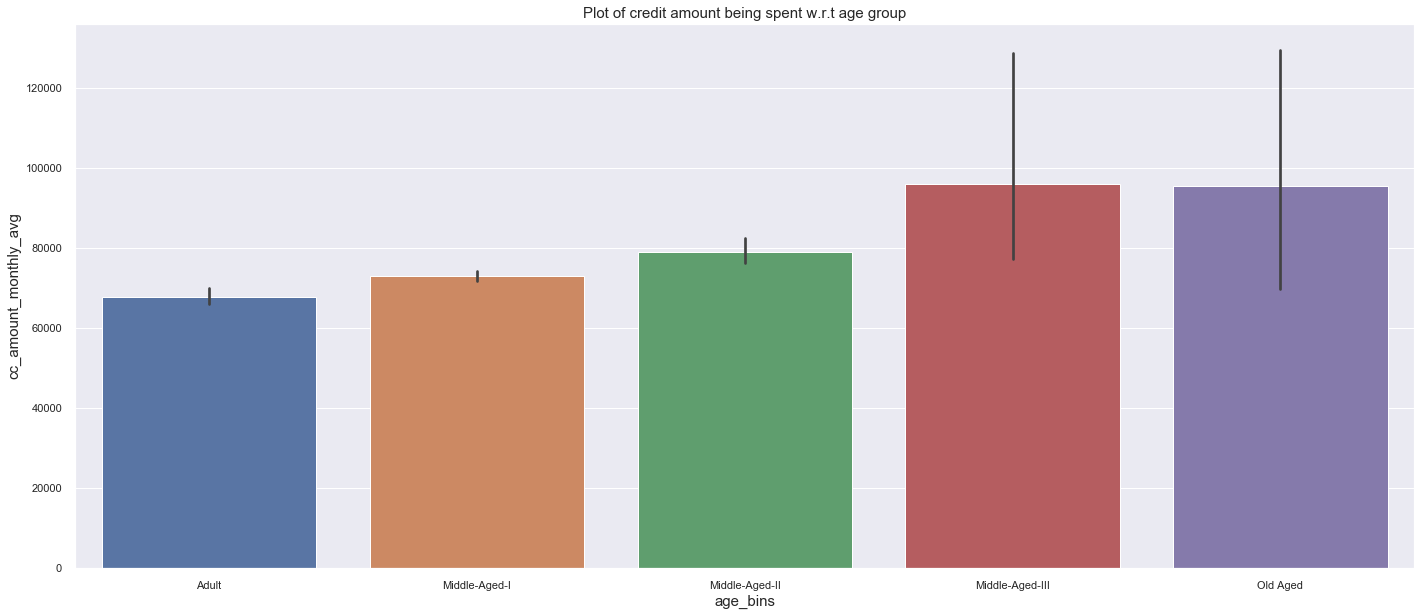

In [325]:
fig, ax = plt.subplots(figsize=(24,10))
sns.barplot('age_bins','cc_amount_monthly_avg',data=cc_spent, ax=ax)
ax.set_xlabel('age_bins',fontsize=15)
ax.set_ylabel('cc_amount_monthly_avg', fontsize=15)
plt.title("Plot of credit amount being spent w.r.t age group",fontsize=15)
plt.show()



We see that the credit amount being spent is increasing with age . Since , these categories save a lot
so they might be finding best deals with prices and with cashback available spending credit amount.

#### <font color='green'> Plot of credit amount with age and loans active </font>

Let's first see the distribution across column "emi_active"

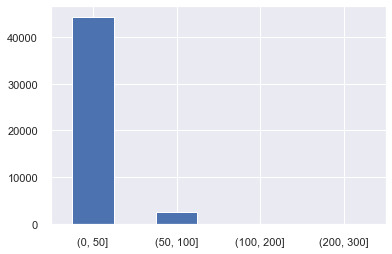

In [326]:
emi = pd.cut(cc_spent.age,bins=[0,50,100,200,300])
ax = emi.value_counts(sort=False).plot.bar(rot=0,color="b",figsize=(6,4))
plt.show()

Now, we observe that most of the customers don't have emi's in active state as the graph depicts it.

Let us further analyse the emi's active based on the credit amount being spent based on the age.

In [327]:
cc_spent['emi_bins'] = pd.cut(cc_spent.emi_active,bins=[0,50,100,200,300],labels=['nil_debts','v.less_debts','less_debts','decent_debts'])

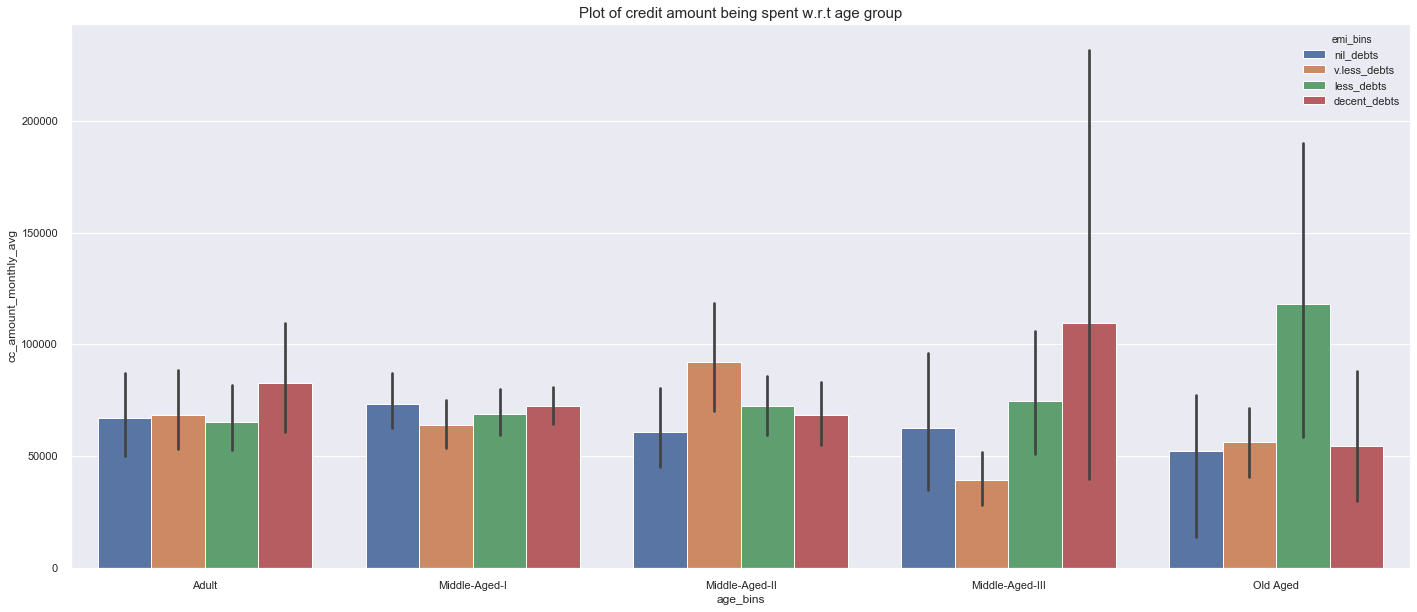

In [328]:
fig, ax = plt.subplots(figsize=(24,10))
ax = sns.barplot(x='age_bins',y='cc_amount_monthly_avg',hue='emi_bins',data=cc_spent)
plt.title("Plot of credit amount being spent w.r.t age group",fontsize=15)
plt.show()

We get following inferences from above graph:-
1. Customers having nil debts mostly belong to middle-age-I group and their spending pattern is around
(0-5000)
2. Customers with very less debts belong to middle-age-II group(40-50) and their spending pattern is 
around (0-80000)
3. Less debts is consumed by old age groups(60-70)range and their average spending pattern raises above 100000
4. Decent debts belong to the Middle-Aged-III groups who are almost the retirement age and they too
are crossing above 100000 mark in their monthly average spending pattern.

<font color='dark pink'><b>Observations from graph on average of debit amount for the months of April, May and June</b></font>

In [329]:
# Total debit amount monthly average
cc_spent['dc_amt_monthly_avg'] = ( cc_spent['debit_amount_apr'] + cc_spent['debit_amount_may']
                                        + cc_spent['debit_amount_jun'] ) /3

# Total debit amount std deviation
cc_spent['dc_amt_monthly_std'] = cc_spent[debit_amount_lst].std(axis=1)

In [330]:
# Finding out the correlation of monthly average debit amount with average credit card spent
# for next 3 months
dc_amt_corr_lst = ['dc_amt_monthly_avg','dc_amt_monthly_std','cc_cons']
cc_spent[dc_amt_corr_lst].corr()

,dc_amt_monthly_avg,dc_amt_monthly_std,cc_cons
dc_amt_monthly_avg,1.000000,0.875787,0.098521
dc_amt_monthly_std,0.875787,1.000000,0.077269
cc_cons,0.098521,0.077269,1.000000


We see the same insights as we have seen with the credit amount. It means that total credit/debit
amount are highly correlated with each other.

In [331]:
cc_dc_amt_corr = ['dc_amt_monthly_avg','dc_amt_monthly_std','cc_amount_monthly_avg','cc_amount_monthly_std']

In [332]:
cc_spent[cc_dc_amt_corr].corr()

,dc_amt_monthly_avg,dc_amt_monthly_std,cc_amount_monthly_avg,cc_amount_monthly_std
dc_amt_monthly_avg,1.000000,0.875787,0.985477,0.860255
dc_amt_monthly_std,0.875787,1.000000,0.871088,0.945176
cc_amount_monthly_avg,0.985477,0.871088,1.000000,0.893329
cc_amount_monthly_std,0.860255,0.945176,0.893329,1.000000


Thus, above correlation matrix concludes there is high correlation between debit amount and credit amount.

A simple example, will make us more understand on it.

Whenever, we get our wages it is crediting amount to the account. On the other hand, the amount
being credited becomes amount debited to the bank i.e bank owes the amount to you (it is like a
liability from them).The same applies when you debit amount from bank. Hence, these features are
highly correlated.

<font color='red pink'><b>Total number of times amount debited/credited in April, May and June</font></b>

In [333]:
cc_amt_nof_lst = ['credit_count_apr','credit_count_may','credit_count_jun']
dc_amt_nof_lst = ['debit_count_apr','debit_count_may','debit_count_jun']

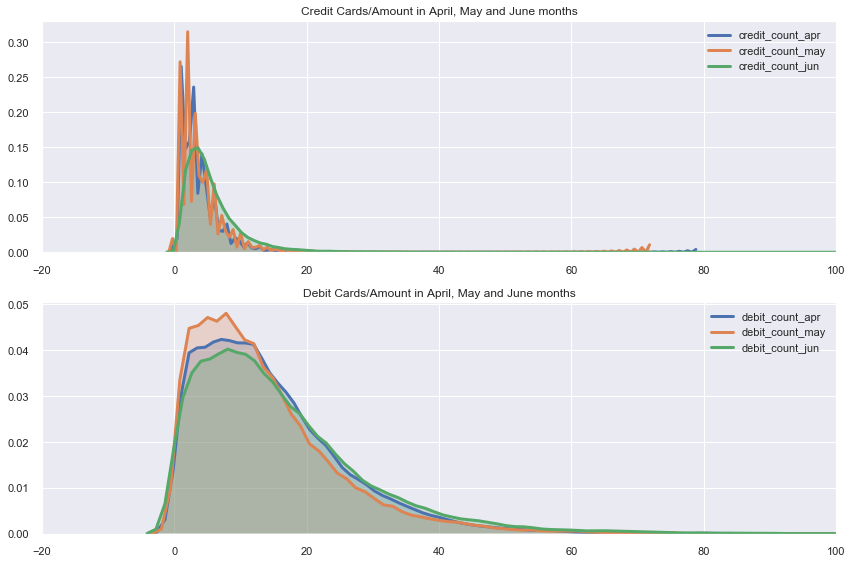

In [334]:
cc_dc_pattern(cc_spent,'credit_count_apr','credit_count_may','credit_count_jun',
              'debit_count_apr','debit_count_may','debit_count_jun',-20,100)

<font color='red pink'><b>Total number of credit transactions in April , May and June months</font></b>


In [335]:
cc_spent[cc_amt_nof_lst].describe()

,credit_count_apr,credit_count_may,credit_count_jun
count,46828.000000,46828.000000,46828.000000
mean,3.737662,4.018264,5.749092
std,3.414119,3.773425,4.645851
min,0.000000,0.000000,0.000000
25%,2.000000,2.000000,3.000000
50%,3.000000,3.000000,5.000000
75%,5.000000,5.000000,7.000000
max,78.000000,71.000000,117.000000


1. We see that the mean and median values almost being similar to each other.
2. The IQR range lies between 3-4 that means 3-4 credit transactions are carried out monthly
by most customers.
3. Also, for June month we see the difference between 3rd Quartile and maximum value being 117 . A 
difference of 110 amounting to. Which means there are few people who are carring out huge credit 
transactions.

<b><font color='dark pink'>Total number of credit transactions in April , May and June months</font></b>

In [336]:
cc_spent[dc_amt_nof_lst].describe()

,debit_count_apr,debit_count_may,debit_count_jun
count,46828.000000,46828.000000,46828.000000
mean,14.744246,13.689492,16.010387
std,11.421842,11.262676,13.159803
min,0.000000,0.000000,0.000000
25%,6.000000,6.000000,7.000000
50%,12.000000,11.000000,13.000000
75%,20.000000,18.200000,22.000000
max,147.000000,171.000000,164.000000


1. The mean values are greater than the median which means the data is mostly right skewed.
2. Debit transactions are in the range 12-15. We infer this through IQR's
3. However, the maximum debit transactions carried out is almost similar in all three. Hence,
we can observe all three months overlapping each other with slight deviations in it.

<b><font color='dark pink'> Understanding the Debit/Credit Transactions carried out on a average basis /month</font></b>

In [337]:
cc_trans_lst = ['credit_count_apr','credit_count_may','credit_count_jun']

In [338]:
cc_spent['cc_nof_trans_monthly_avg'] = (cc_spent['credit_count_apr'] + cc_spent['credit_amount_may']
                                             + cc_spent['credit_count_jun']) /3

cc_spent['cc_nof_trans_std'] = cc_spent[cc_trans_lst].std(axis=1)

In [339]:
# Finding the correlation matrix w.r.t target cc_cons
cc_trans_corr_lst = ['cc_nof_trans_monthly_avg','cc_nof_trans_std','cc_cons']
cc_spent[cc_trans_corr_lst].corr()

,cc_nof_trans_monthly_avg,cc_nof_trans_std,cc_cons
cc_nof_trans_monthly_avg,1.000000,0.102508,0.091297
cc_nof_trans_std,0.102508,1.000000,-0.001918
cc_cons,0.091297,-0.001918,1.000000


The no of credit transactions carried out has no relation with the credit card spent.

##### <font color='green'> Calculating the weighted average amount spent with respect to transactions</font>

In [340]:
cc_spent['credit_amt_weighted_average'] = (( cc_spent['credit_amount_apr'] * cc_spent['credit_count_apr'])
                                               + (cc_spent['credit_amount_may'] * cc_spent['credit_count_may'])
                                               + (cc_spent['credit_amount_jun'] * cc_spent['credit_count_jun']) / 3)

In [341]:
cc_spent['credit_amt_weighted_average'].head()


0    2.723651e+06
1    2.604658e+05
2    2.936700e+04
3    8.796967e+04
4    1.884553e+05
Name: credit_amt_weighted_average, dtype: float64

##### <font color='green'> Relationship of "weighted average of credit amount" with the "credit card spent for next 3 months"</font>

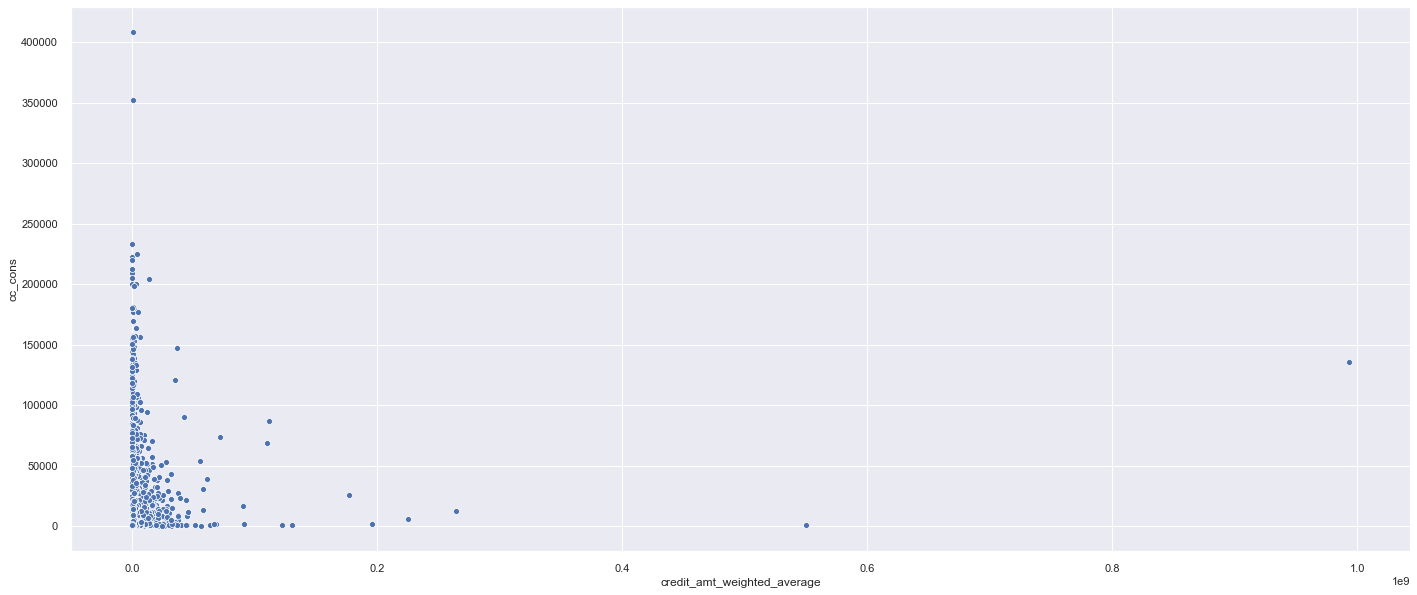

In [342]:
ax = sns.scatterplot(x='credit_amt_weighted_average', y='cc_cons', data=cc_spent)
plt.show()

When visualizing the above graph we see a dense region around 0 to 100000 in x-axis and across y-axis
from 0 to 150000. So, the credit amount spent will also be based on these figures.

##### <font color='green'> Debit Transactions</font>

In [343]:
# Debit transactions
dc_trans_lst = ['debit_count_apr','debit_count_may','debit_count_jun']

cc_spent['dc_nof_trans_monthly_avg'] = (cc_spent['debit_count_apr'] + cc_spent['debit_amount_may']
                                             + cc_spent['debit_count_jun']) / 3

cc_spent['dc_nof_trans_std'] = cc_spent_train[dc_trans_lst].std(axis=1)

In [344]:
# Finding the correlation matrix w.r.t target cc_cons
dc_trans_corr_lst = ['dc_nof_trans_monthly_avg','dc_nof_trans_std','cc_cons']
cc_spent[dc_trans_corr_lst].corr()

,dc_nof_trans_monthly_avg,dc_nof_trans_std,cc_cons
dc_nof_trans_monthly_avg,1.000000,0.031977,0.093524
dc_nof_trans_std,0.031977,1.000000,-0.019977
cc_cons,0.093524,-0.019977,1.000000


We don't observe any correlation amongthe debit transactions and the credit card being spent for next 3 months.

<b><font color='dark pink'> Understanding Maximum amount credited for April, May and June</font></b>

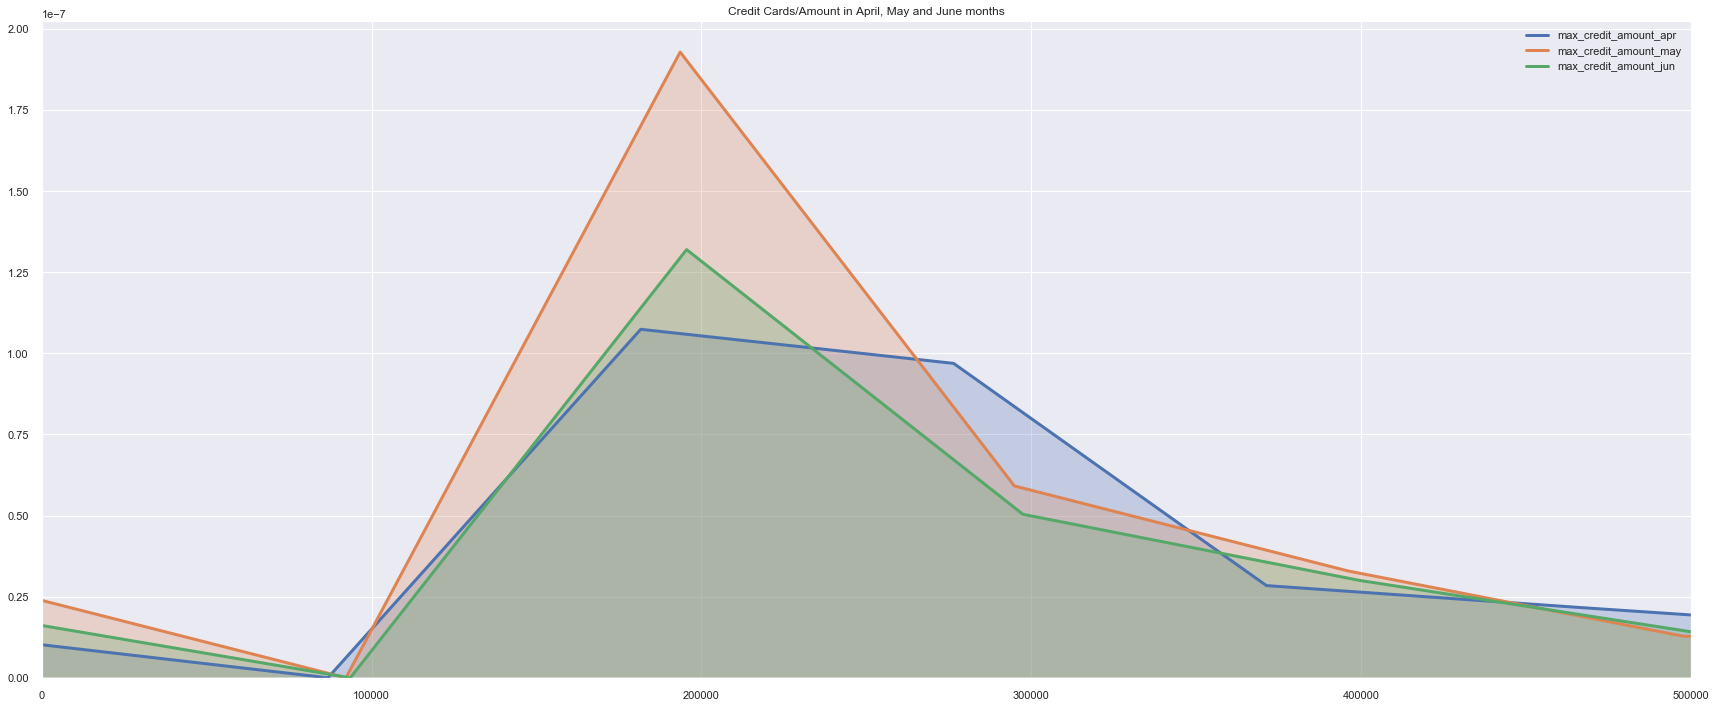

In [345]:
sns.set()
sns.distplot(cc_spent[['max_credit_amount_apr']], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label='max_credit_amount_apr')
sns.distplot(cc_spent['max_credit_amount_may'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='max_credit_amount_may')
sns.distplot(cc_spent['max_credit_amount_jun'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='max_credit_amount_jun')
plt.xlabel("")
plt.title("Credit Cards/Amount in April, May and June months")
plt.xlim(0, 500000)
    
print("")
plt.tight_layout()
plt.show()
    

In [346]:
max_credit_amt_lst = ['max_credit_amount_apr','max_credit_amount_may','max_credit_amount_jun']
cc_spent[max_credit_amt_lst].describe()

,max_credit_amount_apr,max_credit_amount_may,max_credit_amount_jun
count,4.682800e+04,4.682800e+04,4.682800e+04
mean,4.356528e+04,4.692513e+04,4.418104e+04
std,1.046284e+05,1.116228e+05,1.096876e+05
min,1.800000e-01,1.500000e-01,6.000000e-02
25%,1.626750e+04,1.678075e+04,1.625577e+04
50%,2.685600e+04,2.919800e+04,2.700000e+04
75%,4.575025e+04,5.000000e+04,4.692338e+04
max,1.202915e+07,1.285103e+07,1.293238e+07


We see that the mean is lying in the same range, while the deviation is more in the max_credit_amount for June.That
means customers have more amount credited to their accounts in the June month.
Also,  we see the min amount to be 0.06 and maximum amount to be 5.20e+06 for Month June. The amount being credited for most customers is lying in the range of 29000+ to 33000+ for months of April, May and June. 

#### <font color='dark pink'> Finding the mean and standard deviation of max_credit_amount</font>

In [347]:

max_cc_amt = ['max_credit_amount_apr','max_credit_amount_may','max_credit_amount_jun']
# Finding Mean
cc_spent['cc_max_amt_monthly_avg'] = (cc_spent['max_credit_amount_apr'] + cc_spent['max_credit_amount_may']
                                           + cc_spent['max_credit_amount_jun']) / 3

# Finding Std.
cc_spent['cc_max_amt_monthly_std'] = cc_spent[max_cc_amt].std(axis=1)

In [348]:
# Finding the correlation w.r.t target
max_cc_amt_avg_std_lst = ['cc_max_amt_monthly_avg','cc_max_amt_monthly_std','cc_cons']
cc_spent[max_cc_amt_avg_std_lst].corr()

,cc_max_amt_monthly_avg,cc_max_amt_monthly_std,cc_cons
cc_max_amt_monthly_avg,1.000000,0.882904,0.111711
cc_max_amt_monthly_std,0.882904,1.000000,0.077073
cc_cons,0.111711,0.077073,1.000000


Even maximum amount being credited to account on a monthly basis makes it difficult to predict the 
credit card spent for next 3 months.

In [349]:
cc_tot_max_corr_lst = ['cc_max_amt_monthly_std','cc_max_amt_monthly_avg',
                       'cc_amount_monthly_avg','cc_amount_monthly_std']
cc_spent[cc_tot_max_corr_lst].corr()

,cc_max_amt_monthly_std,cc_max_amt_monthly_avg,cc_amount_monthly_avg,cc_amount_monthly_std
cc_max_amt_monthly_std,1.000000,0.882904,0.695141,0.807249
cc_max_amt_monthly_avg,0.882904,1.000000,0.878951,0.811188
cc_amount_monthly_avg,0.695141,0.878951,1.000000,0.893329
cc_amount_monthly_std,0.807249,0.811188,0.893329,1.000000


As you can observe that the total credit amount (average) is highly correlated with maximum credit amount(avg). 

Let us see the credit amount balance left on subtracting the maximum credit amount with total credit amount.

In [350]:
cc_spent['credit_amount_balance'] = cc_spent['cc_max_amt_monthly_avg'] - cc_spent['cc_amount_monthly_avg']

##### <font color='green'> Credit Card Limit over EMI Active / Debt  visualization</font>

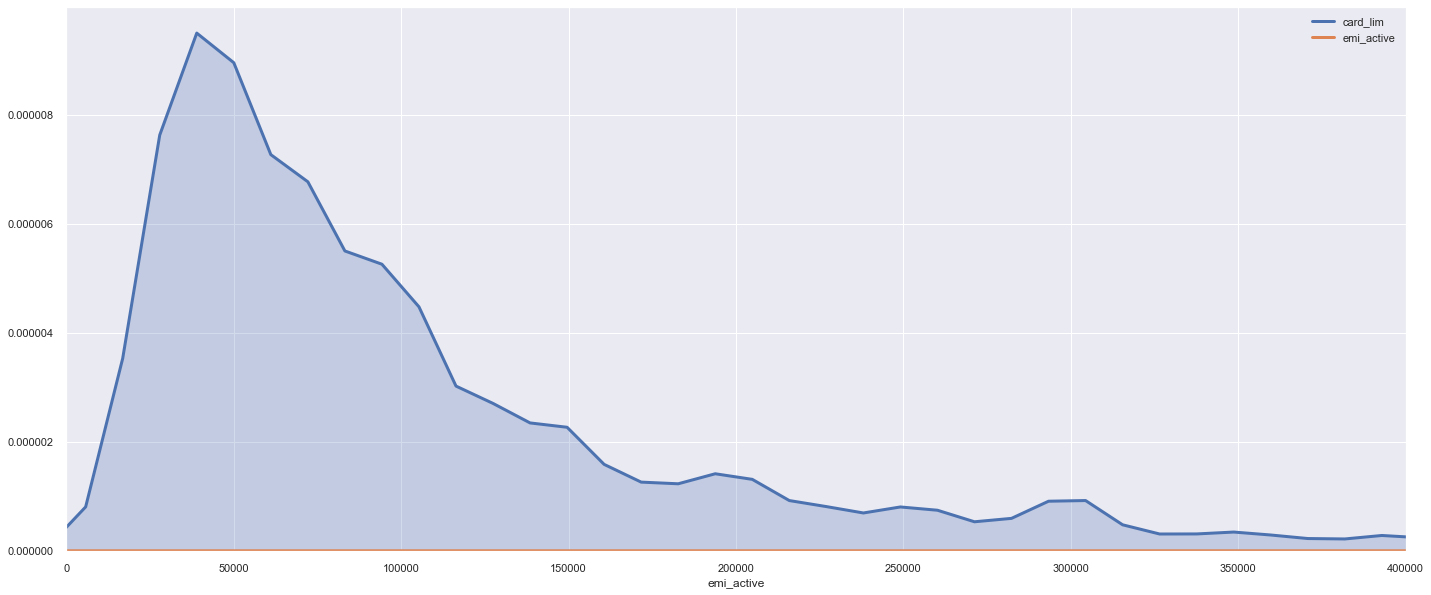

(400000, 1400000)

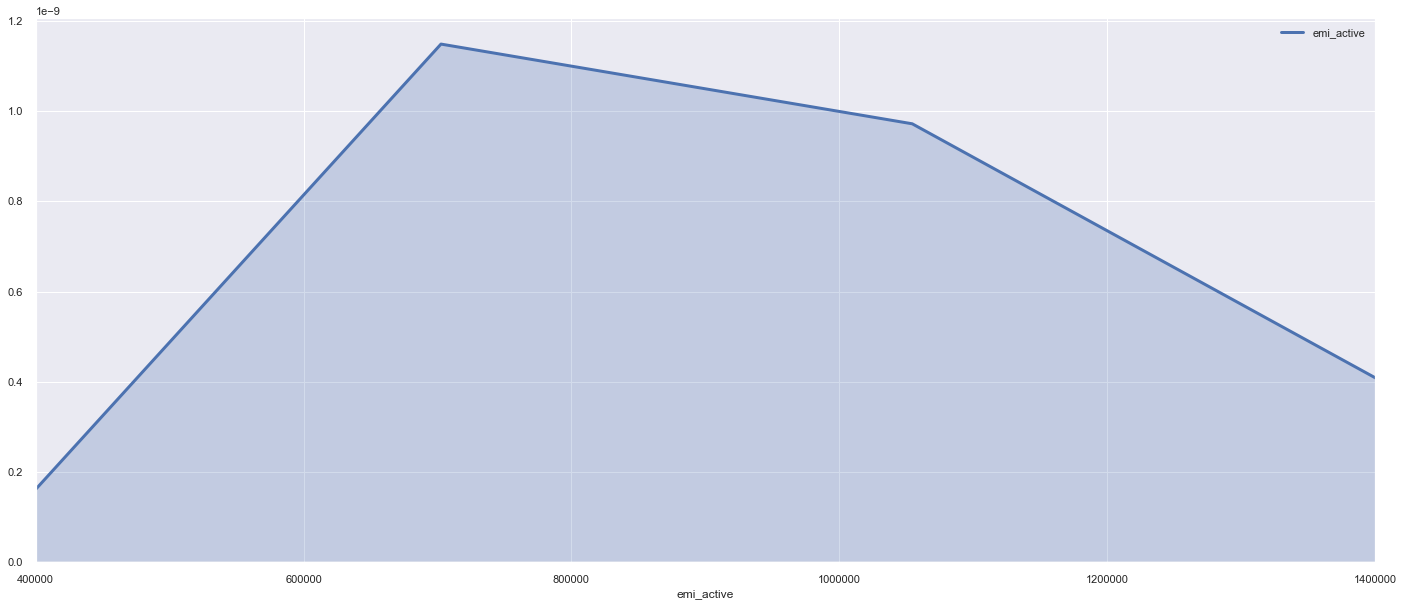

In [351]:
ax1 = sns.distplot(cc_spent['card_lim'], hist=False, kde=True, kde_kws={'shade':True,'linewidth':3},
                       label='card_lim')
ax1 = sns.distplot(cc_spent['emi_active'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='emi_active')
ax1.set_xlim(0,400000)
plt.show()
   
ax2 = sns.distplot(cc_spent['emi_active'],hist=False,kde=True,kde_kws={'shade':True, 'linewidth':3},
             label='emi_active')
plt.xlim(400000, 1400000)

Since, emi_active is present in the higher range,for better visualization created any subplot. 
Above graph gives us a comparison of credit card limit allocated to users and the debt 
being transferred as other banks. Majority of the users account for 50000 as the card limit.
When comes to credit debts, huge EMI's are active ranging from 400000 - 1400000. Will the help
of card_limit and emi_active, we can calcuate the credit_utilization.

<b> Credit_Utilization = EMI_active / Card_lim </b>

In [352]:
cc_spent['credit_utilization'] = cc_spent['emi_active'] / cc_spent['card_lim']

#### Checking for null values in the feature

In [353]:
cc_spent['credit_utilization'].isnull().sum()

1

We observe there is one null value will impute it using mean.

In [354]:
cc_spent['credit_utilization'] = cc_spent['credit_utilization'].fillna(cc_spent['credit_utilization'].mean())

Checking the null values upon imputation

In [355]:
cc_spent['credit_utilization'].isnull().sum()

0

##### <font color='green'> Plotting of credit_utilization with age</font>

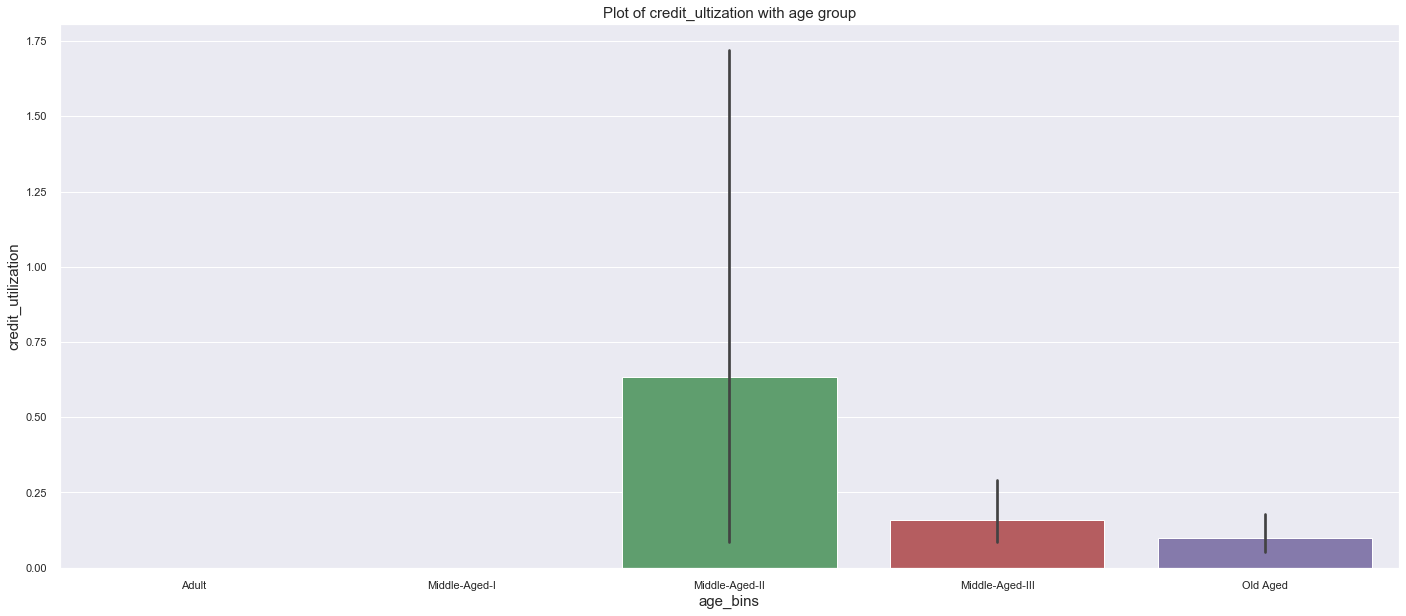

In [356]:
fig, ax = plt.subplots(figsize=(24,10))
sns.barplot('age_bins','credit_utilization',data=cc_spent, ax=ax)
#ax.set_ylim(0,350000)
ax.set_xlabel('age_bins',fontsize=15)
ax.set_ylabel('credit_utilization', fontsize=15)
plt.title("Plot of credit_ultization with age group",fontsize=15)
plt.show()

Consumers with zero emi_active, have zero credit ultization. Credit Ultization increases from 
Middle-Aged-II i.e 41 and 51 and then again falls drastically from Middle-Aged-III and Old Aged groups
accordingly. This concludes that the middle aged-II spends maximum credit amount.

In [357]:
# Correcting data types, converting into categorical variables
cc_spent.loc[:, ['account_type','gender','personal_loan_active','vehicle_loan_active',
                'personal_loan_closed','vehicle_loan_closed']] = cc_spent.loc[:, ['account_type','gender','personal_loan_active','vehicle_loan_active',
                'personal_loan_closed','vehicle_loan_closed']].astype('category')

# Due to merging there are NaN values in cc_cons for test set observations
cc_spent['cc_cons'] = cc_spent['cc_cons'].dropna().astype('int') # Converting without dropping NaN throws an error

In [358]:
# Check if the data types are corrected
cc_spent.dtypes

account_type                   category
gender                         category
age                               int64
region_code                       int64
cc_cons_apr                     float64
dc_cons_apr                     float64
cc_cons_may                     float64
dc_cons_may                     float64
cc_cons_jun                     float64
dc_cons_jun                     float64
cc_count_apr                    float64
cc_count_may                    float64
cc_count_jun                    float64
dc_count_apr                    float64
dc_count_may                    float64
dc_count_jun                    float64
card_lim                        float64
personal_loan_active           category
vehicle_loan_active            category
personal_loan_closed           category
vehicle_loan_closed            category
investment_1                    float64
investment_2                    float64
debit_amount_apr                float64
credit_amount_apr               float64


In [359]:
# Let us see the features
pd.set_option('display.max_columns',70)
cc_spent.head()

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,age_bins,cc_spent_monthly_average,cc_spent_monthly_deviation,cc_spent_ratio,dc_spent_monthly_average,dc_spent_monthly_deviation,cc_trans_monthly_avg,cc_trans_monthly_deviation,weighted_avg_cc_cons,dc_trans_monthly_avg,dc_trans_monthly_deviation,cc_amount_monthly_avg,cc_amount_monthly_std,emi_bins,dc_amt_monthly_avg,dc_amt_monthly_std,cc_nof_trans_monthly_avg,cc_nof_trans_std,credit_amt_weighted_average,dc_nof_trans_monthly_avg,dc_nof_trans_std,cc_max_amt_monthly_avg,cc_max_amt_monthly_std,credit_amount_balance,credit_utilization
0,saving,M,63,305,7695.00,988.720000,479.00,17332.577983,622.0,2806.240000,11.0,14.0,11.0,1.0,4.629295,6.000000,150000.0,0.0,0.0,0.0,0.0,7343.159851,158811.407640,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,N,0.00,435,Old Aged,2932.000000,4125.498637,1.95,7042.512661,8957.674251,12.0,1.732051,2727.583333,3.876432,2.583622,133269.333333,67488.062125,NaN,128063.756667,28456.590434,58207.666667,1.527525,2.723651e+06,34380.616667,0.577350,82333.333333,62420.616252,-50936.000000,0.000000
1,current,M,33,326,52702.00,3215.520000,29873.00,1607.000000,1087.0,355.000000,6.0,9.0,6.0,3.0,2.000000,14.000000,176000.0,0.0,0.0,1.0,0.0,3100.260107,69058.171405,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,N,4963.33,1921,Middle-Aged-I,27887.333333,25864.729079,15.85,1725.840000,1433.958115,7.0,1.732051,28171.000000,6.333333,6.658328,30430.303333,8005.792044,NaN,37864.850000,19694.622491,7687.000000,2.000000,2.604658e+05,5106.000000,5.507571,15433.333333,4764.801500,-14996.970000,0.028201
2,current,M,44,264,10800.49,682.370705,21659.64,2856.047536,1168.0,2303.682020,9.0,6.0,6.0,1.0,5.825107,1.414839,65000.0,0.0,0.0,0.0,0.0,2738.464719,132442.000000,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,N,0.00,1970,Middle-Aged-II,11209.376667,10251.937315,17.25,1947.366754,1129.795631,7.0,1.732051,11150.964286,2.746649,2.674080,9789.000000,8834.100124,NaN,8922.953333,9202.510772,6511.000000,1.154701,2.936700e+04,6454.746667,6.244998,8866.666667,9184.951461,-922.333333,0.000000
3,saving,M,44,233,20936.00,2077.719480,2094.00,765.380126,11778.5,9853.991974,2.0,7.0,9.0,1.0,1.601836,5.774726,600000.0,0.0,0.0,0.0,0.0,1521.783804,106220.624425,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,N,1238.18,21579,Middle-Aged-II,11602.833333,9422.228244,1.93,4232.363860,4912.492813,6.0,3.605551,9029.805556,2.792187,2.600424,22316.000000,27222.369460,NaN,13367.016667,11105.918762,1066.333333,1.527525,8.796967e+04,2490.333333,0.577350,19333.333333,22501.851776,-2982.666667,0.002064
4,saving,F,35,324,1183.83,1371.000000,3656.29,2220.000000,945.0,1451.559255,14.0,8.0,11.0,4.0,5.000000,2.000000,100000.0,0.0,0.0,0.0,0.0,6283.270598,84428.944809,7717.72,7792.0,17.0,4.0,3000.0,25958.50,26620.0,3.0,22.0,20603.0,31189.26,33183.13,7.0,31.0,20890.0,N,0.00,1814,Middle-Aged-I,1928.373333,1501.176854,1.93,1680.853085,468.649117,11.0,3.000000,1703.604242,3.666667,1.527525,22531.710000,13180.021131,NaN,21621.826667,12322.067570,8877.000000,2.081666,1.884553e+05,8668.833333,1.527525,14831.000000,10246.951400,-7700.710000,0.000000


In [360]:
# Creating a copy of df "cc_spent" to df "credit_card_spent"
credit_card_spent = cc_spent.copy()

In [361]:
# Binary cols
bin_cols = cc_spent.nunique()[cc_spent.nunique()==2].keys().tolist()

# Label Encoding Binary cols
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for i in bin_cols:
    cc_spent[i] = le.fit_transform(cc_spent[i])

In [362]:
cc_spent.head()

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,age_bins,cc_spent_monthly_average,cc_spent_monthly_deviation,cc_spent_ratio,dc_spent_monthly_average,dc_spent_monthly_deviation,cc_trans_monthly_avg,cc_trans_monthly_deviation,weighted_avg_cc_cons,dc_trans_monthly_avg,dc_trans_monthly_deviation,cc_amount_monthly_avg,cc_amount_monthly_std,emi_bins,dc_amt_monthly_avg,dc_amt_monthly_std,cc_nof_trans_monthly_avg,cc_nof_trans_std,credit_amt_weighted_average,dc_nof_trans_monthly_avg,dc_nof_trans_std,cc_max_amt_monthly_avg,cc_max_amt_monthly_std,credit_amount_balance,credit_utilization
0,1,1,63,305,7695.00,988.720000,479.00,17332.577983,622.0,2806.240000,11.0,14.0,11.0,1.0,4.629295,6.000000,150000.0,0,0,0,0,7343.159851,158811.407640,159050.76,169812.0,20.0,9.0,70000.0,103102.85,174606.0,6.0,10.0,150000.0,122037.66,55390.00,8.0,19.0,27000.0,0,0.00,435,Old Aged,2932.000000,4125.498637,1.95,7042.512661,8957.674251,12.0,1.732051,2727.583333,3.876432,2.583622,133269.333333,67488.062125,NaN,128063.756667,28456.590434,58207.666667,1.527525,2.723651e+06,34380.616667,0.577350,82333.333333,62420.616252,-50936.000000,0.000000
1,0,1,33,326,52702.00,3215.520000,29873.00,1607.000000,1087.0,355.000000,6.0,9.0,6.0,3.0,2.000000,14.000000,176000.0,0,0,1,0,3100.260107,69058.171405,51484.55,38942.0,16.0,4.0,11700.0,15283.00,23051.0,2.0,7.0,13800.0,46827.00,29297.91,6.0,19.0,20800.0,0,4963.33,1921,Middle-Aged-I,27887.333333,25864.729079,15.85,1725.840000,1433.958115,7.0,1.732051,28171.000000,6.333333,6.658328,30430.303333,8005.792044,NaN,37864.850000,19694.622491,7687.000000,2.000000,2.604658e+05,5106.000000,5.507571,15433.333333,4764.801500,-14996.970000,0.028201
2,0,1,44,264,10800.49,682.370705,21659.64,2856.047536,1168.0,2303.682020,9.0,6.0,6.0,1.0,5.825107,1.414839,65000.0,0,0,0,0,2738.464719,132442.000000,1981.07,2294.0,2.0,1.0,2000.0,19361.24,19529.0,1.0,1.0,19300.0,5426.55,7544.00,3.0,1.0,5300.0,0,0.00,1970,Middle-Aged-II,11209.376667,10251.937315,17.25,1947.366754,1129.795631,7.0,1.732051,11150.964286,2.746649,2.674080,9789.000000,8834.100124,NaN,8922.953333,9202.510772,6511.000000,1.154701,2.936700e+04,6454.746667,6.244998,8866.666667,9184.951461,-922.333333,0.000000
3,1,1,44,233,20936.00,2077.719480,2094.00,765.380126,11778.5,9853.991974,2.0,7.0,9.0,1.0,1.601836,5.774726,600000.0,0,0,0,0,1521.783804,106220.624425,6462.00,10271.0,6.0,1.0,10000.0,7461.00,3194.0,2.0,3.0,3000.0,26178.05,53483.00,4.0,4.0,45000.0,0,1238.18,21579,Middle-Aged-II,11602.833333,9422.228244,1.93,4232.363860,4912.492813,6.0,3.605551,9029.805556,2.792187,2.600424,22316.000000,27222.369460,NaN,13367.016667,11105.918762,1066.333333,1.527525,8.796967e+04,2490.333333,0.577350,19333.333333,22501.851776,-2982.666667,0.002064
4,1,0,35,324,1183.83,1371.000000,3656.29,2220.000000,945.0,1451.559255,14.0,8.0,11.0,4.0,5.000000,2.000000,100000.0,0,0,0,0,6283.270598,84428.944809,7717.72,7792.0,17.0,4.0,3000.0,25958.50,26620.0,3.0,22.0,20603.0,31189.26,33183.13,7.0,31.0,20890.0,0,0.00,1814,Middle-Aged-I,1928.373333,1501.176854,1.93,1680.853085,468.649117,11.0,3.000000,1703.604242,3.666667,1.527525,22531.710000,13180.021131,NaN,21621.826667,12322.067570,8877.000000,2.081666,1.884553e+05,8668.833333,1.527525,14831.000000,10246.951400,-7700.710000,0.000000


In [363]:
num_cols = []

for cols in cc_spent.select_dtypes(["int64","float64"]):
    num_cols.append(cols)

In [364]:
# Replacing infinite values present in the features with null values
cc_spent = cc_spent.replace([np.inf,-np.inf],np.nan)

In [365]:
cc_spent.isnull().sum()

account_type                       0
gender                             0
age                                0
region_code                        0
cc_cons_apr                        0
dc_cons_apr                        0
cc_cons_may                        0
dc_cons_may                        0
cc_cons_jun                        0
dc_cons_jun                        0
cc_count_apr                       0
cc_count_may                       0
cc_count_jun                       0
dc_count_apr                       0
dc_count_may                       0
dc_count_jun                       0
card_lim                           0
personal_loan_active               0
vehicle_loan_active                0
personal_loan_closed               0
vehicle_loan_closed                0
investment_1                       0
investment_2                       0
debit_amount_apr                   0
credit_amount_apr                  0
debit_count_apr                    0
credit_count_apr                   0
m

In [366]:
# let us now replace null values by mean
cols = ['cc_spent_ratio','credit_utilization','dc_nof_trans_std']
cc_spent[cols] = cc_spent[cols].fillna(cc_spent[cols].mean())

In [367]:
cc_spent.isnull().sum()

account_type                       0
gender                             0
age                                0
region_code                        0
cc_cons_apr                        0
dc_cons_apr                        0
cc_cons_may                        0
dc_cons_may                        0
cc_cons_jun                        0
dc_cons_jun                        0
cc_count_apr                       0
cc_count_may                       0
cc_count_jun                       0
dc_count_apr                       0
dc_count_may                       0
dc_count_jun                       0
card_lim                           0
personal_loan_active               0
vehicle_loan_active                0
personal_loan_closed               0
vehicle_loan_closed                0
investment_1                       0
investment_2                       0
debit_amount_apr                   0
credit_amount_apr                  0
debit_count_apr                    0
credit_count_apr                   0
m

#### <font color='green'> Scaling Features</font>

In [368]:
from sklearn.preprocessing import MinMaxScaler
minmax = MinMaxScaler()
cc_spent[num_cols] = minmax.fit_transform(cc_spent[num_cols].values)

In [369]:
cc_spent.head()

,account_type,gender,age,region_code,cc_cons_apr,dc_cons_apr,cc_cons_may,dc_cons_may,cc_cons_jun,dc_cons_jun,cc_count_apr,cc_count_may,cc_count_jun,dc_count_apr,dc_count_may,dc_count_jun,card_lim,personal_loan_active,vehicle_loan_active,personal_loan_closed,vehicle_loan_closed,investment_1,investment_2,debit_amount_apr,credit_amount_apr,debit_count_apr,credit_count_apr,max_credit_amount_apr,debit_amount_may,credit_amount_may,credit_count_may,debit_count_may,max_credit_amount_may,debit_amount_jun,credit_amount_jun,credit_count_jun,debit_count_jun,max_credit_amount_jun,loan_enq,emi_active,cc_cons,age_bins,cc_spent_monthly_average,cc_spent_monthly_deviation,cc_spent_ratio,dc_spent_monthly_average,dc_spent_monthly_deviation,cc_trans_monthly_avg,cc_trans_monthly_deviation,weighted_avg_cc_cons,dc_trans_monthly_avg,dc_trans_monthly_deviation,cc_amount_monthly_avg,cc_amount_monthly_std,emi_bins,dc_amt_monthly_avg,dc_amt_monthly_std,cc_nof_trans_monthly_avg,cc_nof_trans_std,credit_amt_weighted_average,dc_nof_trans_monthly_avg,dc_nof_trans_std,cc_max_amt_monthly_avg,cc_max_amt_monthly_std,credit_amount_balance,credit_utilization
0,1,1,0.82,0.212865,0.009274,0.002673,0.000337,0.019000,0.001330,0.009217,0.009891,0.021667,0.015337,1.562212e-09,0.037805,0.048544,0.111111,0.0,0.0,0.0,0.0,0.000087,0.011675,0.011750,0.012960,0.136054,0.115385,0.005819,0.004623,0.007772,0.084507,0.058480,0.011672,0.003061,0.001408,0.068376,0.115854,0.002088,0,0.000000,435,Old Aged,0.005877,0.007196,5.053264e-07,0.022009,0.017275,0.018519,0.003032,0.005131,0.035658,0.049517,0.005530,0.004647,NaN,0.005071,0.002010,0.007773,0.029233,0.002741,0.004625,0.007213,0.008890,0.009747,0.996161,0.000000e+00
1,0,1,0.22,0.237427,0.065220,0.008753,0.026648,0.001742,0.002412,0.001099,0.004946,0.013333,0.007669,2.469136e-02,0.010417,0.126214,0.130370,0.0,0.0,1.0,0.0,0.000037,0.005077,0.003803,0.002970,0.108844,0.051282,0.000973,0.000685,0.001026,0.028169,0.040936,0.001074,0.001174,0.000744,0.051282,0.115854,0.001608,0,0.000111,1921,Middle-Aged-I,0.060648,0.045152,4.343598e-06,0.005010,0.002755,0.010101,0.003032,0.057728,0.066116,0.127613,0.001259,0.000550,NaN,0.001497,0.001391,0.001026,0.038276,0.000262,0.000687,0.068811,0.001666,0.000744,0.998585,4.783759e-06
2,0,1,0.44,0.164912,0.013135,0.001836,0.019296,0.003112,0.002601,0.007553,0.007913,0.008333,0.007669,9.762005e-10,0.050262,0.004028,0.048148,0.0,0.0,0.0,0.0,0.000032,0.009736,0.000146,0.000172,0.013605,0.012821,0.000166,0.000868,0.000869,0.014085,0.005848,0.001502,0.000136,0.000191,0.025641,0.006098,0.000410,0,0.000000,1970,Middle-Aged-II,0.024044,0.017893,4.730187e-06,0.005718,0.002168,0.010101,0.003032,0.022544,0.021653,0.051251,0.000402,0.000607,NaN,0.000350,0.000650,0.000869,0.022098,0.000030,0.000868,0.078024,0.000957,0.001434,0.999535,0.000000e+00
3,1,1,0.44,0.128655,0.025733,0.005646,0.001782,0.000818,0.027307,0.032556,0.000989,0.010000,0.012270,1.562212e-09,0.006269,0.046357,0.444444,0.0,0.0,0.0,0.0,0.000018,0.007808,0.000477,0.000781,0.040816,0.012821,0.000831,0.000335,0.000142,0.028169,0.017544,0.000233,0.000656,0.001359,0.034188,0.024390,0.003480,0,0.000028,21579,Middle-Aged-II,0.024907,0.016444,4.998037e-07,0.013024,0.009468,0.008418,0.006311,0.018159,0.022217,0.049839,0.000922,0.001874,NaN,0.000526,0.000784,0.000142,0.029233,0.000089,0.000335,0.007213,0.002087,0.003514,0.999396,3.500591e-07
4,1,0,0.26,0.235088,0.001181,0.003716,0.003181,0.002414,0.002082,0.004731,0.012859,0.011667,0.015337,3.703704e-02,0.041667,0.009709,0.074074,0.0,0.0,0.0,0.0,0.000074,0.006206,0.000570,0.000592,0.115646,0.051282,0.000249,0.001164,0.001185,0.042254,0.128655,0.001603,0.000782,0.000843,0.059829,0.189024,0.001615,0,0.000000,1814,Middle-Aged-I,0.003674,0.002615,4.998037e-07,0.004866,0.000892,0.016835,0.005251,0.003015,0.033058,0.029276,0.000931,0.000907,NaN,0.000853,0.000870,0.001185,0.039839,0.000190,0.001166,0.019085,0.001601,0.001600,0.999078,0.000000e+00


#### Dropping features before model building

In [370]:
cc_spent= cc_spent.drop(["age_bins","emi_bins","region_code","cc_cons_apr","cc_cons_may","cc_cons_jun",
                         "dc_cons_apr","dc_cons_may","dc_cons_jun","cc_count_apr","cc_count_may","cc_count_jun",
                         "dc_count_apr","dc_count_may","dc_count_jun","debit_amount_apr","debit_amount_may","debit_amount_jun",
                         "credit_amount_apr","credit_amount_may","credit_amount_jun","credit_count_apr","credit_count_may","credit_count_jun",
                         "debit_count_apr","debit_count_may","debit_count_jun","max_credit_amount_apr","max_credit_amount_may",
                         "max_credit_amount_jun","emi_active","card_lim"], axis=1)

#### <font color='green'> Splitting the dataframe into train and test</font>

In [371]:
train = cc_spent.iloc[:32820,:]
test = cc_spent.iloc[32820:,:]

In [372]:
Y = train['cc_cons']
train = train.drop('cc_cons',axis=1)
X = train

#### <font color='green'> Correlation of features with target</font>

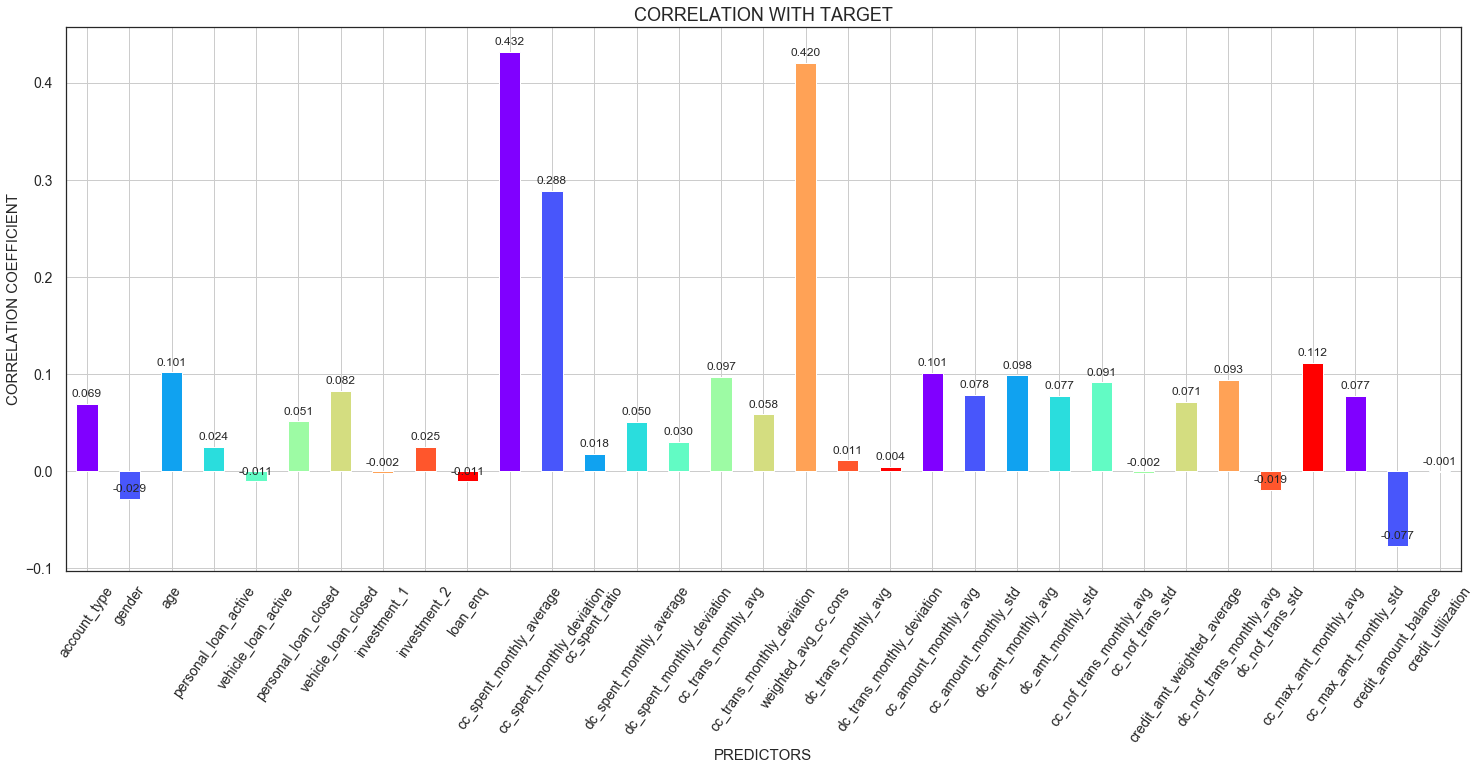

In [373]:
import matplotlib.cm as cmap
sns.set_style("white")
colors = cmap.rainbow(np.linspace(0, 1, num=10))
corr= X.corrwith(Y)
g= corr.plot.bar( figsize = (25,10), fontsize = 14,
        rot = 55, grid = True, color=colors)
for p in g.patches:
    g.annotate(format(p.get_height(), '.3f'), (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', xytext = (0, 10), textcoords = 'offset points')
plt.title("CORRELATION WITH TARGET", fontsize= 18)
plt.xlabel("PREDICTORS", fontsize= 15)
plt.ylabel("CORRELATION COEFFICIENT", fontsize= 15)
plt.show()

The above graph indicates the correlation of features with the target. Here, we see the features "cc_spent_monthly_average","cc_spent_monthly_deviation"
and "cc_trans_monthly_deviation" being highly correlated.

In [374]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.3,random_state=0)

#### <font color='green'> Model Building</font>

#### <font color='green'> Linear Regression with scikit-learn</font>

In [376]:
from sklearn.linear_model import LinearRegression

In [377]:
linreg = LinearRegression()

In [378]:
linreg.fit(X_train,Y_train)
y_pred = linreg.predict(X_test)

#### <font color='green'> Accuracy in Linear Regression</font>

In [379]:
from sklearn.metrics import r2_score, mean_squared_error

In [380]:
print("Accuracy score of model:",r2_score(Y_test,y_pred))

Accuracy score of model: 0.27815948800582835


In [381]:
rmse = np.sqrt(mean_squared_error(Y_test, y_pred))

In [382]:
print("Root Mean Square of model:",rmse )

Root Mean Square of model: 10674.362559007317


### <font color='green'> Selecting the best features using Recursive Feature Elimination(RFE)</font>

This method takes the model to be used and number of required features as input. It then gives the ranking of all variables, 1 being the most important.

In [383]:
from sklearn.feature_selection import RFE

# no of features
no_of_list = np.arange(1,64)
high_score = 0
# Variable to store the optimum features
nof=0
score_list=[]
for n in range(len(no_of_list)):
    model = LinearRegression()
    rfe = RFE(model, no_of_list[n])
    X_train_rfe = rfe.fit_transform(X_train, Y_train)
    X_test_rfe = rfe.transform(X_test)
    model.fit(X_train_rfe, Y_train)
    score = model.score(X_test_rfe, Y_test)
    score_list.append(score)

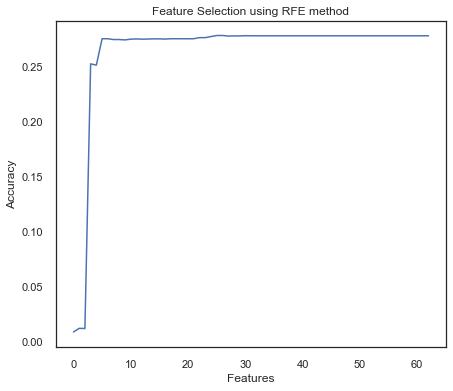

In [384]:
plt.figure(figsize=(7,6))
plt.plot(score_list)
plt.xlabel("Features")
plt.ylabel("Accuracy")
plt.title("Feature Selection using RFE method")
plt.show()

In [385]:
# Extracting the 12 best features
cols = list(X.columns)
# Initializing the RFE model
rfe = RFE(model,12)

# Transforming data using RFE
X_rfe = rfe.fit_transform(X,Y)

# Fitting the data into model
model.fit(X_rfe, Y)
temp = pd.Series(rfe.support_, index=cols)
selected_features_rfe = temp[temp==True].index
print("Selected Features are :",selected_features_rfe)

Selected Features are : Index(['cc_spent_monthly_average', 'cc_spent_monthly_deviation',
       'cc_spent_ratio', 'weighted_avg_cc_cons', 'cc_amount_monthly_avg',
       'cc_amount_monthly_std', 'dc_amt_monthly_avg', 'dc_amt_monthly_std',
       'credit_amt_weighted_average', 'cc_max_amt_monthly_avg',
       'cc_max_amt_monthly_std', 'credit_amount_balance'],
      dtype='object')


#### <font color='green'> Implementing Linear Regression through Statsmodel</font>

In [386]:
import statsmodels.api as sm

X_constant = sm.add_constant(X[selected_features_rfe])
lin_reg = sm.OLS(Y,X_constant).fit()
lin_reg.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                cc_cons   R-squared:                       0.205
Model:                            OLS   Adj. R-squared:                  0.204
Method:                 Least Squares   F-statistic:                     767.1
Date:                Sun, 03 Nov 2019   Prob (F-statistic):               0.00
Time:                        13:47:11   Log-Likelihood:            -3.5234e+05
No. Observations:               32820   AIC:                         7.047e+05
Df Residuals:                   32808   BIC:                         7.048e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
===============================================================================================
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          3.3e+04   3.38e+04      0.976      0.329   -3.33e+04    9.93e+04
cc_spent_monthly_average     1.796e+05   6743.453     26.634      0.000    1.66e+05    1.93e+05
cc_spent_monthly_deviation   -1.01e+05   4192.506    -24.099      0.000   -1.09e+05   -9.28e+04
cc_spent_ratio               3.304e+04    1.1e+04      3.002      0.003    1.15e+04    5.46e+04
weighted_avg_cc_cons         2.335e+04   6423.130      3.635      0.000    1.08e+04    3.59e+04
cc_amount_monthly_avg        1.072e+05   4.15e+04      2.580      0.010    2.58e+04    1.89e+05
cc_amount_monthly_std       -1.233e+04   3.51e+04     -0.351      0.726   -8.12e+04    5.65e+04
dc_amt_monthly_avg          -1.834e+05   7.66e+04     -2.394      0.017   -3.34e+05   -3.32e+04
dc_amt_monthly_std           2.762e+04   2.64e+04      1.047      0.295   -2.41e+04    7.93e+04
credit_amt_weighted_average -3.339e+04   2.91e+04     -1.147      0.252   -9.05e+04    2.37e+04
cc_max_amt_monthly_avg       1.764e+05   2.75e+04      6.408      0.000    1.22e+05     2.3e+05
cc_max_amt_monthly_std      -5.747e+04   1.72e+04     -3.349      0.001   -9.11e+04   -2.38e+04
credit_amount_balance       -3.083e+04   3.38e+04     -0.911      0.362   -9.72e+04    3.55e+04
==============================================================================
Omnibus:                    39012.798   Durbin-Watson:                   2.000
Prob(Omnibus):                  0.000   Jarque-Bera (JB):          8827384.205
Skew:                           6.116   Prob(JB):                         0.00
Kurtosis:                      82.407   Cond. No.                     4.80e+15
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 2.85e-27. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

#### <font color='green'> Linearity of Model</font>

Inorder to detect nonlinearity one can inspect plots of observed Vs predicted values or residual Vs predicted values.

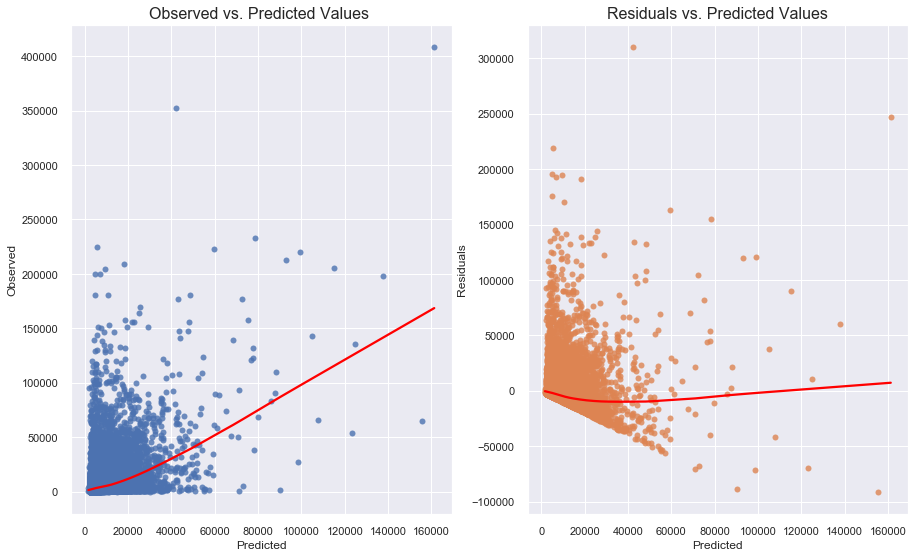

In [387]:
sns.set_style('darkgrid')
sns.mpl.rcParams['figure.figsize'] = (15.0, 9.0)

def linearity_test(model, y):
    '''
      Function for visually insepcting the assumption of linearity in a linear regression model. It plots observed Vs predicted values and residuals Vs predicted
      values .
    '''

    fitted_val = model.predict()
    resid = model.resid

    fig, ax = plt.subplots(1,2)

    sns.regplot(x=fitted_val, y=y, lowess=True, ax=ax[0], line_kws={'color':'red'})
    ax[0].set_title('Observed vs. Predicted Values ', fontsize=16)
    ax[0].set(xlabel='Predicted', ylabel='Observed')

    sns.regplot(x=fitted_val, y=resid, lowess=True, ax=ax[1], line_kws={'color':'red'})
    ax[1].set_title('Residuals vs. Predicted Values', fontsize=16)
    ax[1].set(xlabel='Predicted', ylabel='Residuals')

linearity_test(lin_reg, Y)

From the above graph, we can see that in the plot between 'Residuals' Vs. 'Predicted' the plot is lying below zero. It might be due to the data being
skewed . 

#### <font color='green'> Expectation(mean) of residuals is zero</font>

This one is easy way to check

In [388]:
lin_reg.resid.mean()

1.4856011238707357e-10

We get a residual mean in negative. However, we can assume the expectation of residuals is indeed 0.

#### <font color='green'> Homoscedasticity of residuals</font>

When residuals do not have constant variance , it is difficult to determine the true standard deviation of the forecast errors, usually resulting in confidence intervals that are too wide/narrow.

To know more if the residuals are homoscedastic, we can look at a plot of residuals vs. predicted values.

We can also use two statistical tests:- Breusch-Pagan and Goldfeld-Quandt. In both of them, the null hypothesis assumes homoscedasticity and a p-value below a certain level(like 0.05) indicates we should reject the null in favor of heteroscedasticity.

To know more if the residuals are homoscedastic, we can look at a plot of residuals vs. predicted values.

We can also take a look at what are the important coefficients.

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:17: RuntimeWarning: invalid value encountered in sqrt



 Breusch-Pagan test ----
                                     value
Lagrange multiplier statistic  1838.435700
p-value                           0.000000
f-value                         176.983253
f p-value                         0.000000

 Goldfeld-Quandt test ----
                value
F statistic  0.872381
p-value      1.000000


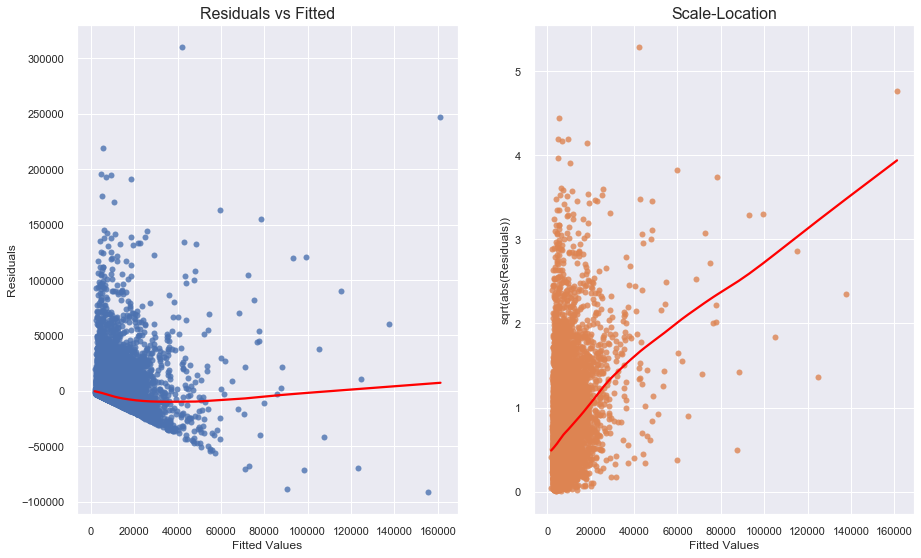

In [389]:
import statsmodels.stats.api as sms
sns.set_style('darkgrid')
sns.mpl.rcParams['figure.figsize'] = (15.0,9.0)

def homoscedasticity_test(model):

    fitted_vals = model.predict()
    resids = model.resid
    resid_std = model.get_influence().resid_studentized_internal

    fig, ax = plt.subplots(1,2)

    sns.regplot(x=fitted_vals, y=resids, lowess=True, ax=ax[0],line_kws={'color':'red'})
    ax[0].set_title('Residuals vs Fitted',fontsize=16)
    ax[0].set(xlabel='Fitted Values', ylabel='Residuals')

    sns.regplot(x=fitted_vals, y=np.sqrt(resid_std), lowess=True, ax=ax[1],line_kws={'color':'red'})
    ax[1].set_title('Scale-Location',fontsize=16)
    ax[1].set(xlabel='Fitted Values', ylabel='sqrt(abs(Residuals))')

    bp_test = pd.DataFrame(sms.het_breuschpagan(resids, model.model.exog),
                         columns=['value'],
                         index=['Lagrange multiplier statistic','p-value','f-value','f p-value'])
  
    gq_test = pd.DataFrame(sms.het_goldfeldquandt(resids, model.model.exog)[:-1],
                         columns=['value'],
                         index=['F statistic','p-value'])
  
    print("\n Breusch-Pagan test ----")
    print(bp_test)
    print("\n Goldfeld-Quandt test ----")
    print(gq_test)

homoscedasticity_test(lin_reg)

The results indicate that the assumption is not satisfied and we should reject the hypothesis of homoscedasticity.

#### <font color='green'> The features and residuals are uncorrelated</font>

Inorder to investigate this assumption we make use of Pearson correlation coefficient between each feature and the residuals.Thereby, report p-value for testing the lack of correlation between two considered series.



In [390]:
from scipy.stats.stats import pearsonr

for column in X[selected_features_rfe]:
    corr_test = pearsonr(X[column],lin_reg.resid)
    print(f'Variable: {column}---- correlation :{corr_test[0]:.4f}, p-value :{corr_test[1]:.4f}')

Variable: cc_spent_monthly_average---- correlation :0.0000, p-value :1.0000
Variable: cc_spent_monthly_deviation---- correlation :0.0000, p-value :1.0000
Variable: cc_spent_ratio---- correlation :-0.0000, p-value :1.0000
Variable: weighted_avg_cc_cons---- correlation :0.0000, p-value :1.0000
Variable: cc_amount_monthly_avg---- correlation :-0.0000, p-value :1.0000
Variable: cc_amount_monthly_std---- correlation :-0.0000, p-value :1.0000
Variable: dc_amt_monthly_avg---- correlation :-0.0000, p-value :1.0000
Variable: dc_amt_monthly_std---- correlation :-0.0000, p-value :1.0000
Variable: credit_amt_weighted_average---- correlation :-0.0000, p-value :1.0000
Variable: cc_max_amt_monthly_avg---- correlation :-0.0000, p-value :1.0000
Variable: cc_max_amt_monthly_std---- correlation :-0.0000, p-value :1.0000
Variable: credit_amount_balance---- correlation :0.0000, p-value :1.0000


From the above observation cannot reject the null hypothesis for any pair.

#### <font color='green'> Checking variability in features</font>

In [391]:
X[selected_features_rfe].apply(np.var, axis=0)

cc_spent_monthly_average       0.001355
cc_spent_monthly_deviation     0.000672
cc_spent_ratio                 0.000031
weighted_avg_cc_cons           0.001350
cc_amount_monthly_avg          0.000058
cc_amount_monthly_std          0.000120
dc_amt_monthly_avg             0.000054
dc_amt_monthly_std             0.000110
credit_amt_weighted_average    0.000054
cc_max_amt_monthly_avg         0.000091
cc_max_amt_monthly_std         0.000210
credit_amount_balance          0.000059
dtype: float64

#### <font color='green'> Normality of residuals</font>

When this assumption is violated, it causes problems with calculating confidence intervals and various significance tests for coefficients.

Some of the potential reasons causing non-normal residuals:

1. Presence of a few large outliers in data
2. There might be some other problems (violations) with the model assumptions
3. Another, better model specification might be better suited for this problem

Jarque-Bera test ---- statistic: 8827384.2047, p-value: 0.0
Shapiro-Wilk test ---- statistic: 0.5741, p-value: 0.0000
Kolmogorov-Smirnov test ---- statistic: 0.6972, p-value: 0.0000
Anderson-Darling test ---- statistic: 3362.1691, 5% critical value: 0.7870
If the returned AD statistic is larger than the critical value, then for the 5% significance level, the null hypothesis that the data come from the Normal distribution should be rejected. 


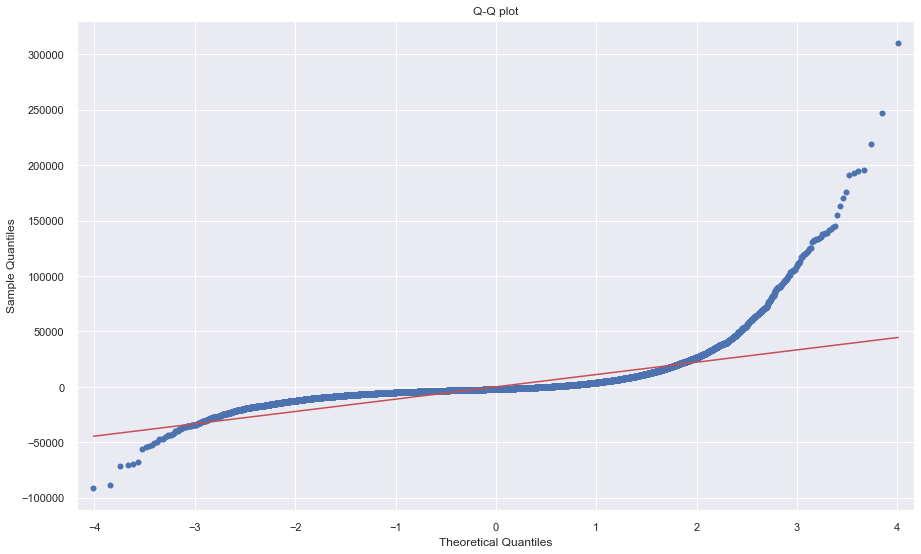

In [392]:
from scipy import stats

def normality_of_residuals_test(model):
    sm.ProbPlot(model.resid).qqplot(line='s');
    plt.title('Q-Q plot');

    jb = stats.jarque_bera(model.resid)
    sw = stats.shapiro(model.resid)
    ad = stats.anderson(model.resid, dist='norm')
    ks = stats.kstest(model.resid, 'norm')

    print(f'Jarque-Bera test ---- statistic: {jb[0]:.4f}, p-value: {jb[1]}')
    print(f'Shapiro-Wilk test ---- statistic: {sw[0]:.4f}, p-value: {sw[1]:.4f}')
    print(f'Kolmogorov-Smirnov test ---- statistic: {ks.statistic:.4f}, p-value: {ks.pvalue:.4f}')
    print(f'Anderson-Darling test ---- statistic: {ad.statistic:.4f}, 5% critical value: {ad.critical_values[2]:.4f}')
    print('If the returned AD statistic is larger than the critical value, then for the 5% significance level, the null hypothesis that the data come from the Normal distribution should be rejected. ')
    
normality_of_residuals_test(lin_reg)

Above graph indicates, that the residuals do not follow Gaussian distribution- from the shape of QQ plot.

#### <font color='green'> Potential Solutions</font>

1. Performing non-linear transformation of target variable or features
2. Remove/treat potential outliers

#### <font color='green'> Ridge Regression</font>

In Ridge Regression, the cost function is altered by adding a penalty equivalent to square of the magnitude of coefficients. It shrinks the coefficients and it helps to reduce the model complexity and multicollinearity. So, lower the constraint on the features, the model will resemble linear regression model.

In [393]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

Ridge function has an argument (alpha) that is used to tune the model. We will generate an array of alpha values ranging from very big to very small, covering the full range of scenarios from the null model containing only the intercept, to the least squares fit.

In [394]:
alphas = 10**np.linspace(10,-2,100)*0.5
alphas

array([5.00000000e+09, 3.78231664e+09, 2.86118383e+09, 2.16438064e+09,
       1.63727458e+09, 1.23853818e+09, 9.36908711e+08, 7.08737081e+08,
       5.36133611e+08, 4.05565415e+08, 3.06795364e+08, 2.32079442e+08,
       1.75559587e+08, 1.32804389e+08, 1.00461650e+08, 7.59955541e+07,
       5.74878498e+07, 4.34874501e+07, 3.28966612e+07, 2.48851178e+07,
       1.88246790e+07, 1.42401793e+07, 1.07721735e+07, 8.14875417e+06,
       6.16423370e+06, 4.66301673e+06, 3.52740116e+06, 2.66834962e+06,
       2.01850863e+06, 1.52692775e+06, 1.15506485e+06, 8.73764200e+05,
       6.60970574e+05, 5.00000000e+05, 3.78231664e+05, 2.86118383e+05,
       2.16438064e+05, 1.63727458e+05, 1.23853818e+05, 9.36908711e+04,
       7.08737081e+04, 5.36133611e+04, 4.05565415e+04, 3.06795364e+04,
       2.32079442e+04, 1.75559587e+04, 1.32804389e+04, 1.00461650e+04,
       7.59955541e+03, 5.74878498e+03, 4.34874501e+03, 3.28966612e+03,
       2.48851178e+03, 1.88246790e+03, 1.42401793e+03, 1.07721735e+03,
      

Associated with each alpha is the vector of ridge regression coefficients. Also, we will try to standardize so that they are on the same scale. 

In [439]:
ridge = Ridge(normalize = True)
coefs = []

for a in alphas:
    ridge.set_params(alpha = a)
    ridge.fit(X_train[selected_features_rfe], Y_train)
    coefs.append(ridge.coef_)
    
np.shape(coefs)

(10, 12)

We expect the coefficient estimate to be much smaller when large value of alpha is used as compared to small value of alpha.

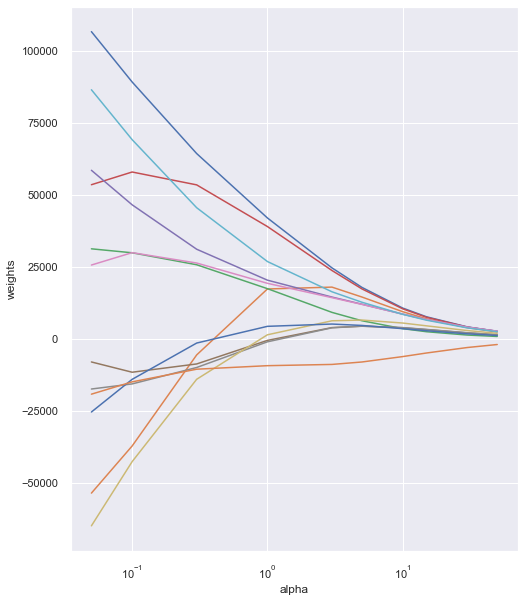

In [441]:
ax = plt.gca()
ax.plot(alphas, coefs)
ax.set_xscale('log')
plt.axis('tight')
plt.xlabel('alpha')
plt.ylabel('weights')
plt.show()

After, we obtained the coefficients in the model. Let us plot the rmse for the different values of alpha.

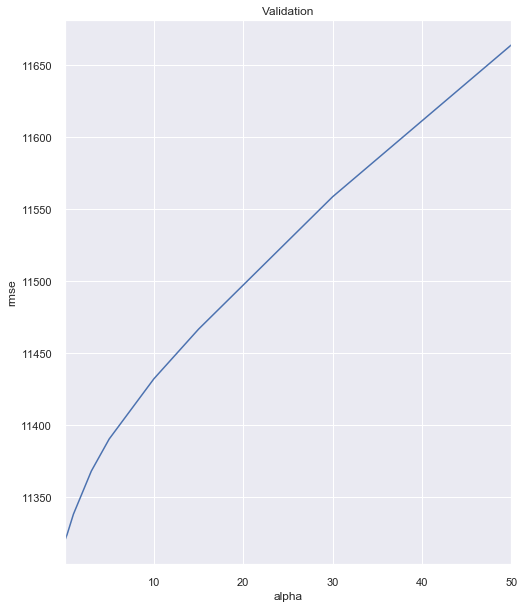

In [442]:
alphas = [0.05,0.1,0.3, 1, 3, 5, 10, 15, 30, 50]

def rmse_cv(model):
    rmse = np.sqrt(-cross_val_score(model, X_train[selected_features_rfe], Y_train,scoring='neg_mean_squared_error',cv=5))
    return(rmse)

cv_ridge = [ rmse_cv(Ridge(alpha=alpha)).mean() for alpha in alphas]
cv_ridge = pd.Series(cv_ridge, index=alphas)
cv_ridge.plot(title='Validation')
plt.xlabel("alpha")
plt.ylabel("rmse")
plt.show()

We see that as the value of alpha increases , the rmse rate also increases.

Let us find out the minimum value of rmse for ridge.

In [452]:
print("Minimum rmse in ridge :", cv_ridge.min())

Minimum rmse in ridge : 11320.9587914099


#### <font color='green'> Lasso Regression </font>

In [399]:
from sklearn.linear_model import LassoCV

In [400]:
def rmse_cv_lasso(model):
    rmse = np.sqrt(-cross_val_score(model, X_train, Y_train,scoring='neg_mean_squared_error',cv=5))
    return(rmse)

In [401]:
# Model Lasso  
model_lasso = LassoCV(alphas=[0.005, 0.001, 0.1, 1]).fit(X_train, Y_train)
print("RMSE mean of lasso regression is :",rmse_cv_lasso(model_lasso).mean())

RMSE mean of lasso regression is : 11306.51849578047


Let us look at the coefficients of the model

In [402]:
coef = pd.Series(model_lasso.coef_, index = X_train.columns)
coef

account_type                      602.108577
gender                          -1250.951809
age                              2337.127043
personal_loan_active               55.047320
vehicle_loan_active               265.637361
personal_loan_closed             1040.504753
vehicle_loan_closed              1508.091137
investment_1                       -0.000000
investment_2                        0.000000
loan_enq                         -964.506753
cc_spent_monthly_average       158970.214835
cc_spent_monthly_deviation     -74446.304849
cc_spent_ratio                  10244.753026
dc_spent_monthly_average         3576.529117
dc_spent_monthly_deviation         -0.000000
cc_trans_monthly_avg                0.000000
cc_trans_monthly_deviation      10829.462454
weighted_avg_cc_cons            13674.573233
dc_trans_monthly_avg             1265.982131
dc_trans_monthly_deviation      -1296.824653
cc_amount_monthly_avg               0.000000
cc_amount_monthly_std              -0.000000
dc_amt_mon

In [403]:
print("Lasso picked " + str(sum(coef != 0)) + " variables and eliminated the other " + str(sum(coef == 0)) + " variables")

Lasso picked 20 variables and eliminated the other 13 variables


Let us look at chart about the coefficients in the model

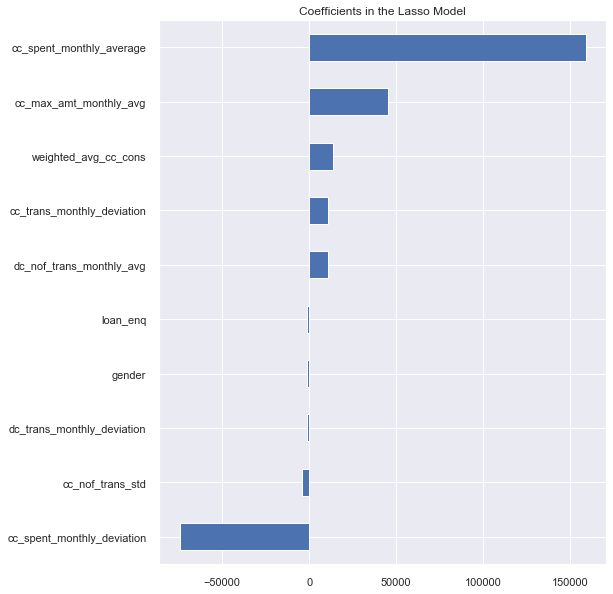

In [406]:
imp_coef = pd.concat([coef.sort_values().head(5),
                      coef.sort_values().tail(5)])
plt.rcParams['figure.figsize'] = (8.0, 10.0)
imp_coef.plot(kind='barh')
plt.title("Coefficients in the Lasso Model")
plt.show()

From above figure, we get the importances features using Lasso Regression.

Let us look at the residuals of the model in Lasso

W1103 14:07:33.952203  8140 _axes.py:4263] 'c' argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with 'x' & 'y'.  Please use a 2-D array with a single row if you really want to specify the same RGB or RGBA value for all points.


<Figure size 864x360 with 0 Axes>

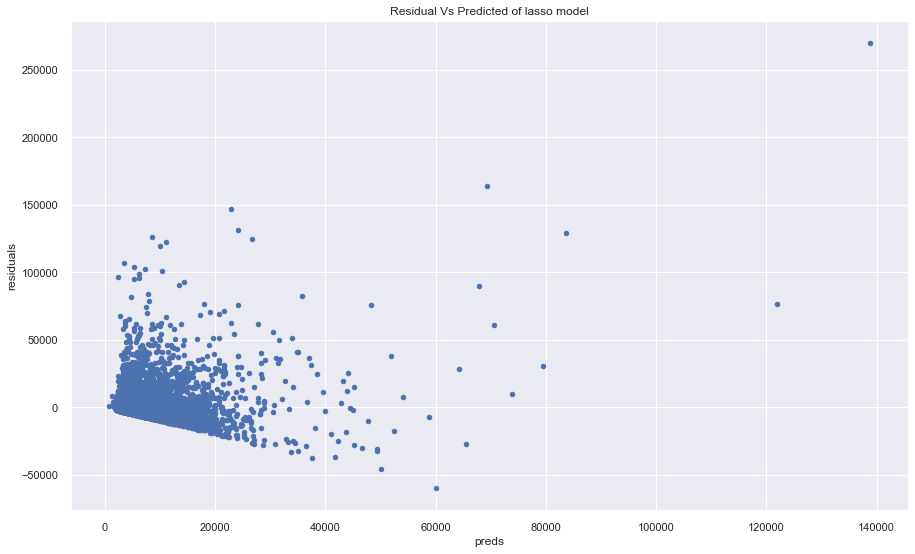

In [404]:
plt.figure(figsize=(12,5))
l_pred = pd.DataFrame({"preds":model_lasso.predict(X_test), "true":Y_test})
l_pred["residuals"] = l_pred["true"] - l_pred["preds"]
l_pred.plot(x="preds",y="residuals", kind='scatter')
plt.title("Residual Vs Predicted of lasso model")
plt.show()

Here, we see the residuals mostly lying around 0 .

#### <font color='green'> Conclusion</font>

On comparing Linear, Ridge and Lasso Regression. We observe that linear regression is the one which
gives lower rmse and high accuracy as compared to other models. Hence, linear regression should be 
choosen in the final prediction.